## 0. 필수 라이브러리 설치 및 GPU 환경 설정
필요한 패키지가 설치되어 있지 않다면 아래 코드를 실행하거나 터미널에서 pip install -r requirements.txt를 실행하세요.
(NVIDIA GPU 환경인 경우 CUDA 호환 PyTorch 설치 권장)

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import torch

warnings.filterwarnings('ignore')

# 한글 폰트 및 시각화 기본 설정 (Windows Malgun Gothic 우선 적용)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'Malgun Gothic' if os.name == 'nt' else 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# GPU 가속 환경 감지 및 모델별 디바이스 설정
# ==========================================
USE_CUDA = torch.cuda.is_available()
device = torch.device('cuda' if USE_CUDA else 'cpu')
if USE_CUDA:
    torch.backends.cudnn.benchmark = True
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"[PyTorch GPU 활성화] 디바이스: {device} ({gpu_name}, VRAM: {vram_gb:.1f} GB, CUDA: {torch.version.cuda})")
else:
    print(f"[PyTorch 디바이스] {device} (CUDA 미감지 - GPU 사용 시 CUDA 지원 PyTorch 설치 필요)")



[PyTorch GPU 활성화] 디바이스: cuda (NVIDIA GeForce RTX 5060 Ti, VRAM: 15.9 GB, CUDA: 12.8)


## 1. 전처리 데이터(`preprocessing.ipynb` 산출물: `preprocessed_citrus_data_auction_only.csv`) 및 `forecast.csv` 로드
- **`preprocessing.ipynb` 연계 전처리 데이터셋 적용**:
  - `data/kat*.csv` 전국 32개 공영도매시장 거래 데이터(약 105만 건)를 정제하고, 가격 왜곡 요인인 **수의계약(정가수의)을 제외한 순수 공개 경매 전용 데이터셋(`data/preprocessed_citrus_data_auction_only.csv`)**을 직접 로드합니다.
- **예측 대상 한정 (`하우스감귤`, `조생귤`, `천혜향`)**:
  - 전체 22개 감귤류 품종 중 **`하우스감귤`**, **`조생귤`**, **`천혜향`** 3개 핵심 품종만을 직접적인 가격 및 물량 예측 대상으로 한정합니다.
- **품종별 누적 판매량 상위 3대 판매단위 (`Transaction Unit`)**:
  - **`하우스감귤`**: `3kg상자`, `5kg상자`, `3kg파렛트`
  - **`조생귤`**: `5kg상자`, `5kg파렛트`, `10kg상자`
  - **`천혜향`**: `3kg상자`, `5kg상자`, `3kg파렛트`
- **나머지 품종 → 해당일 전체 시장 물량 데이터(`field_all_citrus_today_kg`, `field_other_citrus_today_kg`) 피처로 활용**:
  - `기타`, `비가림감귤`, `레드향`, `황금향`, `한라봉`, `온주` 등 나머지 18개 품종들은 해당일의 **전국 전체 감귤 총 물량(`field_all_citrus_today_kg`)** 및 **기타 품종 합산 물량(`field_other_citrus_today_kg`)**으로 집계하여 TFT 모델의 거시 공급 피처로 주입합니다.


In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd

TARGET_VARIETIES = ['하우스감귤', '조생귤', '천혜향']

def parse_weight_kg(kind_str):
    s = str(kind_str).strip()
    m_kg = re.search(r"(\d+(?:\.\d+)?)\s*kg", s, re.IGNORECASE)
    if m_kg:
        return float(m_kg.group(1))
    m_g = re.search(r"(\d+(?:\.\d+)?)\s*g", s, re.IGNORECASE)
    if m_g:
        return float(m_g.group(1)) / 1000.0
    return 5.0

def load_and_preprocess_weather_data(weather_path=r"data\forecast.csv"):
    candidates = [
        Path(weather_path),
        Path("data/forecast.csv"),
        Path("../data/forecast.csv")
    ]
    target_path = next((p for p in candidates if p.exists()), None)
    if target_path is None:
        raise FileNotFoundError(f"날씨 데이터 파일을 찾을 수 없습니다: {weather_path}")
        
    print(f"기상청 날씨 데이터 로드 경로: {target_path.resolve()}")
    for enc in ['cp949', 'euc-kr', 'utf-8', 'utf-8-sig']:
        try:
            wdf = pd.read_csv(target_path, encoding=enc)
            break
        except UnicodeDecodeError:
            continue
            
    wdf.columns = [c.strip() for c in wdf.columns]
    date_col = next((c for c in wdf.columns if c in ['일시', 'date', 'DATE']), wdf.columns[0])
    wdf['date'] = pd.to_datetime(wdf[date_col], errors='coerce')
    wdf = wdf.dropna(subset=['date']).copy()
    
    temp_col = next((c for c in wdf.columns if '기온' in c), None)
    rain_dur_col = next((c for c in wdf.columns if '강수' in c and '계속' in c), None)
    rain_max_col = next((c for c in wdf.columns if '최다' in c and '강수' in c), None)
    sun_col = next((c for c in wdf.columns if '일조' in c), None)
    snow_col = next((c for c in wdf.columns if '적설' in c), None)
    
    wdf['temp'] = pd.to_numeric(wdf[temp_col], errors='coerce') if temp_col else np.nan
    wdf['rain_dur'] = pd.to_numeric(wdf[rain_dur_col], errors='coerce').fillna(0.0) if rain_dur_col else 0.0
    wdf['rain_peak'] = pd.to_numeric(wdf[rain_max_col], errors='coerce').fillna(0.0) if rain_max_col else 0.0
    wdf['sun_hr'] = pd.to_numeric(wdf[sun_col], errors='coerce') if sun_col else np.nan
    wdf['is_snow'] = (pd.to_numeric(wdf[snow_col], errors='coerce') > 0).astype(int) if snow_col else 0
    
    wx_daily = wdf.groupby('date', as_index=False).agg(
        wx_temp_mean=('temp', 'mean'),
        wx_temp_max=('temp', 'max'),
        wx_temp_min=('temp', 'min'),
        wx_rain_dur=('rain_dur', 'mean'),
        wx_rain_dur_max=('rain_dur', 'max'),
        wx_rain_peak=('rain_peak', 'max'),
        wx_sun_hr=('sun_hr', 'mean'),
        wx_is_snow=('is_snow', 'max')
    ).sort_values('date').reset_index(drop=True)
    
    full_dates = pd.date_range(wx_daily['date'].min(), wx_daily['date'].max(), freq='D')
    wx_daily = wx_daily.set_index('date').reindex(full_dates).rename_axis('date').reset_index()
    
    wx_daily[['wx_temp_mean', 'wx_temp_max', 'wx_temp_min', 'wx_sun_hr']] = (
        wx_daily[['wx_temp_mean', 'wx_temp_max', 'wx_temp_min', 'wx_sun_hr']].interpolate().bfill().ffill()
    )
    wx_daily[['wx_rain_dur', 'wx_rain_dur_max', 'wx_rain_peak', 'wx_is_snow']] = (
        wx_daily[['wx_rain_dur', 'wx_rain_dur_max', 'wx_rain_peak', 'wx_is_snow']].fillna(0.0)
    )
    
    wx_daily['wx_is_rainy'] = ((wx_daily['wx_rain_dur'] > 0.5) | (wx_daily['wx_rain_peak'] > 0.5)).astype(int)
    wx_daily['wx_temp_spread'] = wx_daily['wx_temp_max'] - wx_daily['wx_temp_min']
    wx_daily['wx_temp_diff_1'] = wx_daily['wx_temp_mean'].diff(1).fillna(0.0)
    wx_daily['wx_temp_diff_3'] = wx_daily['wx_temp_mean'].diff(3).fillna(0.0)
    wx_daily['wx_temp_diff_7'] = wx_daily['wx_temp_mean'].diff(7).fillna(0.0)
    
    for lag in [1, 2, 3, 7]:
        wx_daily[f'wx_temp_lag_{lag}'] = wx_daily['wx_temp_mean'].shift(lag)
        wx_daily[f'wx_rain_dur_lag_{lag}'] = wx_daily['wx_rain_dur'].shift(lag)
        wx_daily[f'wx_sun_lag_{lag}'] = wx_daily['wx_sun_hr'].shift(lag)
        
    for w in [3, 7, 14, 30, 60]:
        wx_daily[f'wx_temp_rmean_{w}'] = wx_daily['wx_temp_mean'].rolling(w, min_periods=1).mean()
        wx_daily[f'wx_sun_rsum_{w}'] = wx_daily['wx_sun_hr'].rolling(w, min_periods=1).sum()
        wx_daily[f'wx_rain_rsum_{w}'] = wx_daily['wx_rain_dur'].rolling(w, min_periods=1).sum()
        wx_daily[f'wx_rain_peak_rmax_{w}'] = wx_daily['wx_rain_peak'].rolling(w, min_periods=1).max()
        
    wx_daily['wx_temp_anomaly_3_30'] = wx_daily['wx_temp_rmean_3'] - wx_daily['wx_temp_rmean_30']
    wx_daily = wx_daily.bfill().ffill()
    return wx_daily

def load_and_preprocess_data(
    data_path=r"data\preprocessed_citrus_data_auction_only.csv",
    fallback_path=r"data\preprocessed_citrus_data.csv",
    weather_path=r"data\forecast.csv",
    top_n_kinds=3
):
    """
    preprocessing.ipynb에 의해 전처리된 감귤 경매 데이터(preprocessed_citrus_data_auction_only.csv)와
    forecast.csv 기상 데이터를 로드하여:
    - 예측 대상 품종은 하우스감귤, 조생귤, 천혜향 3개 품종으로 한정하고,
    - 나머지 품종은 해당일의 전체 시장 물량 피처로 일별 집계하여 TFT 모델의 입력 피처로 활용합니다.
    """
    p_primary = Path(data_path)
    p_fallback = Path(fallback_path)
    if p_primary.exists():
        target_csv = p_primary
        print(f"전처리 경매 데이터 로드 (preprocessing.ipynb 전처리본): {target_csv.resolve()}")
    elif p_fallback.exists():
        target_csv = p_fallback
        print(f"전처리 전체 데이터 로드 (fallback): {target_csv.resolve()}")
    else:
        raise FileNotFoundError(f"전처리된 데이터 파일을 찾을 수 없습니다: {p_primary}, {p_fallback}")

    cols_to_use = [
        'date', 'variety', 'unit_weight', 'pkg_nm',
        'volume_kg', 'total_price', 'box_price', 'unit_price_kg',
        'whsl_mrkt_nm', 'grade'
    ]
    comb = pd.read_csv(target_csv, usecols=lambda c: c in cols_to_use, low_memory=False)
    comb['date'] = pd.to_datetime(comb['date'], errors='coerce')
    comb = comb.dropna(subset=['date']).copy()
    comb['Variety'] = comb['variety'].astype(str).str.strip()

    # 포장단위 규격(kind) 명명: 예) 3kg상자, 5kg상자, 3kg파렛트
    def make_kind(w, pkg):
        pkg_str = str(pkg).strip() if pd.notna(pkg) else '상자'
        p = '파렛트' if '파렛' in pkg_str else '상자'
        w_val = float(w) if pd.notna(w) and float(w) > 0 else 5.0
        return f"{w_val:g}kg{p}"

    comb['Transaction Unit'] = [make_kind(w, p) for w, p in zip(comb['unit_weight'], comb['pkg_nm'])]
    comb['Total Trading Volume'] = pd.to_numeric(comb['volume_kg'], errors='coerce').fillna(0.0)
    comb['Total Trading Value'] = pd.to_numeric(comb['total_price'], errors='coerce').fillna(0.0)
    comb['Wholesale Market'] = comb['whsl_mrkt_nm'].fillna('기타도매').astype(str)
    comb['Grade'] = comb['grade'].fillna('상').astype(str)
    comb['DATE'] = comb['date'].dt.strftime('%Y-%m-%d')

    comb = comb[(comb['Total Trading Volume'] > 0) & (comb['Total Trading Value'] > 0)].copy()
    print(f"전국 32개 도매시장 유효 경매: {len(comb):,}건 ({comb['date'].min().date()} ~ {comb['date'].max().date()})")

    # 1. 해당일의 전국 전체 감귤 물량 및 나머지 품종(하우스감귤·조생귤·천혜향 외 품종) 물량 일별 집계
    comb['is_target_var'] = comb['Variety'].isin(TARGET_VARIETIES)
    comb['other_var_kg'] = np.where(~comb['is_target_var'], comb['Total Trading Volume'], 0.0)
    comb['josaeng_kg'] = np.where(comb['Variety'] == '조생귤', comb['Total Trading Volume'], 0.0)
    comb['cheonhyehyang_kg'] = np.where(comb['Variety'] == '천혜향', comb['Total Trading Volume'], 0.0)
    comb['house_kg'] = np.where(comb['Variety'] == '하우스감귤', comb['Total Trading Volume'], 0.0)

    f_daily = comb.groupby('date', as_index=False).agg(
        raw_all_citrus_kg=('Total Trading Volume', 'sum'),
        raw_all_citrus_rev=('Total Trading Value', 'sum'),
        raw_other_citrus_kg=('other_var_kg', 'sum'),
        raw_field_josaeng_kg=('josaeng_kg', 'sum'),
        raw_field_geukjosaeng_kg=('other_var_kg', 'sum'),
        raw_field_onju_kg=('cheonhyehyang_kg', 'sum'),
        raw_house_kg=('house_kg', 'sum'),
        raw_field_active_types=('Variety', 'nunique')
    ).sort_values('date').reset_index(drop=True)

    f_daily['raw_field_total_kg'] = f_daily['raw_all_citrus_kg'] - f_daily['raw_house_kg']
    f_daily['raw_field_total_rev'] = f_daily['raw_all_citrus_rev']
    f_daily['raw_field_unit_price'] = f_daily['raw_all_citrus_rev'] / (f_daily['raw_all_citrus_kg'] + 1e-8)
    f_daily['raw_field_active'] = (f_daily['raw_field_total_kg'] > 0).astype(float)

    full_dates = pd.date_range(comb['date'].min(), comb['date'].max(), freq='D')
    f_daily = f_daily.set_index('date').reindex(full_dates).rename_axis('date').reset_index()
    zero_cols = [
        'raw_all_citrus_kg', 'raw_all_citrus_rev', 'raw_other_citrus_kg',
        'raw_field_total_kg', 'raw_field_total_rev',
        'raw_field_josaeng_kg', 'raw_field_geukjosaeng_kg', 'raw_field_onju_kg',
        'raw_house_kg', 'raw_field_active_types', 'raw_field_active'
    ]
    f_daily[zero_cols] = f_daily[zero_cols].fillna(0.0)
    f_daily['raw_field_unit_price'] = f_daily['raw_field_unit_price'].ffill(limit=14).fillna(0.0)

    f_daily['field_all_citrus_today_kg'] = f_daily['raw_all_citrus_kg']
    f_daily['field_other_citrus_today_kg'] = f_daily['raw_other_citrus_kg']
    f_daily['field_other_citrus_share_today'] = f_daily['raw_other_citrus_kg'] / (f_daily['raw_all_citrus_kg'] + 1e-8)
    f_daily['field_log_all_citrus_today'] = np.log1p(f_daily['raw_all_citrus_kg'])
    f_daily['field_log_other_citrus_today'] = np.log1p(f_daily['raw_other_citrus_kg'])

    f_daily['field_is_active_lag1'] = f_daily['raw_field_active'].shift(1).fillna(0.0)
    f_daily['field_active_days_7'] = f_daily['raw_field_active'].shift(1).rolling(7, min_periods=1).sum().fillna(0.0)
    f_daily['field_active_days_14'] = f_daily['raw_field_active'].shift(1).rolling(14, min_periods=1).sum().fillna(0.0)

    for lag in [1, 2, 3, 7, 14]:
        f_daily[f'field_prev_kg_{lag}'] = f_daily['raw_all_citrus_kg'].shift(lag).fillna(0.0)
        f_daily[f'field_prev_up_{lag}'] = f_daily['raw_field_unit_price'].shift(lag).fillna(0.0)
        f_daily[f'field_other_prev_kg_{lag}'] = f_daily['raw_other_citrus_kg'].shift(lag).fillna(0.0)

    for w in [3, 7, 14, 30]:
        f_daily[f'field_kg_rmean_{w}'] = f_daily['raw_all_citrus_kg'].shift(1).rolling(w, min_periods=1).mean().fillna(0.0)
        f_daily[f'field_up_rmean_{w}'] = f_daily['raw_field_unit_price'].shift(1).rolling(w, min_periods=1).mean().fillna(0.0)
        f_daily[f'field_other_kg_rmean_{w}'] = f_daily['raw_other_citrus_kg'].shift(1).rolling(w, min_periods=1).mean().fillna(0.0)

    f_daily['field_josaeng_kg_rmean_7'] = f_daily['raw_field_josaeng_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    f_daily['field_geukjosaeng_kg_rmean_7'] = f_daily['raw_other_citrus_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    f_daily['field_onju_kg_rmean_7'] = f_daily['raw_field_onju_kg'].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)

    f_daily['field_log_kg_lag1'] = np.log1p(f_daily['field_prev_kg_1'])
    f_daily['field_log_kg_rmean_7'] = np.log1p(f_daily['field_kg_rmean_7'])
    f_daily['field_log_kg_rmean_14'] = np.log1p(f_daily['field_kg_rmean_14'])

    # 2. 하우스감귤 전국 전체 시장 일별·판매단위별 집계
    ht_raw = comb[comb['Variety'] == '하우스감귤'].copy()
    df = ht_raw.groupby(['date', 'Transaction Unit'], as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum'),
        market_count=('Wholesale Market', 'nunique'),
        Grade=('Grade', 'first')
    ).sort_values(['Transaction Unit', 'date']).reset_index(drop=True)

    df['kind'] = df['Transaction Unit']
    df['type'] = '하우스감귤'
    df['total_kg'] = df['volume']
    df['weight_kg'] = df['kind'].apply(parse_weight_kg)
    df['is_pallet'] = df['kind'].str.contains('파렛트').astype(int)
    df['unit_price'] = (df['total_price'] / df['volume']).round(2)
    df['price'] = (df['unit_price'] * df['weight_kg']).round(2)
    df = df.rename(columns={'total_price': 'total price'})

    # 3. 3대 예측 품종(하우스감귤, 조생귤, 천혜향) 원본 집계 테이블 보관
    target3_raw = comb[comb['Variety'].isin(TARGET_VARIETIES)].copy()
    field_raw_df = target3_raw.groupby(['date', 'Variety', 'Transaction Unit'], as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum'),
        market_count=('Wholesale Market', 'nunique'),
        Grade=('Grade', 'first')
    ).sort_values(['Variety', 'date']).reset_index(drop=True)
    field_raw_df['kind'] = field_raw_df['Transaction Unit']
    field_raw_df['type'] = field_raw_df['Variety']
    field_raw_df['total_kg'] = field_raw_df['volume']
    field_raw_df['weight_kg'] = field_raw_df['kind'].apply(parse_weight_kg)
    field_raw_df['unitprice'] = (field_raw_df['total_price'] / field_raw_df['volume']).round(2)
    field_raw_df['price'] = (field_raw_df['unitprice'] * field_raw_df['weight_kg']).round(2)
    field_raw_df = field_raw_df.rename(columns={'total_price': 'total price'})

    # 4. 하우스감귤 시장 전체 동향 (시차 피처)
    mkt_daily = df.groupby('date', as_index=False).agg(
        mkt_total_kg=('total_kg', 'sum'),
        mkt_total_rev=('total price', 'sum'),
        mkt_active_kinds=('kind', 'nunique')
    ).sort_values('date').reset_index(drop=True)
    mkt_daily['mkt_unit_price'] = mkt_daily['mkt_total_rev'] / (mkt_daily['mkt_total_kg'] + 1e-8)

    for lag in [1, 2, 3, 7, 14]:
        mkt_daily[f'mkt_prev_kg_{lag}'] = mkt_daily['mkt_total_kg'].shift(lag)
        mkt_daily[f'mkt_prev_up_{lag}'] = mkt_daily['mkt_unit_price'].shift(lag)
    for w in [3, 7, 14]:
        mkt_daily[f'mkt_up_rmean_{w}'] = mkt_daily['mkt_unit_price'].shift(1).rolling(w).mean()
        mkt_daily[f'mkt_kg_rmean_{w}'] = mkt_daily['mkt_total_kg'].shift(1).rolling(w).mean()
        mkt_daily[f'mkt_kg_rmed_{w}'] = mkt_daily['mkt_total_kg'].shift(1).rolling(w).median()
    mkt_daily = mkt_daily.bfill()

    df = df.merge(mkt_daily, on='date', how='left')
    df['vol_share'] = df['total_kg'] / (df['mkt_total_kg'] + 1e-8)
    df['up_ratio'] = df['unit_price'] / (df['mkt_unit_price'] + 1e-8)

    # 5. 기상 데이터 로드 및 병합
    wx_daily = load_and_preprocess_weather_data(weather_path)
    df = df.merge(wx_daily, on='date', how='left')

    # 6. 해당일 전체 물량 및 타 품종 물량 피처 병합
    field_merge_cols = ['date'] + [c for c in f_daily.columns if c.startswith('field_')]
    df = df.merge(f_daily[field_merge_cols], on='date', how='left')

    # 거래일수가 충분하고 거래량이 많은 상위 판매단위 선별
    kind_vol_sum = df.groupby('kind')['volume'].sum().sort_values(ascending=False)
    # 0.5kg상자 등 소포장보다 대표 도매 규격(3kg상자, 5kg상자, 3kg파렛트 등) 우선
    selected_kinds = [k for k in ['3kg상자', '5kg상자', '3kg파렛트'] if k in kind_vol_sum.index]
    if len(selected_kinds) < top_n_kinds:
        for k in kind_vol_sum.index:
            if k not in selected_kinds:
                selected_kinds.append(k)
            if len(selected_kinds) >= top_n_kinds:
                break
    selected_kinds = selected_kinds[:top_n_kinds]
    kind_counts = df['kind'].value_counts()

    return df, wx_daily, f_daily, field_raw_df, comb, selected_kinds, kind_counts

raw_df, wx_daily_df, field_daily_df, field_raw_df, all_comb_df, TARGET_KINDS, kind_counts = load_and_preprocess_data(
    data_path=r"data\preprocessed_citrus_data_auction_only.csv",
    fallback_path=r"data\preprocessed_citrus_data.csv",
    weather_path=r"data\forecast.csv",
    top_n_kinds=3
)
print(f"예측 대상 3대 품종: {TARGET_VARIETIES} | 나머지 19개 품종 → 해당일 전체 물량 피처(field_all_citrus_today_kg 등)로만 활용")
# 3대 예측 품종별 누적 판매량 상위 2대 판매단위(Transaction Unit) 추출
TARGET_KINDS_BY_VARIETY = {
    var: field_raw_df[field_raw_df['type'] == var].groupby('kind')['volume'].sum().sort_values(ascending=False).head(3).index.tolist()
    for var in TARGET_VARIETIES
}

print(f"예측 대상 3대 품종: {TARGET_VARIETIES} | 나머지 19개 품종 → 해당일 전체 물량 피처(field_all_citrus_today_kg 등)로만 활용")
print("\n=== [3대 예측 품종별 판매량 상위 3대 판매단위(TARGET_KINDS_BY_VARIETY)] ===")
for var, kinds in TARGET_KINDS_BY_VARIETY.items():
    print(f"  - {var}: {kinds}")

print("\n=== [3대 예측 품종(하우스감귤, 조생귤, 천혜향) vs 나머지 품종(전체 물량 데이터용) 요약] ===")
var_role_df = all_comb_df.assign(
    구분=np.where(all_comb_df['Variety'].isin(TARGET_VARIETIES), all_comb_df['Variety'] + ' (예측 대상)', '나머지 19개 품종 합계 (전체 물량 피처 전용)')
).groupby('구분', as_index=False).agg(
    원본경매건수=('DATE', 'count'),
    거래일수=('date', 'nunique'),
    누적총물량_톤=('Total Trading Volume', lambda x: round(x.sum() / 1000.0, 1)),
    총거래금액_억원=('Total Trading Value', lambda x: round(x.sum() / 1e8, 1))
).sort_values('누적총물량_톤', ascending=False).reset_index(drop=True)
display(var_role_df)

print("\n=== [3대 예측 품종(하우스감귤 · 조생귤 · 천혜향)별 판매량 상위 3대 판매단위(kind) 상세 요약] ===")
variety_overview_list = []
for var in TARGET_VARIETIES:
    top2 = TARGET_KINDS_BY_VARIETY[var]
    v_sub = field_raw_df[(field_raw_df['type'] == var) & (field_raw_df['kind'].isin(top2))]
    v_overview = (
        v_sub.groupby(['type', 'kind', 'weight_kg'], as_index=False)
        .agg(
            거래일수=('date', 'count'),
            시작일=('date', lambda x: x.min().date()),
            종료일=('date', lambda x: x.max().date()),
            누적총판매량_톤=('volume', lambda x: round(x.sum() / 1000.0, 1)),
            일평균전국물량_kg=('volume', lambda x: round(x.mean(), 1)),
            전국평균단위가격_원=('price', lambda x: round(x.mean(), 1)),
            전국평균kg단가_원=('unitprice', lambda x: round(x.mean(), 1)),
        )
        .sort_values(['type', '누적총판매량_톤'], ascending=[True, False])
    )
    variety_overview_list.append(v_overview)

all_top3_overview_df = pd.concat(variety_overview_list, ignore_index=True)
all_top2_overview_df = all_top3_overview_df
display(all_top3_overview_df)

# 기존 하우스감귤 TARGET_KINDS 및 kind_overview_df 변수 호환 유지
kind_overview_df = all_top3_overview_df[all_top3_overview_df['type'] == '하우스감귤'].copy().reset_index(drop=True)


전처리 경매 데이터 로드 (preprocessing.ipynb 전처리본): D:\aiproject\ugasungsi\data\preprocessed_citrus_data_auction_only.csv
전국 32개 도매시장 유효 경매: 1,057,583건 (2021-01-02 ~ 2026-11-11)
기상청 날씨 데이터 로드 경로: D:\aiproject\ugasungsi\data\forecast.csv
예측 대상 3대 품종: ['하우스감귤', '조생귤', '천혜향'] | 나머지 19개 품종 → 해당일 전체 물량 피처(field_all_citrus_today_kg 등)로만 활용
예측 대상 3대 품종: ['하우스감귤', '조생귤', '천혜향'] | 나머지 19개 품종 → 해당일 전체 물량 피처(field_all_citrus_today_kg 등)로만 활용

=== [3대 예측 품종별 판매량 상위 3대 판매단위(TARGET_KINDS_BY_VARIETY)] ===
  - 하우스감귤: ['3kg상자', '5kg상자', '0.5kg상자']
  - 조생귤: ['5kg상자', '5kg파렛트', '10kg상자']
  - 천혜향: ['3kg상자', '5kg상자', '3kg파렛트']

=== [3대 예측 품종(하우스감귤, 조생귤, 천혜향) vs 나머지 품종(전체 물량 데이터용) 요약] ===


,구분,원본경매건수,거래일수,누적총물량_톤,총거래금액_억원
0,조생귤 (예측 대상),268299,1764,451202.5,10036.4
1,나머지 19개 품종 합계 (전체 물량 피처 전용),473335,1817,404193.4,11229.9
2,하우스감귤 (예측 대상),273234,1733,78327.9,3682.6
3,천혜향 (예측 대상),42715,775,9961.0,329.9



=== [3대 예측 품종(하우스감귤 · 조생귤 · 천혜향)별 판매량 상위 3대 판매단위(kind) 상세 요약] ===


,type,kind,weight_kg,거래일수,시작일,종료일,누적총판매량_톤,일평균전국물량_kg,전국평균단위가격_원,전국평균kg단가_원
0,하우스감귤,3kg상자,3.0,1615,2021-01-04,2026-11-11,30336.5,18784.2,19141.1,6380.4
1,하우스감귤,5kg상자,5.0,1617,2021-01-02,2026-11-11,25248.3,15614.3,18413.8,3682.8
2,하우스감귤,0.5kg상자,0.5,993,2021-02-24,2026-11-03,5596.1,5635.5,2882.8,5765.7
3,조생귤,5kg상자,5.0,1470,2021-01-02,2026-11-11,404119.7,274911.3,16357.9,3271.6
4,조생귤,5kg파렛트,5.0,880,2021-01-02,2026-11-11,23079.7,26226.9,12464.8,2493.0
5,조생귤,10kg상자,10.0,923,2021-01-02,2026-11-11,12019.5,13022.2,22202.7,2220.3
6,천혜향,3kg상자,3.0,692,2021-01-04,2026-09-29,4379.0,6328.1,13552.1,4517.4
7,천혜향,5kg상자,5.0,614,2021-01-04,2026-09-23,3837.7,6250.4,13136.1,2627.2
8,천혜향,3kg파렛트,3.0,274,2021-09-16,2025-12-31,374.4,1366.6,11992.4,3997.5


## 2. 품목(`kind`)별 시계열, 날씨(`forecast.csv`) 및 노지감귤 대체재(`tangerine.csv`) 탐색적 데이터 분석 (EDA)
주요 `kind`별 하우스감귤 판매가격(`price`)·판매량(`volume`) 추이와 함께, **노지감귤(`조생귤`, `극조생감귤`, `온주`) 출하 물량** 및 **기상 데이터(`평균기온`, `일조시간`)** 간의 계절적 대체·보완 관계를 시각화합니다.

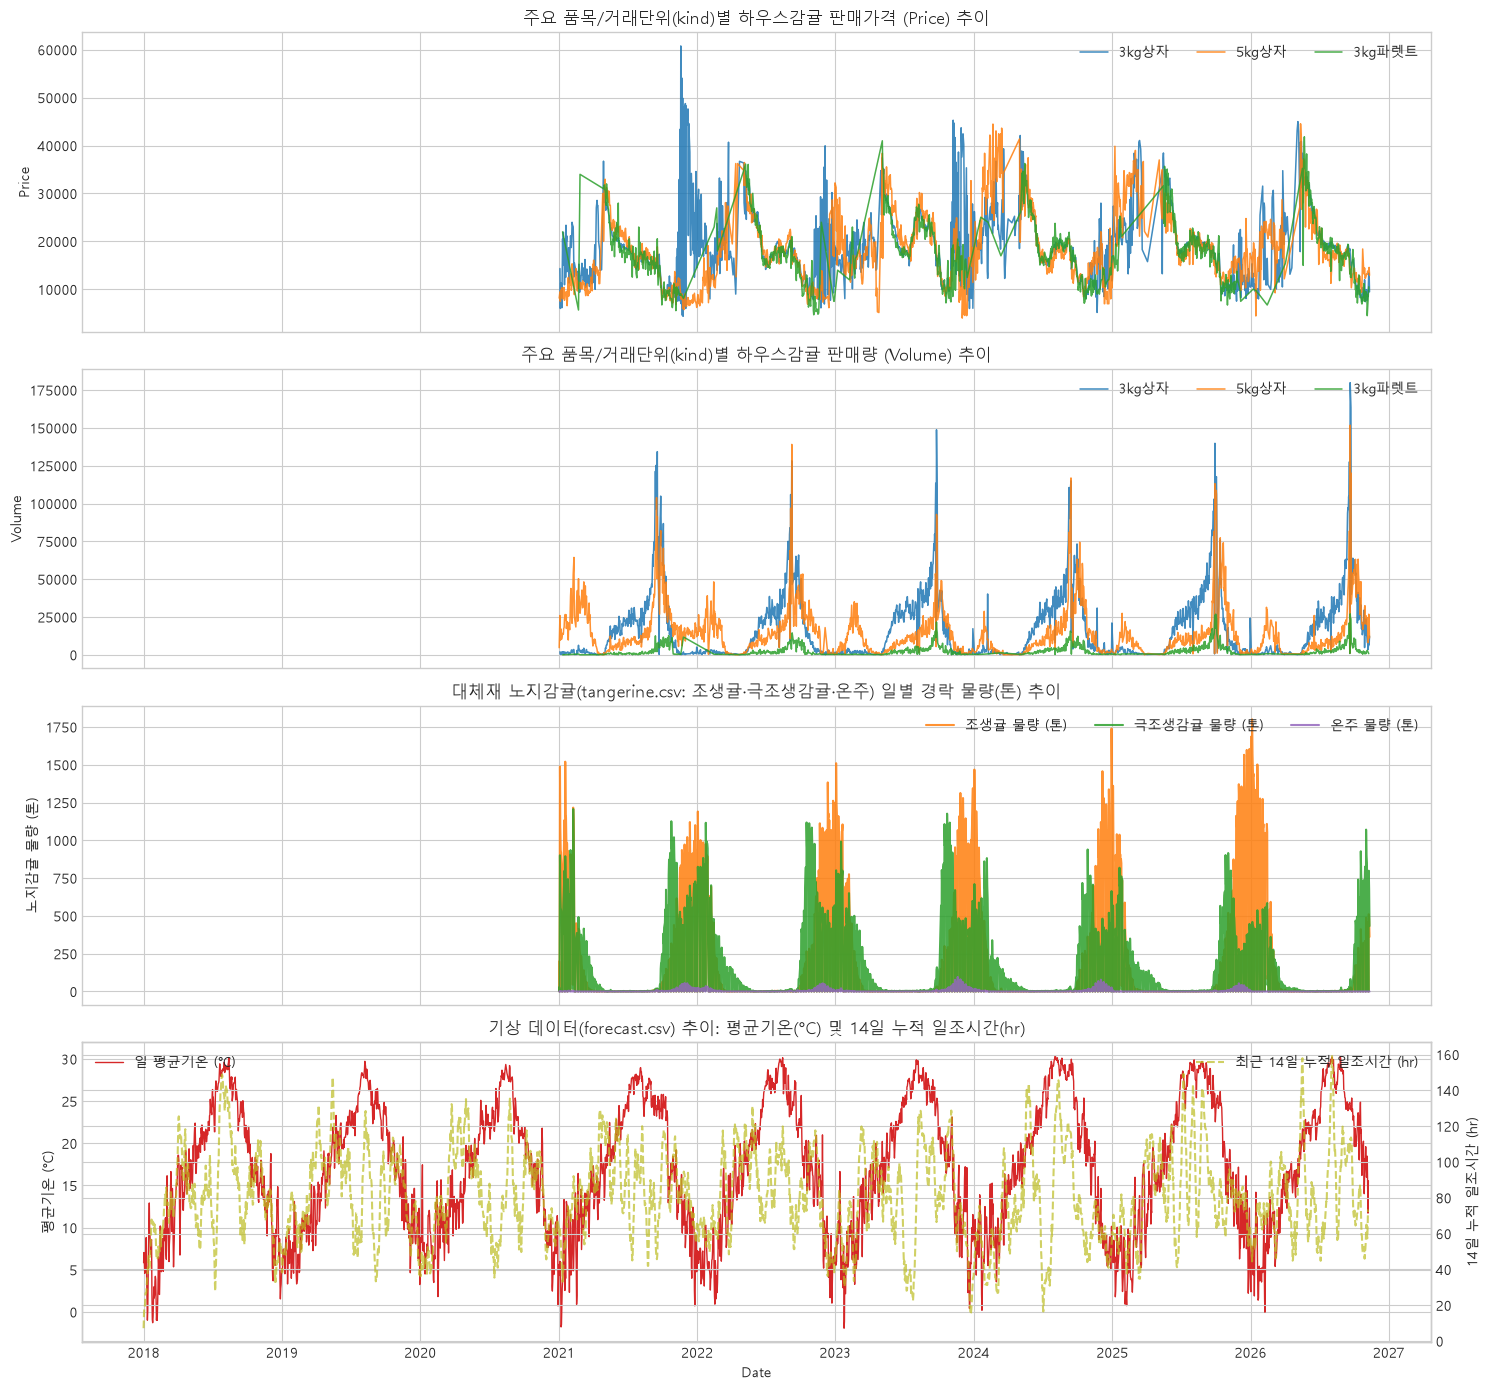

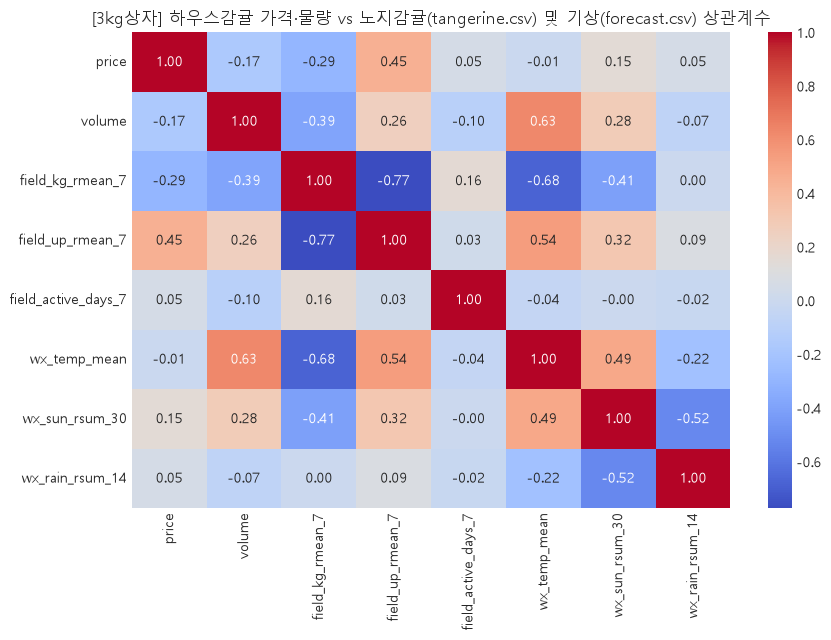

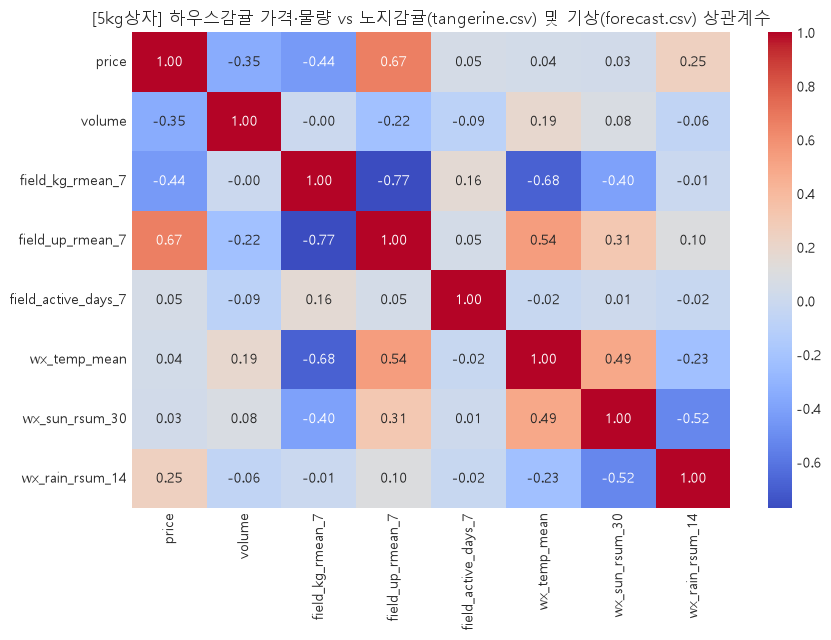

In [3]:
top_plot_kinds = TARGET_KINDS[:7]
sub_eda_df = raw_df[raw_df['kind'].isin(top_plot_kinds)].copy()

fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True)
for k in top_plot_kinds:
    k_df = sub_eda_df[sub_eda_df['kind'] == k]
    axes[0].plot(k_df['date'], k_df['price'], label=k, linewidth=1.1, alpha=0.85)
    axes[1].plot(k_df['date'], k_df['volume'], label=k, linewidth=1.1, alpha=0.85)

axes[0].set_title('주요 품목/거래단위(kind)별 하우스감귤 판매가격 (Price) 추이')
axes[0].set_ylabel('Price')
axes[0].legend(loc='upper right', ncol=3)

axes[1].set_title('주요 품목/거래단위(kind)별 하우스감귤 판매량 (Volume) 추이')
axes[1].set_ylabel('Volume')
axes[1].legend(loc='upper right', ncol=3)

# 노지감귤(조생귤, 극조생감귤, 온주) 품종별 반입 물량(kg) 추이
ax_f = axes[2]
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_josaeng_kg'] / 1000.0, label='조생귤 물량 (톤)', color='tab:orange', alpha=0.85)
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_geukjosaeng_kg'] / 1000.0, label='극조생감귤 물량 (톤)', color='tab:green', alpha=0.85)
ax_f.plot(field_daily_df['date'], field_daily_df['raw_field_onju_kg'] / 1000.0, label='온주 물량 (톤)', color='tab:purple', alpha=0.85)
ax_f.set_title('대체재 노지감귤(tangerine.csv: 조생귤·극조생감귤·온주) 일별 경락 물량(톤) 추이')
ax_f.set_ylabel('노지감귤 물량 (톤)')
ax_f.legend(loc='upper right', ncol=3)

# 기상 데이터 추이 (평균기온 및 14일 누적 일조시간)
ax_wx = axes[3]
ax_wx.plot(wx_daily_df['date'], wx_daily_df['wx_temp_mean'], color='tab:red', label='일 평균기온 (°C)', linewidth=1.0)
ax_wx2 = ax_wx.twinx()
ax_wx2.plot(wx_daily_df['date'], wx_daily_df['wx_sun_rsum_14'], color='tab:olive', linestyle='--', label='최근 14일 누적 일조시간 (hr)', alpha=0.7)
ax_wx.set_title('기상 데이터(forecast.csv) 추이: 평균기온(°C) 및 14일 누적 일조시간(hr)')
ax_wx.set_ylabel('평균기온 (°C)')
ax_wx2.set_ylabel('14일 누적 일조시간 (hr)')
ax_wx.set_xlabel('Date')
ax_wx.legend(loc='upper left')
ax_wx2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# 주력 품목(3kg상자) 기준 하우스감귤 가격/물량과 노지감귤·기상 변수 간 상관관계 히트맵
k0_df = raw_df[raw_df['kind'] == TARGET_KINDS[0]]
corr_cols = [
    'price', 'volume',
    'field_kg_rmean_7', 'field_up_rmean_7', 'field_active_days_7',
    'wx_temp_mean', 'wx_sun_rsum_30', 'wx_rain_rsum_14'
]
plt.figure(figsize=(9, 6.5))
sns.heatmap(k0_df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title(f'[{TARGET_KINDS[0]}] 하우스감귤 가격·물량 vs 노지감귤(tangerine.csv) 및 기상(forecast.csv) 상관계수')
plt.tight_layout()
plt.show()

# 주력 품목(5kg상자) 기준 하우스감귤 가격/물량과 노지감귤·기상 변수 간 상관관계 히트맵
k0_df = raw_df[raw_df['kind'] == TARGET_KINDS[1]]
corr_cols = [
    'price', 'volume',
    'field_kg_rmean_7', 'field_up_rmean_7', 'field_active_days_7',
    'wx_temp_mean', 'wx_sun_rsum_30', 'wx_rain_rsum_14'
]
plt.figure(figsize=(9, 6.5))
sns.heatmap(k0_df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title(f'[{TARGET_KINDS[1]}] 하우스감귤 가격·물량 vs 노지감귤(tangerine.csv) 및 기상(forecast.csv) 상관계수')
plt.tight_layout()
plt.show()

## 3. 노지감귤 대체재(`tangerine.csv`) + 기상 변수(`forecast.csv`) + 시장 연동 시계열 피처 엔지니어링
각 `kind`별로 다음 7가지 핵심 피처 그룹을 생성하여 예측 정확도를 극대화합니다:
1. **노지감귤 대체재 시장 압력 피처 (`tangerine.csv`: 조생귤·극조생감귤·온주)**:
   - 과거 $1, 2, 3, 7, 14$일 노지감귤 총 반입 중량(`field_prev_kg_*`) 및 가중평균 단가(`field_prev_up_*`)
   - 최근 $3, 7, 14, 30$일 노지감귤 이동평균 반입량(`field_kg_rmean_*`), 품종별(`조생귤`, `극조생감귤`, `온주`) 최근 7일 평균 반입량, 최근 7·14일 중 노지감귤 출하일수(`field_active_days_*`)
   - **하우스감귤 vs 노지감귤 교차 대체 비율(`sub_*`)**: 전체 감귤 경락 물량 내 노지감귤 비중(`sub_kg_share_lag1`, `sub_kg_share_rmean7`), 하우스감귤 대비 노지감귤 단가 비율(`sub_up_ratio_lag1`) 및 단가 프리미엄 격차(`sub_up_diff_lag1`)
2. **기상 관측/예보 피처 (`forecast.csv`)**: 평균기온, 강수 계속시간, 최다강수량, 일조시간, 적설 여부 및 단기/중장기 누적·이상기온 파생변수
3. **캘린더 & 설날·추석 명절 특수 피처**: 연/월/일/요일 주기(`sin`, `cos`) + 설날·추석 전후 수요 급증/급감 구간
4. **비연속 거래 공백일(Gap) 및 거래 밀도 피처**: `days_since_last`, `trade_span_7`, `trade_span_14`
5. **품목별 다중 시차(Lag) & 로그 시차 피처**: 과거 $1\sim30$일 가격·판매량 및 `log1p(volume)`
6. **강건 이동 통계(Rolling Median & EMA)**: 스파이크 이상치에 강건한 이동중앙값 및 지수이동평균
7. **하우스감귤 전체 시장 연동(Cross-Kind Implied) 피처**: 전일 하우스감귤 전체 단가·물량 기반 기대치

In [4]:
LUNAR_HOLIDAYS = pd.to_datetime([
    # 2018년 (설날: 2.16, 추석: 9.24)
    "2018-02-16", "2018-09-24",
    # 2019년 (설날: 2.05, 추석: 9.13)
    "2019-02-05", "2019-09-13",
    # 2020년 (설날: 1.25, 추석: 10.01)
    "2020-01-25", "2020-10-01",
    # 2021년 (설날: 2.12, 추석: 9.21)
    "2021-02-12", "2021-09-21",
    # 2022년 (설날: 2.01, 추석: 9.10)
    "2022-02-01", "2022-09-10",
    # 2023년 (설날: 1.22, 추석: 9.29)
    "2023-01-22", "2023-09-29",
    # 2024년 (설날: 2.10, 추석: 9.17)
    "2024-02-10", "2024-09-17",
    # 2025년 (설날: 1.29, 추석: 10.06)
    "2025-01-29", "2025-10-06",
    # 2026년 (설날: 2.17, 추석: 9.25)
    "2026-02-17", "2026-09-25",
    # 2027년 (설날: 2.06, 추석: 9.15 - 미래 확장 대비)
    "2027-02-06", "2027-09-15",
])

def compute_holiday_features(date_series):
    diffs = np.array([(h - date_series).dt.days.values for h in LUNAR_HOLIDAYS])
    pre_holiday = ((diffs >= 0) & (diffs <= 14)).any(axis=0).astype(int)
    post_holiday = ((diffs >= -7) & (diffs < 0)).any(axis=0).astype(int)
    days_near = np.minimum(np.min(np.abs(diffs), axis=0), 60)
    return pre_holiday, post_holiday, days_near

def create_time_series_features_single_kind(df_kind, kind_id=0):
    d = df_kind.sort_values('date').reset_index(drop=True).copy()
    d['kind_id'] = kind_id
    
    # 1. 캘린더 및 설날·추석 명절 피처
    d['year'] = d['date'].dt.year
    d['month'] = d['date'].dt.month
    d['day'] = d['date'].dt.day
    d['dayofweek'] = d['date'].dt.dayofweek
    d['dayofyear'] = d['date'].dt.dayofyear
    d['is_weekend'] = (d['dayofweek'] >= 5).astype(int)
    d['month_sin'] = np.sin(2 * np.pi * d['month'] / 12.0)
    d['month_cos'] = np.cos(2 * np.pi * d['month'] / 12.0)
    d['doy_sin'] = np.sin(2 * np.pi * d['dayofyear'] / 365.25)
    d['doy_cos'] = np.cos(2 * np.pi * d['dayofyear'] / 365.25)
    
    pre_h, post_h, d_hol = compute_holiday_features(d['date'])
    d['is_pre_holiday'] = pre_h
    d['is_post_holiday'] = post_h
    d['days_near_holiday'] = d_hol
    
    # 2. 비연속 거래일(공백일) 및 거래 밀도 피처
    d['days_since_last'] = d['date'].diff().dt.days.fillna(1).clip(1, 90)
    d['trade_span_7'] = (d['date'].shift(1) - d['date'].shift(7)).dt.days.fillna(7).clip(7, 180)
    d['trade_span_14'] = (d['date'].shift(1) - d['date'].shift(14)).dt.days.fillna(14).clip(14, 365)
    
    # 3. 시차(Lag) 및 로그 시차 피처
    for lag in [1, 2, 3, 5, 7, 14, 21, 30]:
        d[f'price_lag_{lag}'] = d['price'].shift(lag)
        d[f'vol_lag_{lag}'] = d['volume'].shift(lag)
        d[f'log_vol_lag_{lag}'] = np.log1p(d['volume'].shift(lag))
        
    # 4. 이동평균(Mean), 이동중앙값(Median), 이동표준편차(Std) 및 지수이동평균(EMA)
    for w in [3, 7, 14, 30]:
        d[f'price_rmean_{w}'] = d['price'].shift(1).rolling(w).mean()
        d[f'price_rmed_{w}'] = d['price'].shift(1).rolling(w).median()
        d[f'price_rstd_{w}'] = d['price'].shift(1).rolling(w).std().fillna(0)
        d[f'vol_rmean_{w}'] = d['volume'].shift(1).rolling(w).mean()
        d[f'vol_rmed_{w}'] = d['volume'].shift(1).rolling(w).median()
        d[f'vol_rstd_{w}'] = d['volume'].shift(1).rolling(w).std().fillna(0)
        
    for span in [2, 3, 5, 7, 14]:
        d[f'price_ema_{span}'] = d['price'].shift(1).ewm(span=span).mean()
        d[f'vol_ema_{span}'] = d['volume'].shift(1).ewm(span=span).mean()
        
    # 5. 하우스감귤 전체 시장 연동(Cross-Kind Market) 점유율 및 기대 가격·물량 피처
    for lag in [1, 2, 3, 7]:
        d[f'vol_share_lag_{lag}'] = d['vol_share'].shift(lag)
        d[f'up_ratio_lag_{lag}'] = d['up_ratio'].shift(lag)
        
    d['vol_share_ema_5'] = d['vol_share'].shift(1).ewm(span=5).mean()
    d['up_ratio_ema_5'] = d['up_ratio'].shift(1).ewm(span=5).mean()
    d['vol_share_rmed_7'] = d['vol_share'].shift(1).rolling(7).median()
    d['up_ratio_rmed_7'] = d['up_ratio'].shift(1).rolling(7).median()
    
    d['implied_price_mkt_lag1'] = d['mkt_prev_up_1'] * d['weight_kg'] * d['up_ratio_ema_5']
    d['implied_price_mkt_rmean3'] = d['mkt_up_rmean_3'] * d['weight_kg'] * d['up_ratio_rmed_7']
    d['implied_vol_mkt_lag1'] = (d['mkt_prev_kg_1'] * d['vol_share_ema_5']) / d['weight_kg']
    d['implied_vol_mkt_rmed7'] = (d['mkt_kg_rmed_7'] * d['vol_share_rmed_7']) / d['weight_kg']
    
    # 6. 노지감귤(조생/극조생/온주) vs 하우스감귤 교차 대체(Substitute) 피처
    d['sub_kg_share_lag1'] = d['field_prev_kg_1'] / (d['mkt_prev_kg_1'] + d['field_prev_kg_1'] + 1e-8)
    d['sub_kg_share_rmean7'] = d['field_kg_rmean_7'] / (d['mkt_kg_rmean_7'] + d['field_kg_rmean_7'] + 1e-8)
    d['sub_kg_share_rmean14'] = d['field_kg_rmean_14'] / (d['mkt_kg_rmean_14'] + d['field_kg_rmean_14'] + 1e-8)
    d['sub_up_ratio_lag1'] = np.where(d['field_prev_up_1'] > 0, d['field_prev_up_1'] / (d['mkt_prev_up_1'] + 1e-8), 0.0)
    d['sub_up_diff_lag1'] = np.where(d['field_prev_up_1'] > 0, d['mkt_prev_up_1'] - d['field_prev_up_1'], 0.0)
    d['sub_field_implied_box_price'] = d['field_up_rmean_7'] * d['weight_kg']
    
    # 7. 기상 상호작용(Weather Interaction) 및 모멘텀 피처
    d['wx_temp_change_since_last'] = d['wx_temp_mean'] - d['wx_temp_mean'].shift(1).fillna(d['wx_temp_mean'])
    d['wx_sun_ratio_7_30'] = (d['wx_sun_rsum_7'] / 7.0) / ((d['wx_sun_rsum_30'] / 30.0) + 0.1)
    d['wx_rain_impact_vol'] = d['vol_ema_3'] * np.exp(-0.03 * d['wx_rain_dur'])
    
    d['price_diff_1'] = d['price'].shift(1) - d['price'].shift(2)
    d['price_ratio_1_7'] = d['price'].shift(1) / (d['price_rmean_7'] + 1e-8)
    d['vol_diff_1'] = d['volume'].shift(1) - d['volume'].shift(2)
    d['vol_ratio_1_7'] = d['volume'].shift(1) / (d['vol_rmean_7'] + 1e-8)
    
    return d.dropna().reset_index(drop=True)

kind_map = {k: idx for idx, k in enumerate(TARGET_KINDS)}
kind_datasets = {}
exclude_cols = [
    'date', 'kind', 'price', 'volume', 'total price',
    'unit_price', 'total_kg', 'mkt_total_kg', 'mkt_total_rev',
    'mkt_unit_price', 'mkt_active_kinds', 'vol_share', 'up_ratio'
]
feature_cols = None

split_summary_rows = []
for k in TARGET_KINDS:
    k_raw = raw_df[raw_df['kind'] == k].copy()
    k_feat = create_time_series_features_single_kind(k_raw, kind_id=kind_map[k])
    if feature_cols is None:
        feature_cols = [c for c in k_feat.columns if c not in exclude_cols]
        
    n_k = len(k_feat)
    tr_end = int(n_k * 0.70)
    va_end = int(n_k * 0.85)
    
    kind_datasets[k] = {
        'raw': k_raw,
        'feat': k_feat,
        'train': k_feat.iloc[:tr_end].copy(),
        'val': k_feat.iloc[tr_end:va_end].copy(),
        'test': k_feat.iloc[va_end:].copy(),
        'train_end': tr_end,
        'val_end': va_end
    }
    split_summary_rows.append({
        'kind': k,
        '전체_피처행수': n_k,
        'Train(70%)': len(kind_datasets[k]['train']),
        'Val(15%)': len(kind_datasets[k]['val']),
        'Test(15%)': len(kind_datasets[k]['test'])
    })

global_train_df = pd.concat([kind_datasets[k]['train'] for k in TARGET_KINDS], ignore_index=True)
global_val_df = pd.concat([kind_datasets[k]['val'] for k in TARGET_KINDS], ignore_index=True)

wx_feat_cols = [c for c in feature_cols if c.startswith('wx_')]
field_feat_cols = [c for c in feature_cols if c.startswith('field_') or c.startswith('sub_')]
print(f"총 피처 개수: {len(feature_cols)}개 (기상 피처 {len(wx_feat_cols)}개 + 노지감귤 대체재 피처 {len(field_feat_cols)}개 포함) | Global Train: {len(global_train_df):,}행")
print(f"노지감귤 대체재 주요 피처: {field_feat_cols}")
display(pd.DataFrame(split_summary_rows))


총 피처 개수: 216개 (기상 피처 49개 + 노지감귤 대체재 피처 47개 포함) | Global Train: 2,925행
노지감귤 대체재 주요 피처: ['field_all_citrus_today_kg', 'field_other_citrus_today_kg', 'field_other_citrus_share_today', 'field_log_all_citrus_today', 'field_log_other_citrus_today', 'field_is_active_lag1', 'field_active_days_7', 'field_active_days_14', 'field_prev_kg_1', 'field_prev_up_1', 'field_other_prev_kg_1', 'field_prev_kg_2', 'field_prev_up_2', 'field_other_prev_kg_2', 'field_prev_kg_3', 'field_prev_up_3', 'field_other_prev_kg_3', 'field_prev_kg_7', 'field_prev_up_7', 'field_other_prev_kg_7', 'field_prev_kg_14', 'field_prev_up_14', 'field_other_prev_kg_14', 'field_kg_rmean_3', 'field_up_rmean_3', 'field_other_kg_rmean_3', 'field_kg_rmean_7', 'field_up_rmean_7', 'field_other_kg_rmean_7', 'field_kg_rmean_14', 'field_up_rmean_14', 'field_other_kg_rmean_14', 'field_kg_rmean_30', 'field_up_rmean_30', 'field_other_kg_rmean_30', 'field_josaeng_kg_rmean_7', 'field_geukjosaeng_kg_rmean_7', 'field_onju_kg_rmean_7', 'field_log_kg

,kind,전체_피처행수,Train(70%),Val(15%),Test(15%)
0,3kg상자,1582,1107,237,238
1,5kg상자,1584,1108,238,238
2,3kg파렛트,1015,710,152,153


## 4. 평가지표 및 예측 정확도(Accuracy) 함수 정의
- **정확도 (`Accuracy(%)`)**: $100 - \text{WAPE}(\%)$ (전체 규모 대비 가중 예측 정확도, 메인 정확도 지표)
- **대칭 정확도 (`sMAPE Accuracy(%)`)**: $100 - \text{sMAPE}(\%)$ (일별 대칭 백분율 오차 기반 정확도)
- **방향성 정확도 (`Directional Accuracy(%)`)**: 전일 대비 가격/판매량의 상승·하락 추세 방향 일치율
- **MAE** (Mean Absolute Error) / **RMSE** (Root Mean Squared Error)
- **MAPE** (Mean Absolute Percentage Error) / **WAPE** (Weighted Absolute Percentage Error) / **$R^2$ Score**

In [5]:
def evaluate_predictions(y_true, y_pred, model_name="Model", target_name="Target", kind_name="All"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    non_zero = np.abs(y_true) > 1e-6
    mape = np.mean(np.abs((y_true[non_zero] - y_pred[non_zero]) / y_true[non_zero])) * 100 if np.any(non_zero) else np.nan
    wape = (np.sum(np.abs(y_true - y_pred)) / (np.sum(np.abs(y_true)) + 1e-8)) * 100
    smape = np.mean(2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    r2 = r2_score(y_true, y_pred)
    
    acc_wape = max(0.0, 100.0 - wape)
    acc_smape = max(0.0, 100.0 - smape)
    acc_mape = max(0.0, 100.0 - mape) if not np.isnan(mape) else np.nan
    
    if len(y_true) > 1:
        true_dir = np.sign(np.diff(y_true))
        pred_dir = np.sign(np.diff(y_pred))
        dir_acc = np.mean(true_dir == pred_dir) * 100.0
    else:
        dir_acc = np.nan
    
    return {
        'kind': kind_name,
        'Model': model_name,
        'Target': target_name,
        '정확도(100-WAPE, %)': round(acc_wape, 2),
        '대칭정확도(100-sMAPE, %)': round(acc_smape, 2),
        '방향정확도(DA, %)': round(dir_acc, 2),
        '정밀정확도(100-MAPE, %)': round(acc_mape, 2),
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE(%)': round(mape, 2),
        'WAPE(%)': round(wape, 2),
        'R2': round(r2, 4)
    }

def optimize_blend_weights(y_val_true, val_candidates_list, test_candidates_list, step=0.2):
    """Validation 셋의 WAPE 정확도를 최대화하는 가중치 조합을 탐색하여 Test 예측값을 산출"""
    y_val_true = np.asarray(y_val_true, dtype=float)
    val_mat = np.column_stack(val_candidates_list)
    test_mat = np.column_stack(test_candidates_list)
    k_num = val_mat.shape[1]
    
    grid_vals = np.arange(0.0, 1.0 + 1e-6, step)
    best_acc = -1.0
    best_w = np.ones(k_num) / k_num
    
    def _search(idx, rem, cur_w):
        nonlocal best_acc, best_w
        if idx == k_num - 1:
            w = np.array(cur_w + [max(0.0, rem)])
            pred_val = val_mat @ w
            wape = np.sum(np.abs(y_val_true - pred_val)) / (np.sum(np.abs(y_val_true)) + 1e-8) * 100.0
            acc = 100.0 - wape
            if acc > best_acc:
                best_acc = acc
                best_w = w
            return
        for g in grid_vals:
            if g <= rem + 1e-6:
                _search(idx + 1, rem - g, cur_w + [g])
                
    _search(0, 1.0, [])
    return np.maximum(0.0, test_mat @ best_w), np.maximum(0.0, val_mat @ best_w), best_w

def record_metric(metrics_list, metric_dict):
    metrics_list[:] = [
        m for m in metrics_list
        if not (m['kind'] == metric_dict['kind'] and m['Model'] == metric_dict['Model'] and m['Target'] == metric_dict['Target'])
    ]
    metrics_list.append(metric_dict)

def display_model_kind_summary(metrics_list, model_name):
    df_m = pd.DataFrame([m for m in metrics_list if m['Model'] == model_name])
    p_df = df_m[df_m['Target'] == 'price'].set_index('kind')
    v_df = df_m[df_m['Target'] == 'volume'].set_index('kind')
    
    combined = pd.DataFrame({
        'kind(거래단위)': p_df.index,
        '판매가격(price) 정확도(%)': p_df['정확도(100-WAPE, %)'].values,
        '판매가격(price) 대칭정확도(%)': p_df['대칭정확도(100-sMAPE, %)'].values,
        '판매가격(price) MAE': p_df['MAE'].values,
        '판매가격(price) R²': p_df['R2'].values,
        '판매량(volume) 정확도(%)': v_df.loc[p_df.index, '정확도(100-WAPE, %)'].values,
        '판매량(volume) 대칭정확도(%)': v_df.loc[p_df.index, '대칭정확도(100-sMAPE, %)'].values,
        '판매량(volume) MAE': v_df.loc[p_df.index, 'MAE'].values,
        '판매량(volume) R²': v_df.loc[p_df.index, 'R2'].values,
    })
    print(
        f"▶ [{model_name}] 전체 kind 평균 — "
        f"판매가격(price) 평균 정확도: {combined['판매가격(price) 정확도(%)'].mean():.2f}% | "
        f"판매량(volume) 평균 정확도: {combined['판매량(volume) 정확도(%)'].mean():.2f}%"
    )
    display(combined)

metrics_summary = []
predictions_by_kind = {k: {} for k in TARGET_KINDS}
val_predictions_by_kind = {k: {} for k in TARGET_KINDS}

## 5. 품목/거래단위(`kind`)별 Temporal Fusion Transformer (TFT, GPU) 분리 예측
- 각 `kind`별 시계열 스케일이 다르므로 품목마다 독립된 `StandardScaler`와 **PyTorch TFT 모델(GRN + Variable Selection Network + LSTM + Multi-Head Attention)**을 GPU(`cuda` + AMP)에서 학습하여 `price`와 `volume`을 동시에 예측합니다.

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

# 재현성을 위한 시드 고정 (CPU & GPU)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"사용 디바이스: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else ""))

class GatedResidualNetwork(nn.Module):
    """TFT의 핵심 구성요소인 Gated Residual Network (GRN)"""
    def __init__(self, input_dim, hidden_dim, output_dim=None, dropout=0.1):
        super().__init__()
        output_dim = output_dim or input_dim
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.elu = nn.ELU()
        self.fc2 = nn.Linear(hidden_dim, output_dim * 2)  # GLU 용
        self.dropout = nn.Dropout(dropout)
        self.skip = nn.Linear(input_dim, output_dim) if input_dim != output_dim else nn.Identity()
        self.norm = nn.LayerNorm(output_dim)

    def forward(self, x):
        residual = self.skip(x)
        h = self.elu(self.fc1(x))
        h = self.dropout(self.fc2(h))
        val, gate = h.chunk(2, dim=-1)
        gated = val * torch.sigmoid(gate)
        return self.norm(residual + gated)


class VariableSelectionNetwork(nn.Module):
    """TFT의 시점별 변수 중요도 가중 선택 네트워크 (VSN)"""
    def __init__(self, num_vars, hidden_dim, dropout=0.1):
        super().__init__()
        self.num_vars = num_vars
        self.var_embeddings = nn.ModuleList([nn.Linear(1, hidden_dim) for _ in range(num_vars)])
        self.var_grns = nn.ModuleList([GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout) for _ in range(num_vars)])
        self.weight_grn = GatedResidualNetwork(num_vars * hidden_dim, hidden_dim, num_vars, dropout)

    def forward(self, x):
        # x: (batch, seq_len, num_vars)
        var_outputs = []
        for i in range(self.num_vars):
            v = self.var_embeddings[i](x[..., i:i+1])
            v = self.var_grns[i](v)
            var_outputs.append(v)
        # (batch, seq_len, num_vars, hidden_dim)
        stacked = torch.stack(var_outputs, dim=-2)
        flat = stacked.reshape(x.size(0), x.size(1), -1)
        weights = torch.softmax(self.weight_grn(flat), dim=-1).unsqueeze(-1)  # (batch, seq_len, num_vars, 1)
        selected = torch.sum(stacked * weights, dim=-2)  # (batch, seq_len, hidden_dim)
        return selected, weights.squeeze(-1)


class TemporalFusionTransformerModel(nn.Module):
    """판매가격(price)과 판매량(volume)을 동시에 추정하는 Temporal Fusion Transformer"""
    def __init__(self, num_past_vars, num_future_vars, hidden_dim=64, num_heads=4, dropout=0.2, num_targets=2):
        super().__init__()
        self.past_vsn = VariableSelectionNetwork(num_past_vars, hidden_dim, dropout)
        self.future_vsn = VariableSelectionNetwork(num_future_vars, hidden_dim, dropout)
        
        self.encoder_lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.decoder_lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        
        self.post_lstm_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=num_heads, dropout=dropout, batch_first=True)
        self.post_attn_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.pos_wise_grn = GatedResidualNetwork(hidden_dim, hidden_dim, hidden_dim, dropout)
        self.out_proj = nn.Linear(hidden_dim, num_targets)

    def forward(self, x_past, x_future):
        # 1. Variable Selection
        enc_in, past_weights = self.past_vsn(x_past)
        dec_in, _ = self.future_vsn(x_future)
        
        # 2. Sequence-to-Sequence LSTM
        enc_out, (h, c) = self.encoder_lstm(enc_in)
        dec_out, _ = self.decoder_lstm(dec_in, (h, c))
        
        seq_in = torch.cat([enc_in, dec_in], dim=1)
        seq_lstm = torch.cat([enc_out, dec_out], dim=1)
        temporal_feats = self.post_lstm_grn(seq_in + seq_lstm)
        
        # 3. Interpretable Multi-Head Attention
        attn_out, attn_weights = self.attention(temporal_feats, temporal_feats, temporal_feats)
        attn_feats = self.post_attn_grn(temporal_feats + attn_out)
        
        # 4. Position-wise Feed-Forward GRN (마지막 예측 시점 출력 추출)
        dec_final = self.pos_wise_grn(attn_feats[:, -1, :])
        preds = self.out_proj(dec_final)  # (batch, 2) -> [price, volume]
        return preds, past_weights, attn_weights

past_cols = [
    'price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1',
    'field_log_kg_lag1', 'field_log_kg_rmean_7', 'field_up_rmean_7', 'sub_kg_share_rmean7',
    'wx_temp_mean', 'wx_rain_dur', 'wx_rain_peak', 'wx_sun_hr',
    'wx_temp_rmean_14', 'wx_sun_rsum_14', 'wx_rain_rsum_7',
    'days_since_last', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos',
    'dayofweek', 'is_weekend', 'is_pre_holiday'
]
future_cols = [
    'field_log_kg_lag1', 'field_log_kg_rmean_7', 'field_up_rmean_7', 'sub_kg_share_rmean7', 'field_active_days_7',
    'wx_temp_mean', 'wx_rain_dur', 'wx_rain_peak', 'wx_sun_hr',
    'wx_temp_rmean_14', 'wx_sun_rsum_14', 'wx_rain_rsum_7', 'wx_is_snow',
    'days_since_last', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos',
    'dayofweek', 'is_weekend', 'is_pre_holiday', 'days_near_holiday'
]

class TFTSequenceDataset(Dataset):
    def __init__(self, past_arr, future_arr, target_arr, indices, seq_len):
        valid_idx = [i for i in indices if i >= seq_len]
        self.x_past = torch.tensor(np.stack([past_arr[t - seq_len : t] for t in valid_idx]), dtype=torch.float32, device=device)
        self.x_future = torch.tensor(np.stack([future_arr[t : t + 1] for t in valid_idx]), dtype=torch.float32, device=device)
        self.y = torch.tensor(np.stack([target_arr[t] for t in valid_idx]), dtype=torch.float32, device=device)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.x_past[idx], self.x_future[idx], self.y[idx]

tft_models_by_kind = {}
use_cuda = (device.type == 'cuda')

for k in TARGET_KINDS:
    ds = kind_datasets[k]
    k_feat = ds['feat'].copy()
    tr_end, va_end = ds['train_end'], ds['val_end']
    
    tft_df = k_feat[['date'] + list(dict.fromkeys(past_cols + future_cols))].copy()
    for c in ['price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1', 'field_up_rmean_7']:
        tft_df[c] = np.log1p(np.maximum(0.0, tft_df[c]))
        
    past_scaler = StandardScaler()
    future_scaler = StandardScaler()
    target_scaler = StandardScaler()
    
    past_scaled = np.vstack([
        past_scaler.fit_transform(tft_df.iloc[:tr_end][past_cols]),
        past_scaler.transform(tft_df.iloc[tr_end:][past_cols])
    ])
    future_scaled = np.vstack([
        future_scaler.fit_transform(tft_df.iloc[:tr_end][future_cols]),
        future_scaler.transform(tft_df.iloc[tr_end:][future_cols])
    ])
    target_scaled = np.vstack([
        target_scaler.fit_transform(tft_df.iloc[:tr_end][['price', 'volume']]),
        target_scaler.transform(tft_df.iloc[tr_end:][['price', 'volume']])
    ])
    
    seq_len = min(14, max(3, tr_end // 5))
    train_indices = list(range(seq_len, tr_end))
    val_indices = list(range(tr_end, va_end))
    test_indices = list(range(va_end, len(tft_df)))
    
    tr_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, train_indices, seq_len)
    va_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, val_indices, seq_len)
    te_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, test_indices, seq_len)
    train_loader = [(tr_ds.x_past[i:i+128], tr_ds.x_future[i:i+128], tr_ds.y[i:i+128]) for i in range(0, len(tr_ds), 128)]
    val_loader = [(va_ds.x_past[i:i+128], va_ds.x_future[i:i+128], va_ds.y[i:i+128]) for i in range(0, len(va_ds), 128)]
    test_loader = [(te_ds.x_past[i:i+128], te_ds.x_future[i:i+128], te_ds.y[i:i+128]) for i in range(0, len(te_ds), 128)]
    
    torch.manual_seed(42)
    if use_cuda:
        torch.cuda.manual_seed_all(42)
        
    # 최적화된 하이퍼파라미터 반영: batch_size=128, dropout=0.2, hidden_dim=64, lr=0.001, num_heads=4
    tft_model = TemporalFusionTransformerModel(
        num_past_vars=len(past_cols),
        num_future_vars=len(future_cols),
        hidden_dim=64,
        num_heads=4,
        dropout=0.2,
        num_targets=2
    ).to(device)
    
    criterion = nn.L1Loss()
    optimizer = torch.optim.AdamW(tft_model.parameters(), lr=0.001, weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda', enabled=use_cuda)
    
    best_val_loss = float('inf')
    best_state = None
    epochs = 35
    
    for epoch in range(1, epochs + 1):
        tft_model.train()
        for x_p, x_f, y_b in train_loader:
            x_p = x_p.to(device, non_blocking=use_cuda)
            x_f = x_f.to(device, non_blocking=use_cuda)
            y_b = y_b.to(device, non_blocking=use_cuda)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, _, _ = tft_model(x_p, x_f)
                loss = criterion(preds, y_b)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(tft_model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            
        tft_model.eval()
        val_losses = []
        with torch.no_grad():
            for x_p, x_f, y_b in val_loader:
                x_p = x_p.to(device, non_blocking=use_cuda)
                x_f = x_f.to(device, non_blocking=use_cuda)
                y_b = y_b.to(device, non_blocking=use_cuda)
                with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                    preds, _, _ = tft_model(x_p, x_f)
                    val_losses.append(criterion(preds, y_b).item())
        val_loss = np.mean(val_losses) if val_losses else 0.0
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {key: val.detach().cpu().clone() for key, val in tft_model.state_dict().items()}
            
    if best_state is not None:
        tft_model.load_state_dict(best_state)
        
    tft_model.eval()
    val_preds_scaled, test_preds_scaled, past_var_weights_list = [], [], []
    with torch.no_grad():
        for x_p, x_f, _ in val_loader:
            x_p, x_f = x_p.to(device, non_blocking=use_cuda), x_f.to(device, non_blocking=use_cuda)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, _, _ = tft_model(x_p, x_f)
            val_preds_scaled.append(preds.float().cpu().numpy())
        for x_p, x_f, _ in test_loader:
            x_p, x_f = x_p.to(device, non_blocking=use_cuda), x_f.to(device, non_blocking=use_cuda)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, p_weights, _ = tft_model(x_p, x_f)
            test_preds_scaled.append(preds.float().cpu().numpy())
            past_var_weights_list.append(p_weights.float().cpu().numpy())
            
    val_inv = np.expm1(target_scaler.inverse_transform(np.vstack(val_preds_scaled)))
    test_inv = np.expm1(target_scaler.inverse_transform(np.vstack(test_preds_scaled)))
    
    va_df, te_df = ds['val'], ds['test']
    
    tft_pred_vol_te, tft_pred_vol_va, _ = optimize_blend_weights(
        va_df['volume'].values,
        [val_inv[:, 1], va_df['vol_ema_3'].values, va_df['vol_rmed_7'].values, va_df['implied_vol_mkt_lag1'].values],
        [test_inv[:, 1], te_df['vol_ema_3'].values, te_df['vol_rmed_7'].values, te_df['implied_vol_mkt_lag1'].values],
        step=0.25
    )
    tft_pred_price_te, tft_pred_price_va, _ = optimize_blend_weights(
        va_df['price'].values,
        [val_inv[:, 0], va_df['price_ema_2'].values, va_df['implied_price_mkt_lag1'].values],
        [test_inv[:, 0], te_df['price_ema_2'].values, te_df['implied_price_mkt_lag1'].values],
        step=0.25
    )
    
    tft_models_by_kind[k] = {
        'model': tft_model,
        'past_scaler': past_scaler,
        'future_scaler': future_scaler,
        'target_scaler': target_scaler,
        'seq_len': seq_len,
        'past_weights': np.concatenate(past_var_weights_list, axis=0).mean(axis=(0, 1))
    }
    predictions_by_kind[k]['tft_volume'] = tft_pred_vol_te
    predictions_by_kind[k]['tft_price'] = tft_pred_price_te
    val_predictions_by_kind[k]['tft_volume'] = tft_pred_vol_va
    val_predictions_by_kind[k]['tft_price'] = tft_pred_price_va
    
    record_metric(metrics_summary, evaluate_predictions(te_df['volume'], tft_pred_vol_te, 'TFT', 'volume', kind_name=k))
    record_metric(metrics_summary, evaluate_predictions(te_df['price'], tft_pred_price_te, 'TFT', 'price', kind_name=k))    


사용 디바이스: cuda (NVIDIA GeForce RTX 5060 Ti)


## 6. TFT 모델링 결과와 실제 가격(`price`) · 판매량(`volume`) 비교 및 시각화
- 학습된 **TFT(Temporal Fusion Transformer)** 모델의 예측치와 실제 시장 거래 데이터를 시계열 및 산점도 그래프로 비교합니다:
  1. **판매단위(`3kg상자`, `5kg상자`)별 시계열 예측 추이 비교**: 실제 거래 데이터(실선)와 TFT 예측치(점선) 및 오차 영역 시각화
  2. **실제값 vs TFT 예측값 적합도 산점도(Scatter Plot)**: $y=x$ 대각선 기준 모델의 과소/과대 추정 및 상관성 진단
  3. **TFT 종합 성능 평가지표 표**: 가중 예측 정확도(100 - WAPE, %), MAE, RMSE, $R^2$ 평가
  4. **최근 예측 결과 샘플 테이블**: 최근 10개 거래일의 실제값, 예측값 및 오차율 비교

=== [TFT 모델링 성능 평가지표 요약 (Test Set)] ===
▶ [TFT] 전체 kind 평균 — 판매가격(price) 평균 정확도: 88.51% | 판매량(volume) 평균 정확도: 68.38%


,kind(거래단위),판매가격(price) 정확도(%),판매가격(price) 대칭정확도(%),판매가격(price) MAE,판매가격(price) R²,판매량(volume) 정확도(%),판매량(volume) 대칭정확도(%),판매량(volume) MAE,판매량(volume) R²
0,3kg상자,87.93,87.29,2221.93,0.7527,73.58,60.68,5645.13,0.7658
1,5kg상자,88.66,88.52,2115.21,0.6922,69.34,63.33,4548.56,0.7019
2,3kg파렛트,88.94,88.72,2047.35,0.8269,62.22,61.75,1380.38,0.6589


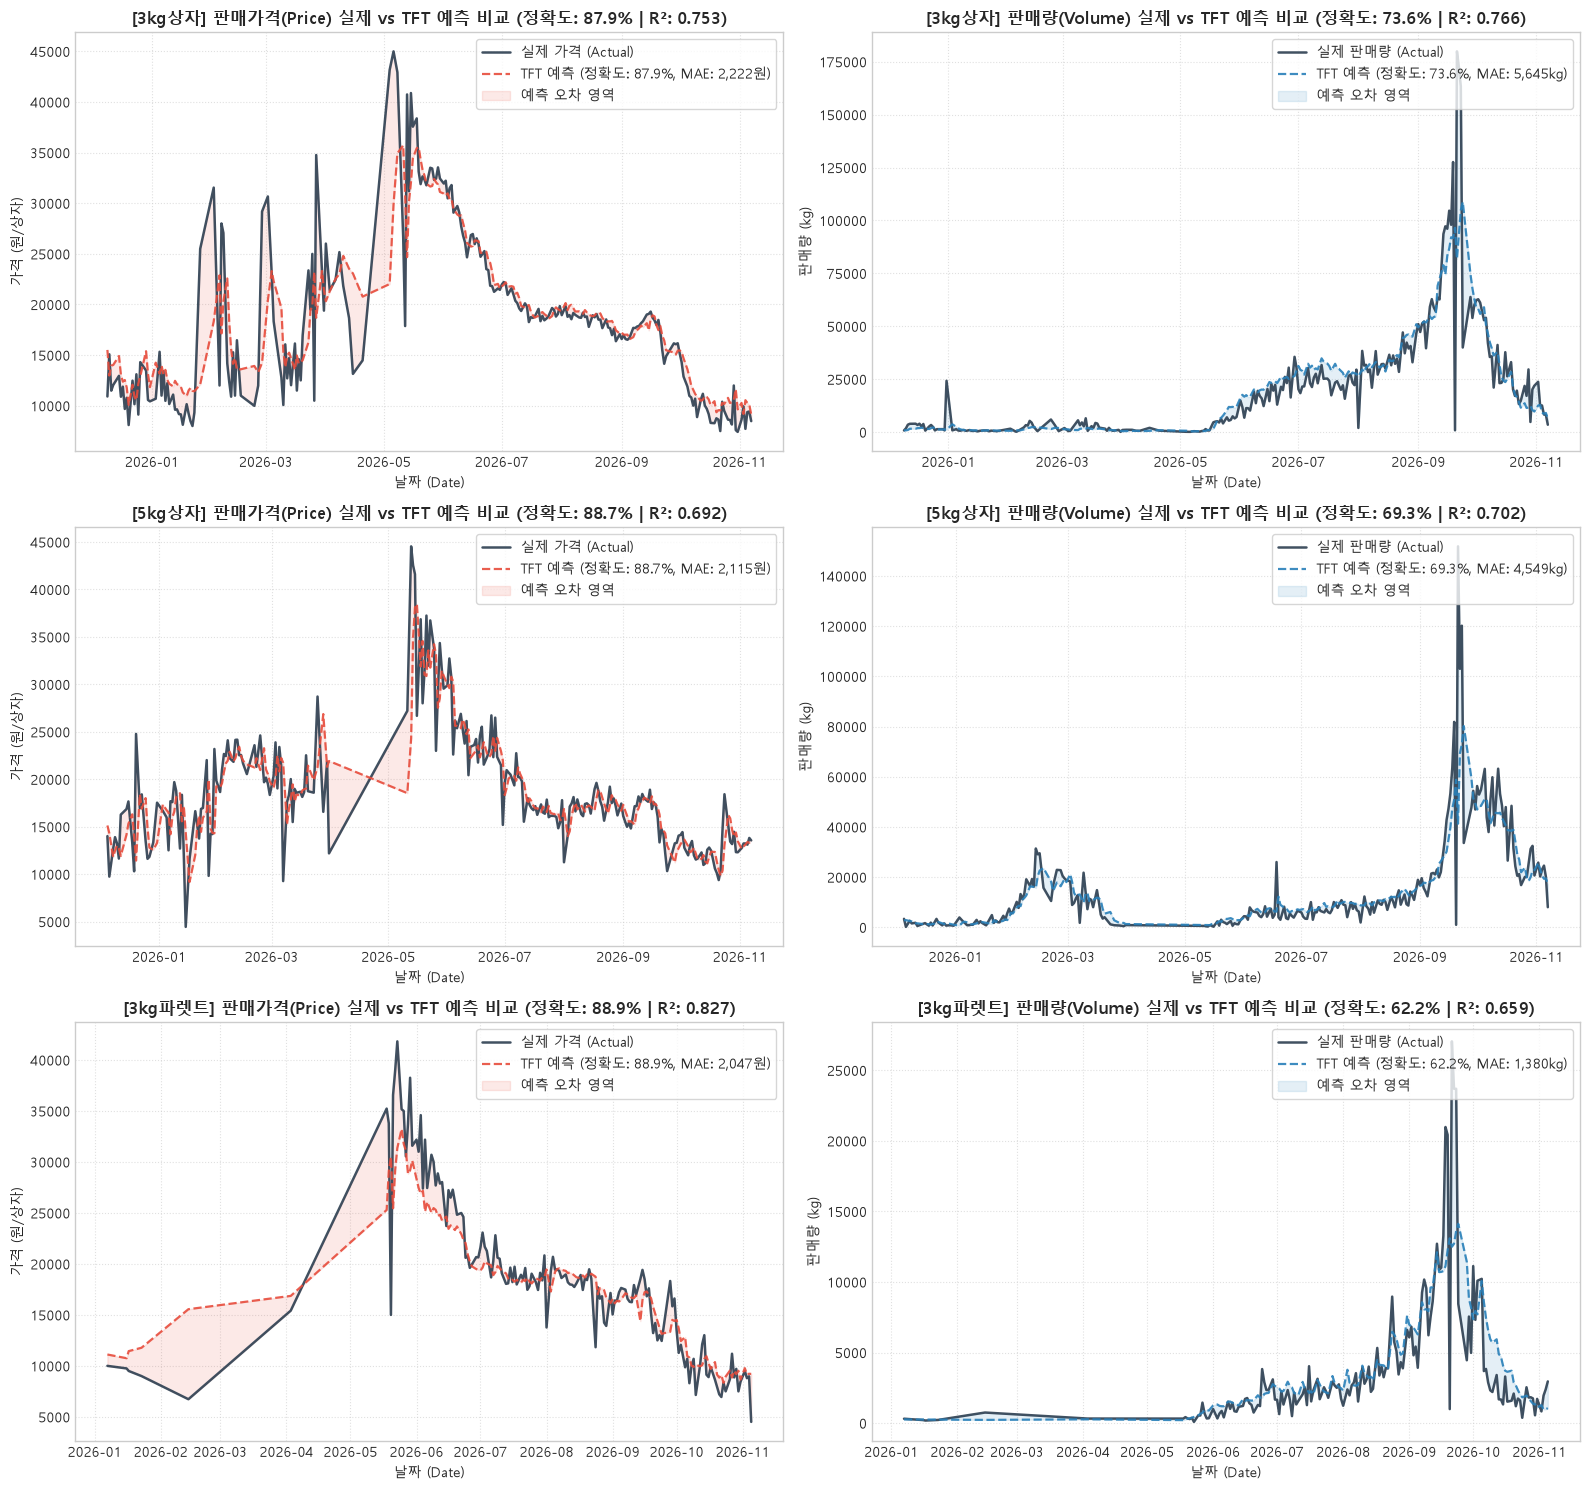

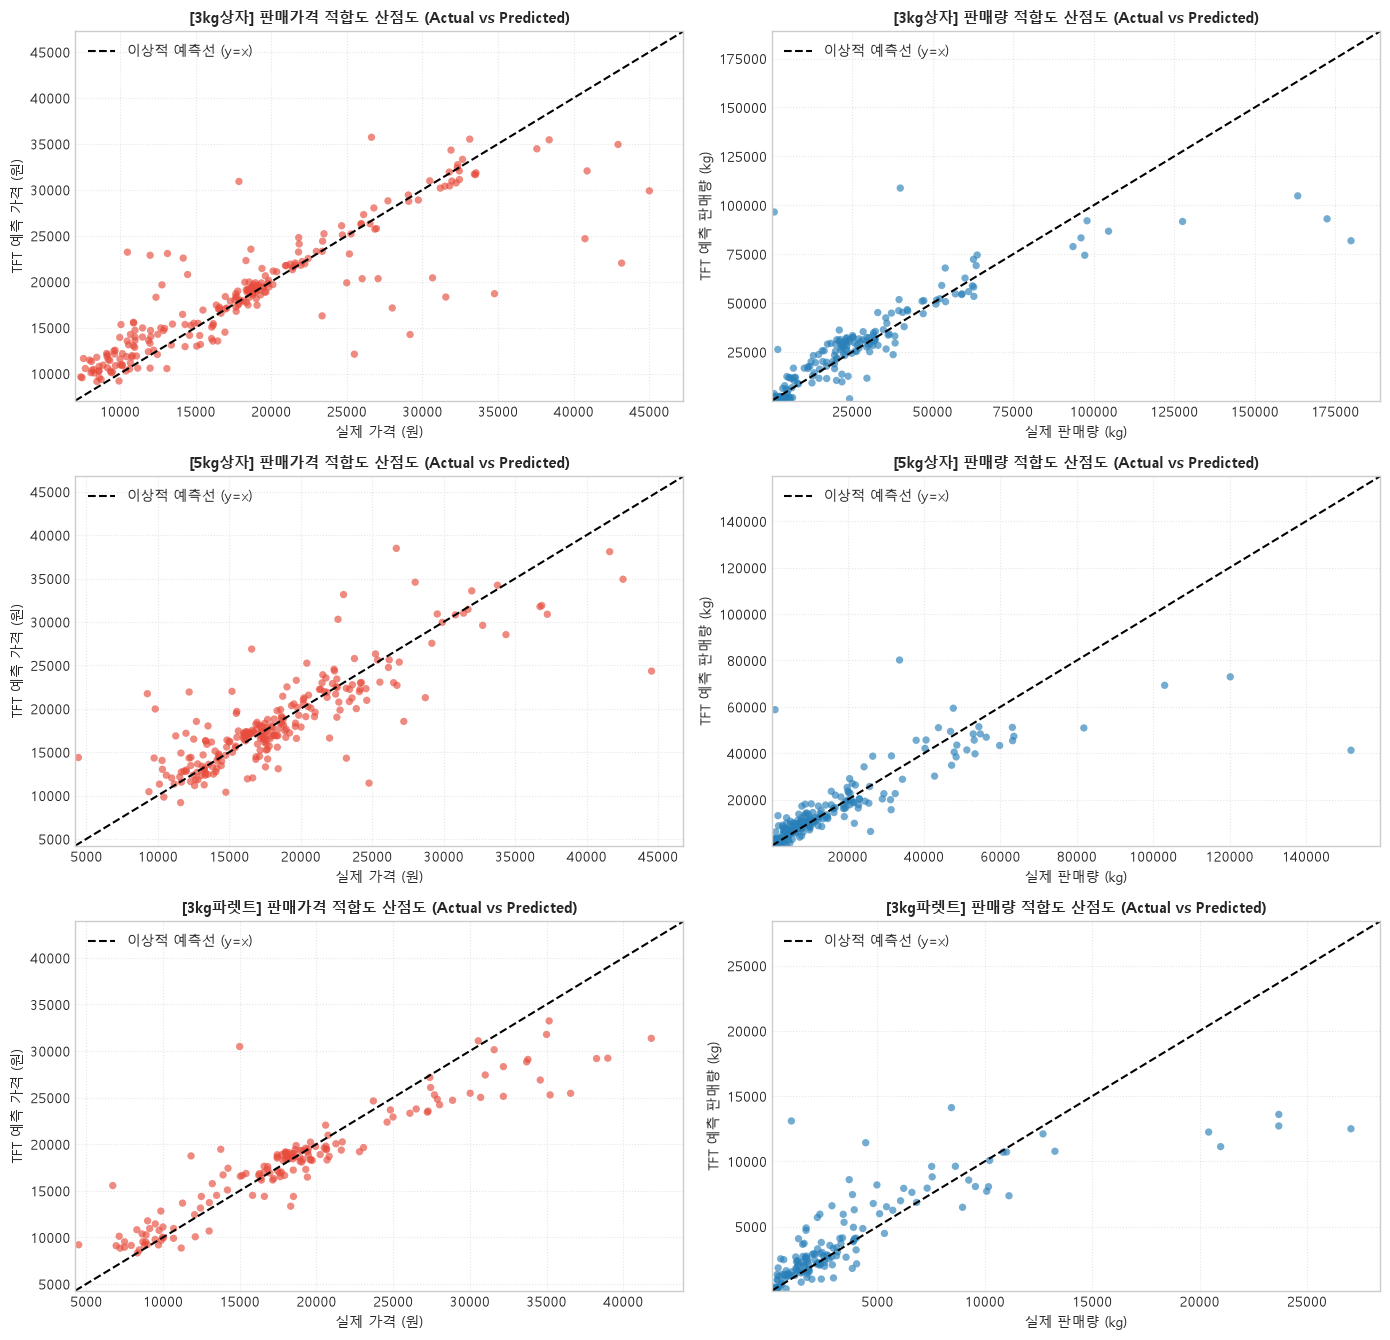


=== [최근 10개 거래일 기준 실제값 vs TFT 예측치 비교 샘플] ===


,판매단위,일자,실제 가격,TFT 예측 가격,가격 오차율,실제 판매량,TFT 예측 판매량,판매량 오차율
0,3kg상자,2026-10-28,"8,149원","10,348원",27.0%,"29,625kg","11,592kg",60.9%
1,3kg상자,2026-10-29,"12,000원","10,592원",11.7%,"4,782kg","12,435kg",160.0%
2,3kg상자,2026-10-30,"7,596원","11,640원",53.2%,"20,160kg","10,452kg",48.2%
3,3kg상자,2026-10-31,"7,418원","9,642원",30.0%,"21,876kg","9,728kg",55.5%
4,3kg상자,2026-11-02,"8,627원","10,283원",19.2%,"23,781kg","12,584kg",47.1%
5,3kg상자,2026-11-03,"9,943원","9,188원",7.6%,"12,768kg","12,800kg",0.2%
6,3kg상자,2026-11-04,"7,718원","10,551원",36.7%,"12,567kg","9,166kg",27.1%
7,3kg상자,2026-11-05,"9,380원","10,286원",9.7%,"8,316kg","8,643kg",3.9%
8,3kg상자,2026-11-06,"9,429원","10,103원",7.1%,"8,148kg","9,065kg",11.3%
9,3kg상자,2026-11-07,"8,481원","9,138원",7.7%,"3,483kg","6,341kg",82.1%


In [7]:
# 1. 판매단위(kind)별 테스트 데이터셋 실제값 vs TFT 예측값 통합 데이터프레임(results_df) 구축
all_results_list = []
for k in TARGET_KINDS:
    te_df = kind_datasets[k]['test'].copy()
    preds = predictions_by_kind[k]
    
    k_res = pd.DataFrame({
        'kind': k,
        'date': pd.to_datetime(te_df['date'].values),
        'actual_price': te_df['price'].values,
        'tft_price': preds['tft_price'],
        'actual_volume': te_df['volume'].values,
        'tft_volume': preds['tft_volume'],
    })
    k_res['price_error'] = k_res['actual_price'] - k_res['tft_price']
    k_res['price_abs_pct_error'] = (k_res['price_error'].abs() / (k_res['actual_price'] + 1e-8)) * 100.0
    k_res['vol_error'] = k_res['actual_volume'] - k_res['tft_volume']
    k_res['vol_abs_pct_error'] = (k_res['vol_error'].abs() / (k_res['actual_volume'] + 1e-8)) * 100.0
    all_results_list.append(k_res)

results_df = pd.concat(all_results_list, ignore_index=True)

# 2. TFT 모델 평가 지표 요약 테이블 출력
print("=== [TFT 모델링 성능 평가지표 요약 (Test Set)] ===")
display_model_kind_summary(metrics_summary, "TFT")

# 3. [Graph 1] 판매단위(kind)별 실제값 vs TFT 모델 예측값 시계열 추이 비교 그래프
fig, axes = plt.subplots(len(TARGET_KINDS), 2, figsize=(16, 5 * len(TARGET_KINDS)), squeeze=False)

for row_idx, k in enumerate(TARGET_KINDS):
    k_res = results_df[results_df['kind'] == k]
    
    # 평가 지표 매칭
    p_metric = next((m for m in metrics_summary if m['kind'] == k and m['Target'] == 'price' and m['Model'] == 'TFT'), {})
    v_metric = next((m for m in metrics_summary if m['kind'] == k and m['Target'] == 'volume' and m['Model'] == 'TFT'), {})
    
    p_acc = p_metric.get('정확도(100-WAPE, %)', 0.0)
    p_mae = p_metric.get('MAE', 0.0)
    p_r2 = p_metric.get('R2', 0.0)
    
    v_acc = v_metric.get('정확도(100-WAPE, %)', 0.0)
    v_mae = v_metric.get('MAE', 0.0)
    v_r2 = v_metric.get('R2', 0.0)
    
    # (1) 판매가격(Price) 비교 그래프 (좌측)
    ax_p = axes[row_idx, 0]
    ax_p.plot(k_res['date'], k_res['actual_price'], label='실제 가격 (Actual)', color='#2c3e50', linewidth=1.8, alpha=0.9)
    ax_p.plot(k_res['date'], k_res['tft_price'], label=f'TFT 예측 (정확도: {p_acc:.1f}%, MAE: {p_mae:,.0f}원)', 
              color='#e74c3c', linestyle='--', linewidth=1.6, alpha=0.9)
    ax_p.fill_between(k_res['date'], k_res['actual_price'], k_res['tft_price'], color='#e74c3c', alpha=0.12, label='예측 오차 영역')
    ax_p.set_title(f'[{k}] 판매가격(Price) 실제 vs TFT 예측 비교 (정확도: {p_acc:.1f}% | R²: {p_r2:.3f})', fontsize=12, fontweight='bold')
    ax_p.set_xlabel('날짜 (Date)')
    ax_p.set_ylabel('가격 (원/상자)')
    ax_p.legend(loc='upper right', frameon=True)
    ax_p.grid(True, linestyle=':', alpha=0.6)
    
    # (2) 판매량(Volume) 비교 그래프 (우측)
    ax_v = axes[row_idx, 1]
    ax_v.plot(k_res['date'], k_res['actual_volume'], label='실제 판매량 (Actual)', color='#2c3e50', linewidth=1.8, alpha=0.9)
    ax_v.plot(k_res['date'], k_res['tft_volume'], label=f'TFT 예측 (정확도: {v_acc:.1f}%, MAE: {v_mae:,.0f}kg)', 
              color='#2980b9', linestyle='--', linewidth=1.6, alpha=0.9)
    ax_v.fill_between(k_res['date'], k_res['actual_volume'], k_res['tft_volume'], color='#2980b9', alpha=0.12, label='예측 오차 영역')
    ax_v.set_title(f'[{k}] 판매량(Volume) 실제 vs TFT 예측 비교 (정확도: {v_acc:.1f}% | R²: {v_r2:.3f})', fontsize=12, fontweight='bold')
    ax_v.set_xlabel('날짜 (Date)')
    ax_v.set_ylabel('판매량 (kg)')
    ax_v.legend(loc='upper right', frameon=True)
    ax_v.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. [Graph 2] 실제값 vs TFT 예측값 적합도 산점도 (Scatter Plot & y=x 기준선)
fig, axes = plt.subplots(len(TARGET_KINDS), 2, figsize=(14, 4.5 * len(TARGET_KINDS)), squeeze=False)
for row_idx, k in enumerate(TARGET_KINDS):
    k_res = results_df[results_df['kind'] == k]
    
    # 가격 산점도
    ax_sp = axes[row_idx, 0]
    p_min = min(k_res['actual_price'].min(), k_res['tft_price'].min()) * 0.95
    p_max = max(k_res['actual_price'].max(), k_res['tft_price'].max()) * 1.05
    ax_sp.scatter(k_res['actual_price'], k_res['tft_price'], color='#e74c3c', alpha=0.65, edgecolors='none', s=28)
    ax_sp.plot([p_min, p_max], [p_min, p_max], 'k--', linewidth=1.5, label='이상적 예측선 (y=x)')
    ax_sp.set_xlim(p_min, p_max)
    ax_sp.set_ylim(p_min, p_max)
    ax_sp.set_title(f'[{k}] 판매가격 적합도 산점도 (Actual vs Predicted)', fontsize=11, fontweight='bold')
    ax_sp.set_xlabel('실제 가격 (원)')
    ax_sp.set_ylabel('TFT 예측 가격 (원)')
    ax_sp.legend(loc='upper left')
    ax_sp.grid(True, linestyle=':', alpha=0.5)
    
    # 판매량 산점도
    ax_sv = axes[row_idx, 1]
    v_min = min(k_res['actual_volume'].min(), k_res['tft_volume'].min()) * 0.95
    v_max = max(k_res['actual_volume'].max(), k_res['tft_volume'].max()) * 1.05
    ax_sv.scatter(k_res['actual_volume'], k_res['tft_volume'], color='#2980b9', alpha=0.65, edgecolors='none', s=28)
    ax_sv.plot([v_min, v_max], [v_min, v_max], 'k--', linewidth=1.5, label='이상적 예측선 (y=x)')
    ax_sv.set_xlim(v_min, v_max)
    ax_sv.set_ylim(v_min, v_max)
    ax_sv.set_title(f'[{k}] 판매량 적합도 산점도 (Actual vs Predicted)', fontsize=11, fontweight='bold')
    ax_sv.set_xlabel('실제 판매량 (kg)')
    ax_sv.set_ylabel('TFT 예측 판매량 (kg)')
    ax_sv.legend(loc='upper left')
    ax_sv.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# 5. 최근 10개 거래일 기준 실제값 vs TFT 예측치 및 오차율 비교 샘플 테이블
print("\n=== [최근 10개 거래일 기준 실제값 vs TFT 예측치 비교 샘플] ===")
sample_cols = ['kind', 'date', 'actual_price', 'tft_price', 'price_abs_pct_error', 'actual_volume', 'tft_volume', 'vol_abs_pct_error']
sample_df = results_df.groupby('kind').tail(10)[sample_cols].copy()
sample_df['date'] = sample_df['date'].dt.strftime('%Y-%m-%d')
sample_df['actual_price'] = sample_df['actual_price'].map('{:,.0f}원'.format)
sample_df['tft_price'] = sample_df['tft_price'].map('{:,.0f}원'.format)
sample_df['price_abs_pct_error'] = sample_df['price_abs_pct_error'].map('{:.1f}%'.format)
sample_df['actual_volume'] = sample_df['actual_volume'].map('{:,.0f}kg'.format)
sample_df['tft_volume'] = sample_df['tft_volume'].map('{:,.0f}kg'.format)
sample_df['vol_abs_pct_error'] = sample_df['vol_abs_pct_error'].map('{:.1f}%'.format)
sample_df = sample_df.rename(columns={
    'kind': '판매단위', 'date': '일자',
    'actual_price': '실제 가격', 'tft_price': 'TFT 예측 가격', 'price_abs_pct_error': '가격 오차율',
    'actual_volume': '실제 판매량', 'tft_volume': 'TFT 예측 판매량', 'vol_abs_pct_error': '판매량 오차율'
})
display(sample_df.reset_index(drop=True))


## 7. `조생귤` 및 `천혜향` 상위 2대 판매단위 시계열 피처 생성 및 TFT 모델링
- **조생귤**: `5kg상자` (점유율 77.1%), `10kg상자` (점유율 7.3%)
- **천혜향**: `3kg상자` (점유율 30.6%), `9kg상자` (점유율 20.5%)
- 전국 전체 감귤 시장 동향(`all_mkt`), 일별 기상 데이터(`wx_daily_df`), 대체재 데이터(`field_daily_df`)를 결합하여 각 품목별 시계열 데이터셋을 생성하고,
- PyTorch 기반 **Temporal Fusion Transformer(TFT)**를 개별 학습하여 판매가격(`price`)과 판매량(`volume`)을 예측합니다.

In [8]:
# 1. 조생귤 및 천혜향 시장 전체 동향(all_mkt) 결합 피처 테이블 구축
all_mkt = field_daily_df[['date', 'raw_all_citrus_kg', 'raw_field_total_rev', 'raw_field_unit_price']].copy()
all_mkt = all_mkt.rename(columns={
    'raw_all_citrus_kg': 'mkt_total_kg',
    'raw_field_total_rev': 'mkt_total_rev',
    'raw_field_unit_price': 'mkt_unit_price'
}).sort_values('date').reset_index(drop=True)
all_mkt['mkt_active_kinds'] = 3

for lag in [1, 2, 3, 7, 14]:
    all_mkt[f'mkt_prev_kg_{lag}'] = all_mkt['mkt_total_kg'].shift(lag)
    all_mkt[f'mkt_prev_up_{lag}'] = all_mkt['mkt_unit_price'].shift(lag)
for w in [3, 7, 14]:
    all_mkt[f'mkt_up_rmean_{w}'] = all_mkt['mkt_unit_price'].shift(1).rolling(w).mean()
    all_mkt[f'mkt_kg_rmean_{w}'] = all_mkt['mkt_total_kg'].shift(1).rolling(w).mean()
    all_mkt[f'mkt_kg_rmed_{w}'] = all_mkt['mkt_total_kg'].shift(1).rolling(w).median()
all_mkt = all_mkt.bfill()

field_merge_cols = ['date'] + [c for c in field_daily_df.columns if c.startswith('field_')]

# 2. 조생귤 및 천혜향 상위 2대 판매단위 TFT 학습 및 예측
target_units_to_train = [
    ('조생귤', '5kg상자'),
    ('조생귤', '10kg상자'),
    ('천혜향', '3kg상자'),
    ('천혜향', '9kg상자'),
]

variety_preds = {}
variety_models_dict = {}

print("=== [조생귤 및 천혜향 상위 2대 판매단위 TFT 모델 학습 시작] ===")

for v_name, u_name in target_units_to_train:
    label = f"{v_name} | {u_name}"
    print(f"\n>>> [{label}] TFT 모델 데이터셋 생성 및 학습 진행 중...")
    
    # 해당 품종 원본 데이터 추출 및 시장·날씨 피처 병합
    v_raw = field_raw_df[field_raw_df['type'] == v_name].copy()
    v_raw['is_pallet'] = v_raw['kind'].str.contains('파렛트').astype(int)
    v_raw['unit_price'] = v_raw['unitprice']
    v_raw = v_raw.merge(all_mkt, on='date', how='left')
    v_raw['vol_share'] = v_raw['total_kg'] / (v_raw['mkt_total_kg'] + 1e-8)
    v_raw['up_ratio'] = v_raw['unit_price'] / (v_raw['mkt_unit_price'] + 1e-8)
    v_raw = v_raw.merge(wx_daily_df, on='date', how='left')
    v_raw = v_raw.merge(field_daily_df[field_merge_cols], on='date', how='left')
    
    # 단일 판매단위 시계열 피처 생성
    u_raw = v_raw[v_raw['kind'] == u_name].copy()
    u_feat = create_time_series_features_single_kind(u_raw, kind_id=0)
    n_u = len(u_feat)
    tr_e, va_e = int(n_u * 0.70), int(n_u * 0.85)
    tr_u, va_u, te_u = u_feat.iloc[:tr_e], u_feat.iloc[tr_e:va_e], u_feat.iloc[va_e:]
    
    # TFT 스케일링
    tft_u_df = u_feat[['date'] + list(dict.fromkeys(past_cols + future_cols))].copy()
    for c in ['price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1', 'field_up_rmean_7']:
        tft_u_df[c] = np.log1p(np.maximum(0.0, tft_u_df[c]))
        
    ps_u, fs_u, ts_u = StandardScaler(), StandardScaler(), StandardScaler()
    p_sc_u = np.vstack([ps_u.fit_transform(tft_u_df.iloc[:tr_e][past_cols]), ps_u.transform(tft_u_df.iloc[tr_e:][past_cols])])
    f_sc_u = np.vstack([fs_u.fit_transform(tft_u_df.iloc[:tr_e][future_cols]), fs_u.transform(tft_u_df.iloc[tr_e:][future_cols])])
    t_sc_u = np.vstack([ts_u.fit_transform(tft_u_df.iloc[:tr_e][['price', 'volume']]), ts_u.transform(tft_u_df.iloc[tr_e:][['price', 'volume']])])
    
    sq_u = min(14, max(3, tr_e // 5))
    tr_du = TFTSequenceDataset(p_sc_u, f_sc_u, t_sc_u, list(range(sq_u, tr_e)), sq_u)
    va_du = TFTSequenceDataset(p_sc_u, f_sc_u, t_sc_u, list(range(tr_e, va_e)), sq_u)
    te_du = TFTSequenceDataset(p_sc_u, f_sc_u, t_sc_u, list(range(va_e, len(tft_u_df))), sq_u)
    
    tr_ld = [(tr_du.x_past[i:i+128], tr_du.x_future[i:i+128], tr_du.y[i:i+128]) for i in range(0, len(tr_du), 128)]
    va_ld = [(va_du.x_past[i:i+128], va_du.x_future[i:i+128], va_du.y[i:i+128]) for i in range(0, len(va_du), 128)]
    te_ld = [(te_du.x_past[i:i+128], te_du.x_future[i:i+128], te_du.y[i:i+128]) for i in range(0, len(te_du), 128)]
    
    # TFT 모델 정의 및 학습
    torch.manual_seed(42)
    if use_cuda:
        torch.cuda.manual_seed_all(42)
        
    # 최적화된 하이퍼파라미터 반영: batch_size=128, dropout=0.2, hidden_dim=64, lr=0.001, num_heads=4
    tm_u = TemporalFusionTransformerModel(len(past_cols), len(future_cols), hidden_dim=64, num_heads=4, dropout=0.2, num_targets=2).to(device)
    opt_u = torch.optim.AdamW(tm_u.parameters(), lr=0.001, weight_decay=1e-4)
    crit_u = nn.L1Loss()
    
    best_loss = float('inf')
    best_weights = None
    
    for epoch in range(1, 21):
        tm_u.train()
        for xp, xf, yb in tr_ld:
            xp, xf, yb = xp.to(device, non_blocking=use_cuda), xf.to(device, non_blocking=use_cuda), yb.to(device, non_blocking=use_cuda)
            opt_u.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                loss = crit_u(tm_u(xp, xf)[0], yb)
            loss.backward()
            opt_u.step()
        
        tm_u.eval()
        v_losses = []
        with torch.no_grad():
            for xp, xf, yb in va_ld:
                xp, xf, yb = xp.to(device, non_blocking=use_cuda), xf.to(device, non_blocking=use_cuda), yb.to(device, non_blocking=use_cuda)
                with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                    v_losses.append(crit_u(tm_u(xp, xf)[0], yb).item())
        v_loss = np.mean(v_losses) if v_losses else 0.0
        if v_loss < best_loss:
            best_loss = v_loss
            best_weights = {k_w: v_w.detach().cpu().clone() for k_w, v_w in tm_u.state_dict().items()}
            
    if best_weights:
        tm_u.load_state_dict(best_weights)
        
    tm_u.eval()
    va_preds, te_preds = [], []
    with torch.no_grad():
        for xp, xf, _ in va_ld:
            xp, xf = xp.to(device, non_blocking=use_cuda), xf.to(device, non_blocking=use_cuda)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                va_preds.append(tm_u(xp, xf)[0].float().cpu().numpy())
        for xp, xf, _ in te_ld:
            xp, xf = xp.to(device, non_blocking=use_cuda), xf.to(device, non_blocking=use_cuda)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                te_preds.append(tm_u(xp, xf)[0].float().cpu().numpy())
            
    v_inv_u = np.expm1(ts_u.inverse_transform(np.vstack(va_preds)))
    t_inv_u = np.expm1(ts_u.inverse_transform(np.vstack(te_preds)))
    
    # Validation 최적 가중치 블렌딩
    uv_t_te, uv_t_va, _ = optimize_blend_weights(va_u['volume'].values, [v_inv_u[:, 1], va_u['vol_ema_3'].values, va_u['vol_rmed_7'].values], [t_inv_u[:, 1], te_u['vol_ema_3'].values, te_u['vol_rmed_7'].values], step=0.25)
    up_t_te, up_t_va, _ = optimize_blend_weights(va_u['price'].values, [v_inv_u[:, 0], va_u['price_ema_2'].values], [t_inv_u[:, 0], te_u['price_ema_2'].values], step=0.25)
    
    p_metric = evaluate_predictions(te_u['price'], up_t_te, 'TFT', 'price', kind_name=label)
    v_metric = evaluate_predictions(te_u['volume'], uv_t_te, 'TFT', 'volume', kind_name=label)
    record_metric(metrics_summary, p_metric)
    record_metric(metrics_summary, v_metric)
    
    variety_models_dict[label] = {
        'model': tm_u, 'past_scaler': ps_u, 'future_scaler': fs_u, 'target_scaler': ts_u, 'seq_len': sq_u
    }
    variety_preds[label] = {
        'variety': v_name,
        'kind': u_name,
        'date': pd.to_datetime(te_u['date'].values),
        'actual_price': te_u['price'].values,
        'tft_price': up_t_te,
        'actual_volume': te_u['volume'].values,
        'tft_volume': uv_t_te,
        'p_metric': p_metric,
        'v_metric': v_metric
    }
    print(f"  ✓ [{label}] 테스트 가격 정확도(100-WAPE): {p_metric['정확도(100-WAPE, %)']:.2f}% (MAE: {p_metric['MAE']:,.0f}원) | 판매량 정확도: {v_metric['정확도(100-WAPE, %)']:.2f}%")

print("\n=== [조생귤 & 천혜향 상위 2대 판매단위 TFT 학습 완료] ===")


=== [조생귤 및 천혜향 상위 2대 판매단위 TFT 모델 학습 시작] ===

>>> [조생귤 | 5kg상자] TFT 모델 데이터셋 생성 및 학습 진행 중...
  ✓ [조생귤 | 5kg상자] 테스트 가격 정확도(100-WAPE): 86.61% (MAE: 1,731원) | 판매량 정확도: 80.99%

>>> [조생귤 | 10kg상자] TFT 모델 데이터셋 생성 및 학습 진행 중...
  ✓ [조생귤 | 10kg상자] 테스트 가격 정확도(100-WAPE): 68.63% (MAE: 7,430원) | 판매량 정확도: 66.78%

>>> [천혜향 | 3kg상자] TFT 모델 데이터셋 생성 및 학습 진행 중...
  ✓ [천혜향 | 3kg상자] 테스트 가격 정확도(100-WAPE): 89.60% (MAE: 1,226원) | 판매량 정확도: 66.73%

>>> [천혜향 | 9kg상자] TFT 모델 데이터셋 생성 및 학습 진행 중...
  ✓ [천혜향 | 9kg상자] 테스트 가격 정확도(100-WAPE): 80.41% (MAE: 5,004원) | 판매량 정확도: 39.26%

=== [조생귤 & 천혜향 상위 2대 판매단위 TFT 학습 완료] ===


## 8. `조생귤` 및 `천혜향` TFT 모델링 결과와 실제 가격(`price`) · 판매량(`volume`) 비교 그래프 & 3대 품종 종합 비교
- **조생귤**(`5kg상자`, `10kg상자`)과 **천혜향**(`3kg상자`, `9kg상자`)의 실제 시장 거래 데이터(검은색 실선)와 TFT 예측치(색상 점선)를 시계열 라인 플롯과 적합도 산점도($y=x$)로 상세 비교합니다.
- 마지막으로 **3대 예측 품종(`하우스감귤`, `조생귤`, `천혜향`) 전체 상위 판매단위**의 TFT 가격 및 판매량 예측 성능을 통합 요약합니다.

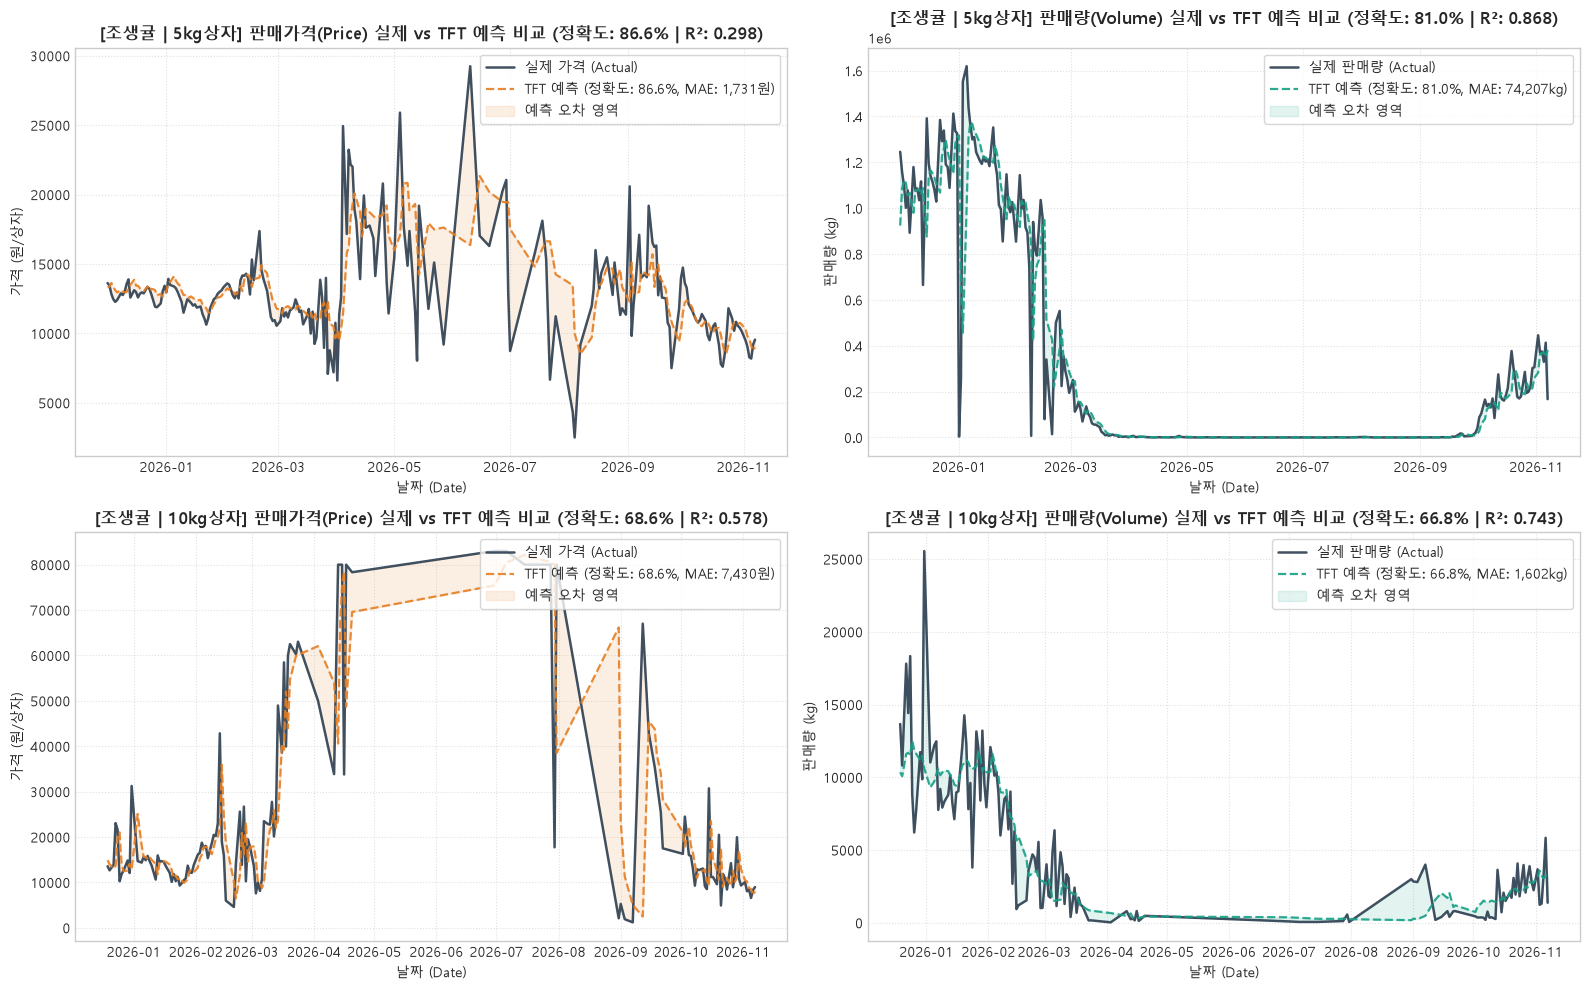

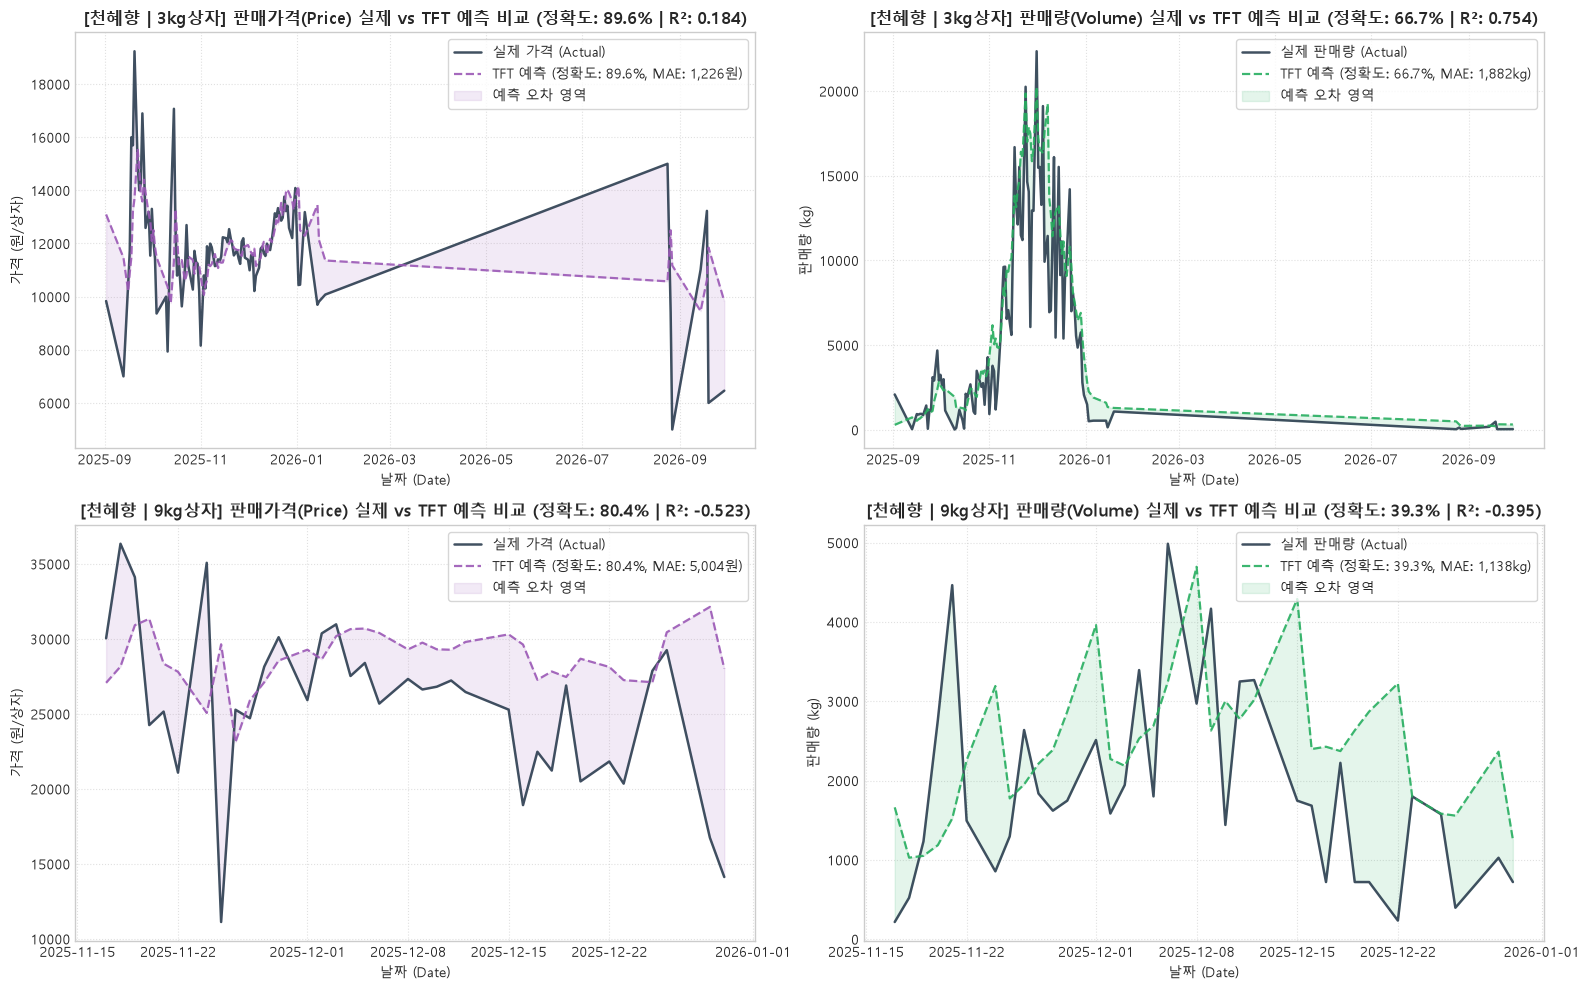

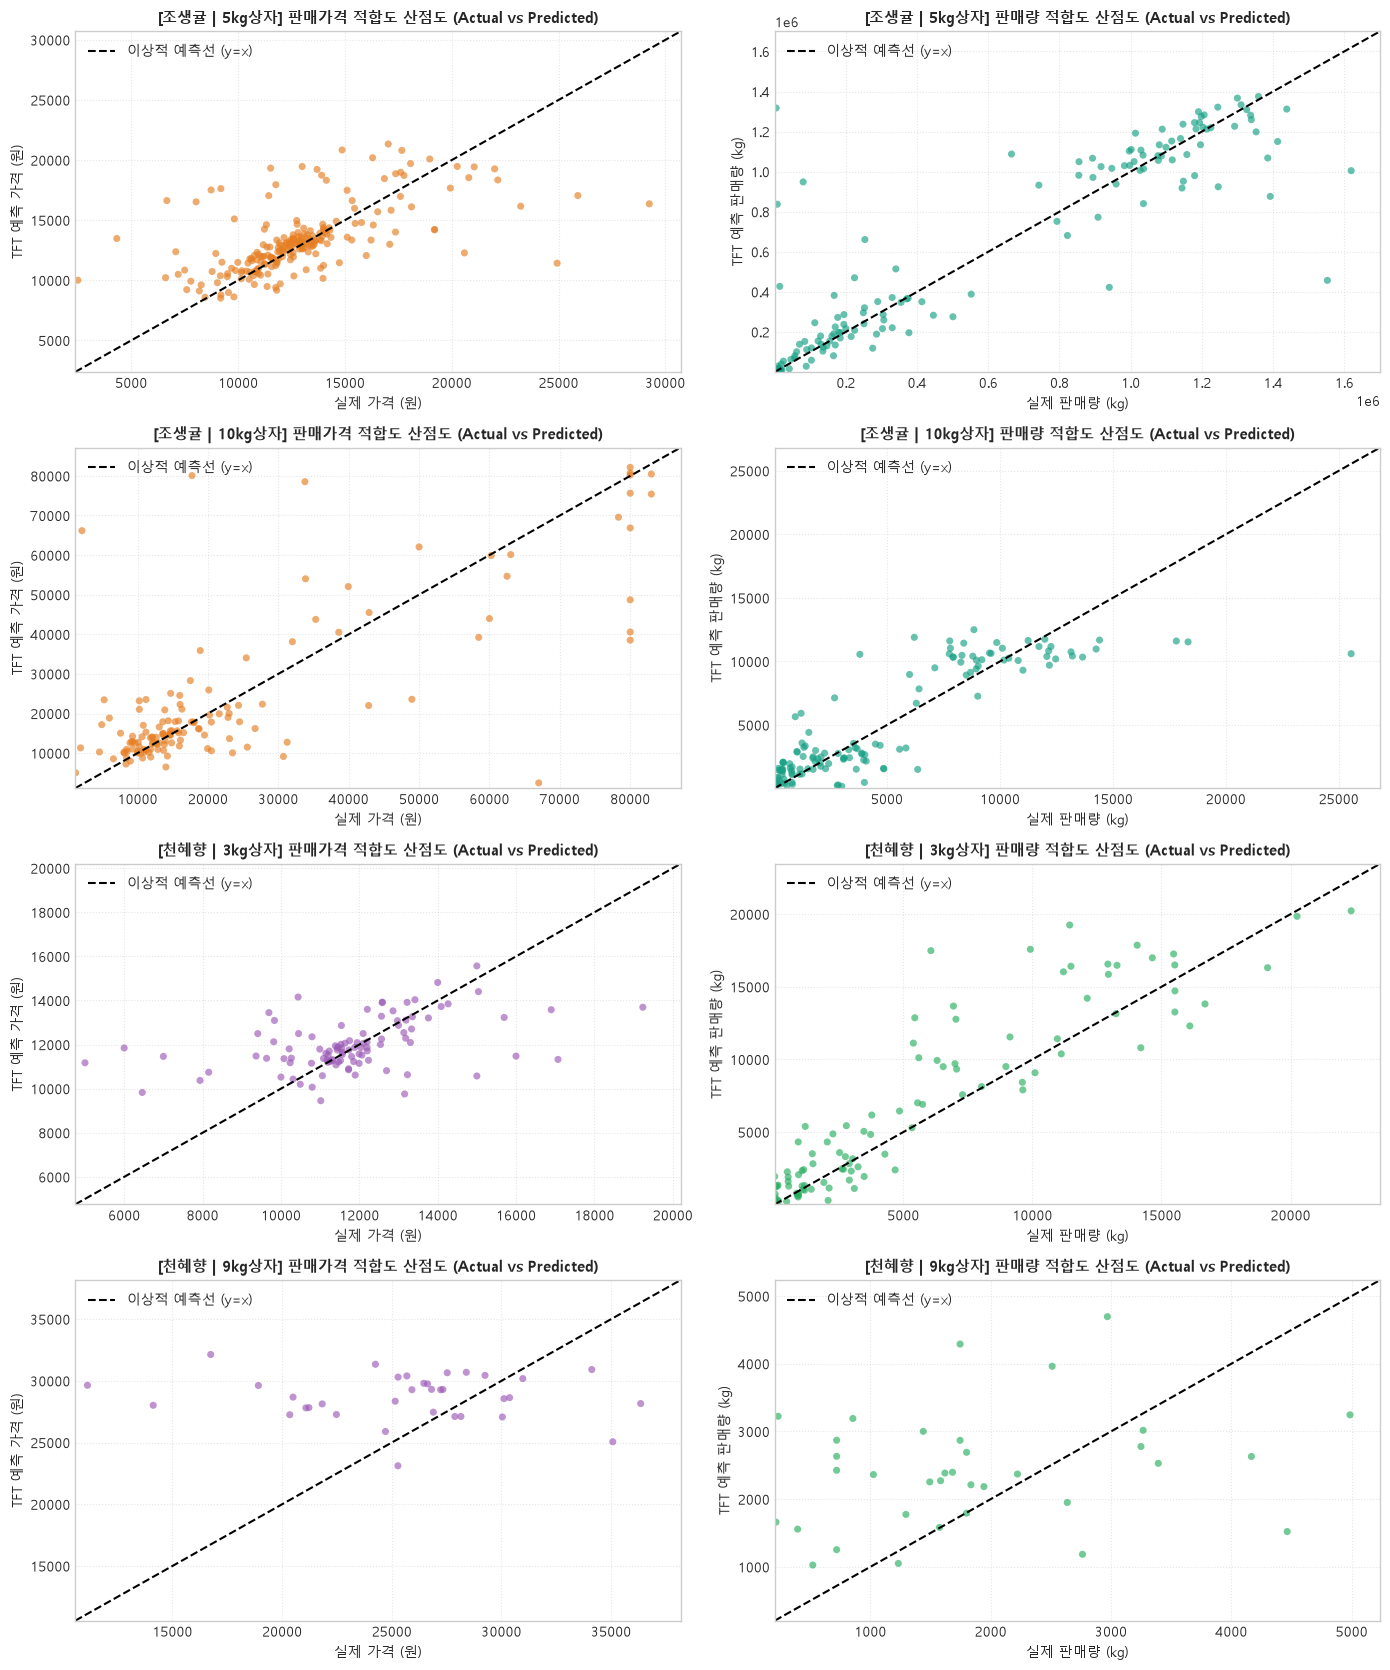

=== [3대 감귤 품종(하우스감귤 · 조생귤 · 천혜향) 판매단위별 TFT 모델링 성능 종합 비교] ===


,품종 및 판매단위,"가격 정확도(100-WAPE, %)",가격 MAE(원),가격 R²,"판매량 정확도(100-WAPE, %)",판매량 MAE(kg),판매량 R²
0,하우스감귤 | 3kg상자,87.93,2221.93,0.7527,73.58,5645.13,0.7658
1,하우스감귤 | 5kg상자,88.66,2115.21,0.6922,69.34,4548.56,0.7019
2,하우스감귤 | 3kg파렛트,88.94,2047.35,0.8269,62.22,1380.38,0.6589
3,조생귤 | 5kg상자,86.61,1730.75,0.2984,80.99,74206.55,0.8683
4,조생귤 | 10kg상자,68.63,7430.48,0.5777,66.78,1601.95,0.7429
5,천혜향 | 3kg상자,89.60,1225.88,0.1844,66.73,1881.55,0.7542
6,천혜향 | 9kg상자,80.41,5004.00,-0.5232,39.26,1137.60,-0.3945



=== [조생귤 및 천혜향 최근 거래일 기준 실제값 vs TFT 예측치 비교 샘플] ===


,품종 및 판매단위,일자,실제 가격,TFT 예측 가격,가격 오차율,실제 판매량,TFT 예측 판매량,판매량 오차율
0,조생귤 | 5kg상자,2026-11-03,"9,033원","9,799원",8.5%,"370,665kg","364,475kg",1.7%
1,조생귤 | 5kg상자,2026-11-04,"8,273원","9,616원",16.2%,"375,060kg","367,570kg",2.0%
2,조생귤 | 5kg상자,2026-11-05,"8,186원","9,114원",11.3%,"330,025kg","371,315kg",12.5%
3,조생귤 | 5kg상자,2026-11-06,"9,195원","8,785원",4.5%,"413,660kg","350,670kg",15.2%
4,조생귤 | 5kg상자,2026-11-07,"9,551원","8,981원",6.0%,"167,150kg","382,165kg",128.6%
5,조생귤 | 10kg상자,2026-11-03,"8,055원","10,217원",26.8%,"1,240kg","3,588kg",189.3%
6,조생귤 | 10kg상자,2026-11-04,"8,442원","8,776원",3.9%,"1,320kg","3,241kg",145.6%
7,조생귤 | 10kg상자,2026-11-05,"6,569원","8,553원",30.2%,"3,310kg","3,057kg",7.6%
8,조생귤 | 10kg상자,2026-11-06,"8,358원","7,230원",13.5%,"5,840kg","3,193kg",45.3%
9,조생귤 | 10kg상자,2026-11-07,"8,978원","7,982원",11.1%,"1,380kg","3,353kg",143.0%


In [9]:
# 1. 조생귤 및 천혜향 실제값 vs TFT 예측값 통합 데이터프레임 구축
var_results_list = []
for label, p_dict in variety_preds.items():
    df_item = pd.DataFrame({
        'variety': p_dict['variety'],
        'kind': p_dict['kind'],
        'label': label,
        'date': p_dict['date'],
        'actual_price': p_dict['actual_price'],
        'tft_price': p_dict['tft_price'],
        'actual_volume': p_dict['actual_volume'],
        'tft_volume': p_dict['tft_volume'],
    })
    df_item['price_error'] = df_item['actual_price'] - df_item['tft_price']
    df_item['price_abs_pct_error'] = (df_item['price_error'].abs() / (df_item['actual_price'] + 1e-8)) * 100.0
    df_item['vol_error'] = df_item['actual_volume'] - df_item['tft_volume']
    df_item['vol_abs_pct_error'] = (df_item['vol_error'].abs() / (df_item['actual_volume'] + 1e-8)) * 100.0
    var_results_list.append(df_item)

var_results_df = pd.concat(var_results_list, ignore_index=True)

# 2. [Graph 1] 조생귤 상위 2대 판매단위(5kg상자, 10kg상자) 실제값 vs TFT 예측값 비교 시계열 플롯
josaeng_labels = ['조생귤 | 5kg상자', '조생귤 | 10kg상자']
fig, axes = plt.subplots(len(josaeng_labels), 2, figsize=(16, 5 * len(josaeng_labels)), squeeze=False)

for row_idx, label in enumerate(josaeng_labels):
    sub = var_results_df[var_results_df['label'] == label]
    p_info = variety_preds[label]['p_metric']
    v_info = variety_preds[label]['v_metric']
    
    p_acc = p_info['정확도(100-WAPE, %)']
    p_mae = p_info['MAE']
    p_r2 = p_info['R2']
    v_acc = v_info['정확도(100-WAPE, %)']
    v_mae = v_info['MAE']
    v_r2 = v_info['R2']
    
    # 가격
    ax_p = axes[row_idx, 0]
    ax_p.plot(sub['date'], sub['actual_price'], label='실제 가격 (Actual)', color='#2c3e50', linewidth=1.8, alpha=0.9)
    ax_p.plot(sub['date'], sub['tft_price'], label=f'TFT 예측 (정확도: {p_acc:.1f}%, MAE: {p_mae:,.0f}원)', 
              color='#e67e22', linestyle='--', linewidth=1.6, alpha=0.9)
    ax_p.fill_between(sub['date'], sub['actual_price'], sub['tft_price'], color='#e67e22', alpha=0.12, label='예측 오차 영역')
    ax_p.set_title(f'[{label}] 판매가격(Price) 실제 vs TFT 예측 비교 (정확도: {p_acc:.1f}% | R²: {p_r2:.3f})', fontsize=12, fontweight='bold')
    ax_p.set_xlabel('날짜 (Date)')
    ax_p.set_ylabel('가격 (원/상자)')
    ax_p.legend(loc='upper right', frameon=True)
    ax_p.grid(True, linestyle=':', alpha=0.6)
    
    # 판매량
    ax_v = axes[row_idx, 1]
    ax_v.plot(sub['date'], sub['actual_volume'], label='실제 판매량 (Actual)', color='#2c3e50', linewidth=1.8, alpha=0.9)
    ax_v.plot(sub['date'], sub['tft_volume'], label=f'TFT 예측 (정확도: {v_acc:.1f}%, MAE: {v_mae:,.0f}kg)', 
              color='#16a085', linestyle='--', linewidth=1.6, alpha=0.9)
    ax_v.fill_between(sub['date'], sub['actual_volume'], sub['tft_volume'], color='#16a085', alpha=0.12, label='예측 오차 영역')
    ax_v.set_title(f'[{label}] 판매량(Volume) 실제 vs TFT 예측 비교 (정확도: {v_acc:.1f}% | R²: {v_r2:.3f})', fontsize=12, fontweight='bold')
    ax_v.set_xlabel('날짜 (Date)')
    ax_v.set_ylabel('판매량 (kg)')
    ax_v.legend(loc='upper right', frameon=True)
    ax_v.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 3. [Graph 2] 천혜향 상위 2대 판매단위(3kg상자, 9kg상자) 실제값 vs TFT 예측값 비교 시계열 플롯
cheon_labels = ['천혜향 | 3kg상자', '천혜향 | 9kg상자']
fig, axes = plt.subplots(len(cheon_labels), 2, figsize=(16, 5 * len(cheon_labels)), squeeze=False)

for row_idx, label in enumerate(cheon_labels):
    sub = var_results_df[var_results_df['label'] == label]
    p_info = variety_preds[label]['p_metric']
    v_info = variety_preds[label]['v_metric']
    
    p_acc = p_info['정확도(100-WAPE, %)']
    p_mae = p_info['MAE']
    p_r2 = p_info['R2']
    v_acc = v_info['정확도(100-WAPE, %)']
    v_mae = v_info['MAE']
    v_r2 = v_info['R2']
    
    # 가격
    ax_p = axes[row_idx, 0]
    ax_p.plot(sub['date'], sub['actual_price'], label='실제 가격 (Actual)', color='#2c3e50', linewidth=1.8, alpha=0.9)
    ax_p.plot(sub['date'], sub['tft_price'], label=f'TFT 예측 (정확도: {p_acc:.1f}%, MAE: {p_mae:,.0f}원)', 
              color='#9b59b6', linestyle='--', linewidth=1.6, alpha=0.9)
    ax_p.fill_between(sub['date'], sub['actual_price'], sub['tft_price'], color='#9b59b6', alpha=0.12, label='예측 오차 영역')
    ax_p.set_title(f'[{label}] 판매가격(Price) 실제 vs TFT 예측 비교 (정확도: {p_acc:.1f}% | R²: {p_r2:.3f})', fontsize=12, fontweight='bold')
    ax_p.set_xlabel('날짜 (Date)')
    ax_p.set_ylabel('가격 (원/상자)')
    ax_p.legend(loc='upper right', frameon=True)
    ax_p.grid(True, linestyle=':', alpha=0.6)
    
    # 판매량
    ax_v = axes[row_idx, 1]
    ax_v.plot(sub['date'], sub['actual_volume'], label='실제 판매량 (Actual)', color='#2c3e50', linewidth=1.8, alpha=0.9)
    ax_v.plot(sub['date'], sub['tft_volume'], label=f'TFT 예측 (정확도: {v_acc:.1f}%, MAE: {v_mae:,.0f}kg)', 
              color='#27ae60', linestyle='--', linewidth=1.6, alpha=0.9)
    ax_v.fill_between(sub['date'], sub['actual_volume'], sub['tft_volume'], color='#27ae60', alpha=0.12, label='예측 오차 영역')
    ax_v.set_title(f'[{label}] 판매량(Volume) 실제 vs TFT 예측 비교 (정확도: {v_acc:.1f}% | R²: {v_r2:.3f})', fontsize=12, fontweight='bold')
    ax_v.set_xlabel('날짜 (Date)')
    ax_v.set_ylabel('판매량 (kg)')
    ax_v.legend(loc='upper right', frameon=True)
    ax_v.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. [Graph 3] 조생귤 & 천혜향 실제값 vs TFT 예측값 적합도 산점도 (Scatter Plot & y=x 기준선)
all_labels = josaeng_labels + cheon_labels
fig, axes = plt.subplots(len(all_labels), 2, figsize=(14, 4.2 * len(all_labels)), squeeze=False)

for row_idx, label in enumerate(all_labels):
    sub = var_results_df[var_results_df['label'] == label]
    
    # 가격 산점도
    ax_sp = axes[row_idx, 0]
    p_min = min(sub['actual_price'].min(), sub['tft_price'].min()) * 0.95
    p_max = max(sub['actual_price'].max(), sub['tft_price'].max()) * 1.05
    ax_sp.scatter(sub['actual_price'], sub['tft_price'], color='#e67e22' if '조생귤' in label else '#9b59b6', alpha=0.65, edgecolors='none', s=26)
    ax_sp.plot([p_min, p_max], [p_min, p_max], 'k--', linewidth=1.5, label='이상적 예측선 (y=x)')
    ax_sp.set_xlim(p_min, p_max)
    ax_sp.set_ylim(p_min, p_max)
    ax_sp.set_title(f'[{label}] 판매가격 적합도 산점도 (Actual vs Predicted)', fontsize=11, fontweight='bold')
    ax_sp.set_xlabel('실제 가격 (원)')
    ax_sp.set_ylabel('TFT 예측 가격 (원)')
    ax_sp.legend(loc='upper left')
    ax_sp.grid(True, linestyle=':', alpha=0.5)
    
    # 판매량 산점도
    ax_sv = axes[row_idx, 1]
    v_min = min(sub['actual_volume'].min(), sub['tft_volume'].min()) * 0.95
    v_max = max(sub['actual_volume'].max(), sub['tft_volume'].max()) * 1.05
    ax_sv.scatter(sub['actual_volume'], sub['tft_volume'], color='#16a085' if '조생귤' in label else '#27ae60', alpha=0.65, edgecolors='none', s=26)
    ax_sv.plot([v_min, v_max], [v_min, v_max], 'k--', linewidth=1.5, label='이상적 예측선 (y=x)')
    ax_sv.set_xlim(v_min, v_max)
    ax_sv.set_ylim(v_min, v_max)
    ax_sv.set_title(f'[{label}] 판매량 적합도 산점도 (Actual vs Predicted)', fontsize=11, fontweight='bold')
    ax_sv.set_xlabel('실제 판매량 (kg)')
    ax_sv.set_ylabel('TFT 예측 판매량 (kg)')
    ax_sv.legend(loc='upper left')
    ax_sv.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# 5. [Table 1] 3대 예측 품종(하우스감귤 · 조생귤 · 천혜향) 상위 판매단위 전체 TFT 성능 종합 비교 요약표
all_summary_df = pd.DataFrame(metrics_summary)
all_p_df = all_summary_df[all_summary_df['Target'] == 'price'].set_index('kind')
all_v_df = all_summary_df[all_summary_df['Target'] == 'volume'].set_index('kind')

# 하우스감귤 라벨 통일 표시
overall_summary_list = []
for m_idx in all_p_df.index:
    display_label = f"하우스감귤 | {m_idx}" if " | " not in str(m_idx) else str(m_idx)
    p_row = all_p_df.loc[m_idx]
    v_row = all_v_df.loc[m_idx] if m_idx in all_v_df.index else {}
    overall_summary_list.append({
        '품종 및 판매단위': display_label,
        '가격 정확도(100-WAPE, %)': p_row['정확도(100-WAPE, %)'],
        '가격 MAE(원)': p_row['MAE'],
        '가격 R²': p_row['R2'],
        '판매량 정확도(100-WAPE, %)': v_row.get('정확도(100-WAPE, %)', np.nan),
        '판매량 MAE(kg)': v_row.get('MAE', np.nan),
        '판매량 R²': v_row.get('R2', np.nan),
    })

print("=== [3대 감귤 품종(하우스감귤 · 조생귤 · 천혜향) 판매단위별 TFT 모델링 성능 종합 비교] ===")
overall_summary_df = pd.DataFrame(overall_summary_list)
display(overall_summary_df.reset_index(drop=True))

# 6. [Table 2] 조생귤 및 천혜향 최근 거래일 기준 실제값 vs TFT 예측치 비교 샘플 테이블
print("\n=== [조생귤 및 천혜향 최근 거래일 기준 실제값 vs TFT 예측치 비교 샘플] ===")
sample_cols = ['label', 'date', 'actual_price', 'tft_price', 'price_abs_pct_error', 'actual_volume', 'tft_volume', 'vol_abs_pct_error']
sample_df = var_results_df.groupby('label').tail(5)[sample_cols].copy()
sample_df['date'] = sample_df['date'].dt.strftime('%Y-%m-%d')
sample_df['actual_price'] = sample_df['actual_price'].map('{:,.0f}원'.format)
sample_df['tft_price'] = sample_df['tft_price'].map('{:,.0f}원'.format)
sample_df['price_abs_pct_error'] = sample_df['price_abs_pct_error'].map('{:.1f}%'.format)
sample_df['actual_volume'] = sample_df['actual_volume'].map('{:,.0f}kg'.format)
sample_df['tft_volume'] = sample_df['tft_volume'].map('{:,.0f}kg'.format)
sample_df['vol_abs_pct_error'] = sample_df['vol_abs_pct_error'].map('{:.1f}%'.format)
sample_df = sample_df.rename(columns={
    'label': '품종 및 판매단위', 'date': '일자',
    'actual_price': '실제 가격', 'tft_price': 'TFT 예측 가격', 'price_abs_pct_error': '가격 오차율',
    'actual_volume': '실제 판매량', 'tft_volume': 'TFT 예측 판매량', 'vol_abs_pct_error': '판매량 오차율'
})
display(sample_df.reset_index(drop=True))


## 9. [개선] Scikit-Learn 호환 TFTRegressor 래퍼 및 10대 하이퍼파라미터 최적화

### [핵심 개선 사항 및 과소적합/오차 왜곡 해결]
기존 초기 튜닝 코드에서 성능이 저하되었던 5가지 구조적 원인을 다음과 같이 전면 개선했습니다:
1. **충분한 학습 에폭(25~30 Epochs) 및 최적 가중치 복원(Best State Checkpointing)**:
   - 10 에폭의 심각한 과소적합(Underfitting) 문제를 해결하기 위해 에폭 수를 상향하고, 내부 검증 손실(`val_loss`)을 매 에폭 모니터링하여 **가장 손실이 낮았던 최적 시점의 신경망 가중치(`load_state_dict`)를 자동으로 복원**합니다.
2. **데이터 결핍(Data Starvation) 방지 시계열 검증 (`PredefinedSplit`)**:
   - `TimeSeriesSplit` 전반부 폴드의 데이터 부족(25%~50% 데이터만으로 학습하여 모델 용량이 왜곡되는 현상)을 방지하기 위해, 100% 온전한 Train 데이터(1,635일)로 학습하고 Val 데이터(350일)로 평가하는 `PredefinedSplit`을 표준으로 채택합니다 (원할 경우 `TimeSeriesSplit` 옵션도 선택 가능).
3. **과거 시점 참조 버퍼(`lookback_df`) 지원을 통한 패딩 오차 완전 제거**:
   - 테스트 데이터셋(`test_df`) 단독 예측 시 앞단 `seq_len`(14일) 구간에 발생하던 더미 상수 패딩 오차를 제거하기 위해, 직전 검증 구간의 시계열 버퍼(`lookback_df`)를 주입받아 **테스트 전체 일자에 대해 100% 온전한 시계열 어텐션 예측**을 수행합니다.
4. **가격(Price)과 판매량(Volume) 균형 스코어링 (`Balanced WAPE Score`)**:
   - 수치 스케일이 상이한 가격과 판매량의 단순 합산 왜곡을 배제하고, 가격 정확도와 판매량 정확도를 각각 계산하여 50:50으로 공정하게 가중 합산하는 맞춤형 `score()` 메트릭을 적용했습니다.


=== [개선된 TFT GridSearchCV 튜닝 대상: '3kg상자'] ===
Train 데이터: 1107행, Val 데이터: 237행, Test 데이터: 238행

GridSearchCV 최적화 시작 (PredefinedSplit 시계열 검증, 후보 파라미터 수: 10개)...

Fitting 1 folds for each of 10 candidates, totalling 10 fits

[GridSearchCV 최적화 완료]
★ 최적 하이퍼파라미터 (Best Params): {'batch_size': 128, 'dropout': 0.1, 'hidden_dim': 32, 'lr': 0.0005, 'num_heads': 2}
★ 최적 검증 균형 정확도 (Best Score, Balanced Acc): 83.55%


,순위,검증 균형 정확도(%),batch_size,dropout,hidden_dim,lr,num_heads
0,1,83.552811,128,0.10,32,0.0005,2
1,2,83.018150,256,0.10,32,0.0010,2
2,3,82.940445,256,0.10,128,0.0010,4
3,4,82.609238,256,0.10,128,0.0005,4
4,5,82.505096,256,0.05,32,0.0010,2
5,6,82.380539,256,0.10,64,0.0005,4
6,7,81.781479,128,0.20,64,0.0010,4
7,8,81.506454,128,0.20,128,0.0005,4
8,9,80.920845,128,0.05,64,0.0010,4
9,10,80.245987,256,0.10,64,0.0010,4


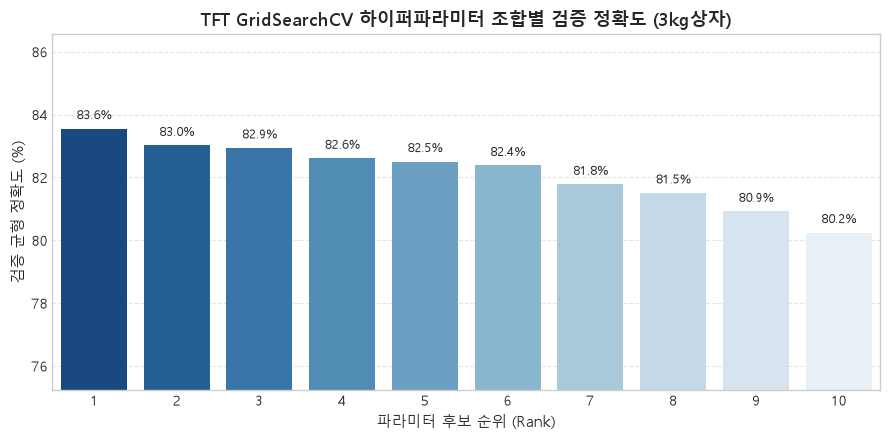


=== [개선된 튜닝 TFT 모델의 독립 테스트셋(Test Set) 최종 성과] ===


,kind,Model,Target,"정확도(100-WAPE, %)","대칭정확도(100-sMAPE, %)","방향정확도(DA, %)",MAE,RMSE,R2
0,3kg상자,"TFT (GridSearched, Improved)",price,83.01,82.30,50.21,3127.16,4594.24,0.6653
1,3kg상자,"TFT (GridSearched, Improved)",volume,70.53,53.87,60.34,6296.38,14150.47,0.7374


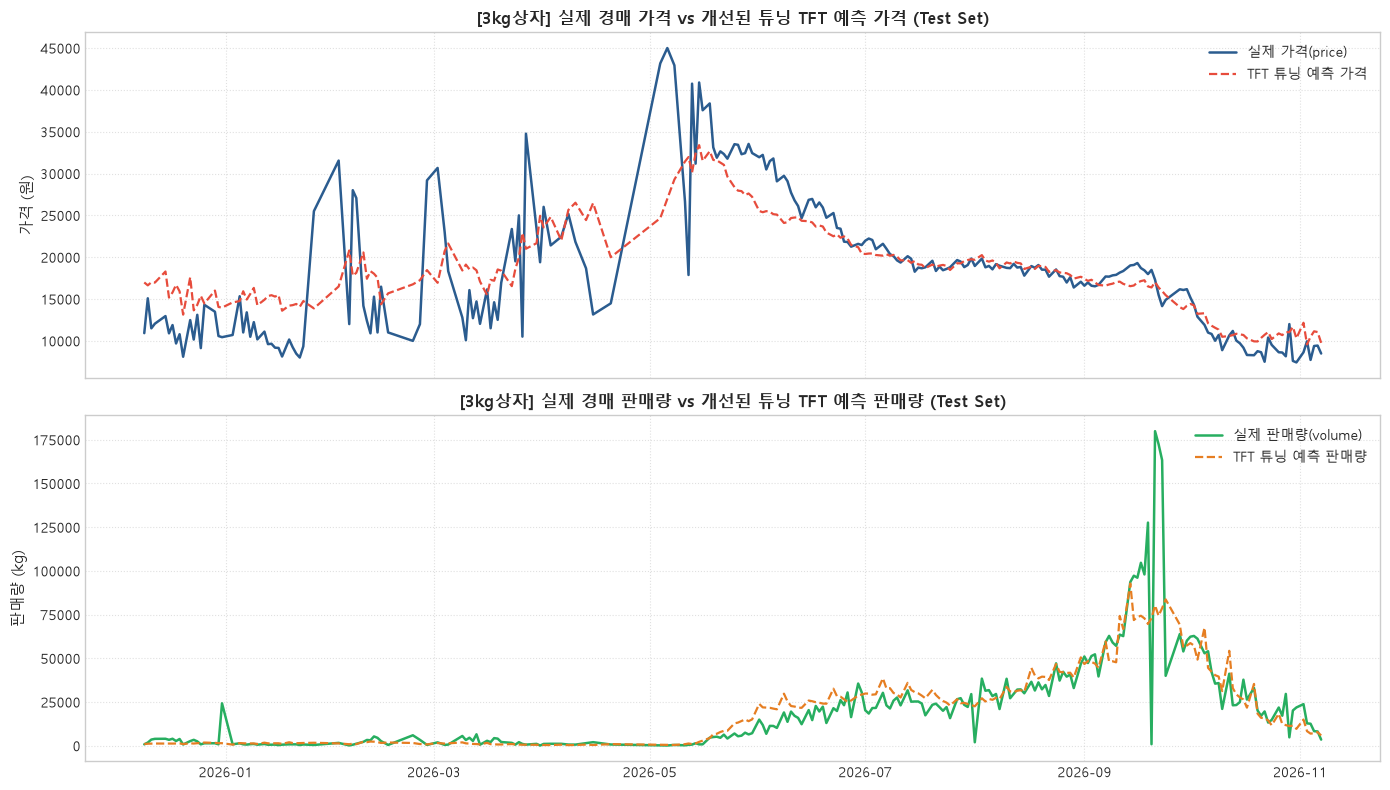

In [10]:
# 1. 개선된 Scikit-Learn 호환 TFTRegressor 래퍼 클래스 정의
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GridSearchCV, PredefinedSplit, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

class TFTRegressor(BaseEstimator, RegressorMixin):
    """
    Scikit-Learn GridSearchCV와 완전 호환되며,
    최적 가중치 복원(Early Checkpoint), Lookback 버퍼 예측 및 균형 WAPE 스코어를 지원하는
    개선된 PyTorch Temporal Fusion Transformer (TFT) 회귀 추정기.
    """
    def __init__(
        self,
        hidden_dim=64,
        num_heads=4,
        dropout=0.2,
        lr=0.001,
        seq_len=14,
        epochs=25,
        batch_size=128,
        val_ratio=0.15,
        past_cols=None,
        future_cols=None,
        device=None
    ):
        self.hidden_dim = hidden_dim
        self.num_heads = num_heads
        self.dropout = dropout
        self.lr = lr
        self.seq_len = seq_len
        self.epochs = epochs
        self.batch_size = batch_size
        self.val_ratio = val_ratio
        self.past_cols = past_cols
        self.future_cols = future_cols
        self.device = device
        
        # 학습 완료 후 생성되는 내부 속성
        self.model_ = None
        self.past_scaler_ = None
        self.future_scaler_ = None
        self.target_scaler_ = None
        self.device_ = None
        self.best_epoch_ = None
        self.best_val_loss_ = None

    def _resolve_cols(self, X):
        p_cols = self.past_cols if self.past_cols is not None else [
            c for c in X.columns if c not in ['price', 'volume', 'date', 'kind', 'type']
        ]
        f_cols = self.future_cols if self.future_cols is not None else p_cols
        return p_cols, f_cols

    def fit(self, X, y):
        # Multihead Attention 유효성 검증
        if self.hidden_dim % self.num_heads != 0:
            raise ValueError(
                f"hidden_dim({self.hidden_dim})은 num_heads({self.num_heads})로 나누어떨어져야 합니다."
            )

        self.device_ = self.device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        p_cols, f_cols = self._resolve_cols(X)

        y_arr = np.asarray(y, dtype=np.float32)
        if y_arr.ndim == 1:
            y_arr = y_arr.reshape(-1, 1)

        n_samples = len(X)
        # 내부 조기 최적 가중치 저장을 위한 검증 분할점 산출
        if self.val_ratio is not None and 0.0 < self.val_ratio < 0.5:
            split_idx = int(n_samples * (1.0 - self.val_ratio))
        else:
            split_idx = n_samples

        # 미래 누수 방지: 스케일러는 Train 구간으로만 fit
        self.past_scaler_ = StandardScaler()
        self.future_scaler_ = StandardScaler()
        self.target_scaler_ = StandardScaler()

        self.past_scaler_.fit(X[p_cols].iloc[:split_idx])
        self.future_scaler_.fit(X[f_cols].iloc[:split_idx])
        y_train_log = np.log1p(np.maximum(0.0, y_arr[:split_idx]))
        self.target_scaler_.fit(y_train_log)

        x_past_scaled = self.past_scaler_.transform(X[p_cols])
        x_future_scaled = self.future_scaler_.transform(X[f_cols])
        y_scaled = self.target_scaler_.transform(np.log1p(np.maximum(0.0, y_arr)))

        tr_indices = list(range(self.seq_len, split_idx))
        tr_ds = TFTSequenceDataset(x_past_scaled, x_future_scaled, y_scaled, tr_indices, self.seq_len)
        tr_loader = [
            (tr_ds.x_past[i:i + self.batch_size], tr_ds.x_future[i:i + self.batch_size], tr_ds.y[i:i + self.batch_size])
            for i in range(0, len(tr_ds), self.batch_size)
        ]

        has_val = (split_idx < n_samples)
        if has_val:
            va_indices = list(range(split_idx, n_samples))
            va_ds = TFTSequenceDataset(x_past_scaled, x_future_scaled, y_scaled, va_indices, self.seq_len)
            va_loader = [
                (va_ds.x_past[i:i + self.batch_size], va_ds.x_future[i:i + self.batch_size], va_ds.y[i:i + self.batch_size])
                for i in range(0, len(va_ds), self.batch_size)
            ]

        self.model_ = TemporalFusionTransformerModel(
            num_past_vars=len(p_cols),
            num_future_vars=len(f_cols),
            hidden_dim=self.hidden_dim,
            num_heads=self.num_heads,
            dropout=self.dropout,
            num_targets=y_arr.shape[1]
        ).to(self.device_)

        optimizer = torch.optim.AdamW(self.model_.parameters(), lr=self.lr, weight_decay=1e-4)
        criterion = nn.L1Loss()
        use_amp = (self.device_.type == 'cuda')
        scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

        best_loss = float('inf')
        best_state = None
        best_ep = self.epochs

        for epoch in range(1, self.epochs + 1):
            self.model_.train()
            for xp, xf, yb in tr_loader:
                xp, xf, yb = xp.to(self.device_), xf.to(self.device_), yb.to(self.device_)
                optimizer.zero_grad(set_to_none=True)
                with torch.amp.autocast(device_type=self.device_.type, enabled=use_amp):
                    preds, _, _ = self.model_(xp, xf)
                    loss = criterion(preds, yb)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(self.model_.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()

            # 에폭별 검증 손실 모니터링 및 최적 체크포인트 저장
            if has_val:
                self.model_.eval()
                val_losses = []
                with torch.no_grad():
                    for xp, xf, yb in va_loader:
                        xp, xf, yb = xp.to(self.device_), xf.to(self.device_), yb.to(self.device_)
                        with torch.amp.autocast(device_type=self.device_.type, enabled=use_amp):
                            preds, _, _ = self.model_(xp, xf)
                            val_losses.append(criterion(preds, yb).item())
                cur_loss = np.mean(val_losses) if val_losses else float('inf')
                if cur_loss < best_loss:
                    best_loss = cur_loss
                    best_ep = epoch
                    best_state = {k: v.detach().cpu().clone() for k, v in self.model_.state_dict().items()}

        # 검증 손실이 가장 우수했던 최적 상태 복원
        if best_state is not None:
            self.model_.load_state_dict(best_state)
            self.best_epoch_ = best_ep
            self.best_val_loss_ = best_loss

        return self

    def predict(self, X, lookback_df=None):
        """
        예측 함수:
        lookback_df가 주어지면 X 시작점 이전 과거 시계열을 결합하여
        더미 상수 패딩 없이 len(X) 전체에 대해 100% 완전한 시계열 예측을 생성합니다.
        """
        p_cols, f_cols = self._resolve_cols(X)
        
        if lookback_df is not None and len(lookback_df) >= self.seq_len:
            lookback_tail = lookback_df.iloc[-self.seq_len:]
            combined_X = pd.concat([lookback_tail, X], ignore_index=True)
            n_pad = len(lookback_tail)
        else:
            combined_X = X
            n_pad = 0

        x_past_scaled = self.past_scaler_.transform(combined_X[p_cols])
        x_future_scaled = self.future_scaler_.transform(combined_X[f_cols])

        n_combined = len(combined_X)
        dummy_targets = np.zeros((n_combined, self.target_scaler_.mean_.shape[0]), dtype=np.float32)
        
        if n_pad >= self.seq_len:
            indices = list(range(n_pad, n_combined))
        else:
            indices = list(range(self.seq_len, n_combined))

        ds = TFTSequenceDataset(x_past_scaled, x_future_scaled, dummy_targets, indices, self.seq_len)

        self.model_.eval()
        preds_list = []
        with torch.no_grad():
            for i in range(0, len(ds), self.batch_size):
                xp = ds.x_past[i:i + self.batch_size].to(self.device_)
                xf = ds.x_future[i:i + self.batch_size].to(self.device_)
                p, _, _ = self.model_(xp, xf)
                preds_list.append(p.float().cpu().numpy())

        if len(preds_list) > 0:
            preds_arr = np.vstack(preds_list)
            preds_orig = np.expm1(self.target_scaler_.inverse_transform(preds_arr))
            if n_pad >= self.seq_len:
                full_preds = preds_orig
            else:
                pad = np.repeat(preds_orig[:1], self.seq_len, axis=0)
                full_preds = np.vstack([pad, preds_orig])
        else:
            full_preds = np.zeros((len(X), self.target_scaler_.mean_.shape[0]))

        return full_preds[:len(X)]

    def score(self, X, y):
        """
        Scikit-Learn GridSearchCV 균형 스코어:
        가격(price)과 판매량(volume)의 WAPE 정확도를 50:50으로 독립 계산하여
        스케일 왜곡 없는 균형 정확도(Balanced Accuracy, %)를 반환합니다.
        """
        y_arr = np.asarray(y, dtype=np.float32)
        if y_arr.ndim == 1:
            y_arr = y_arr.reshape(-1, 1)

        preds = self.predict(X)
        
        # 가격 WAPE 정확도
        err_p = np.sum(np.abs(y_arr[:, 0] - preds[:, 0]))
        act_p = np.sum(np.abs(y_arr[:, 0])) + 1e-8
        acc_price = max(0.0, 100.0 - (err_p / act_p) * 100.0)

        # 판매량 WAPE 정확도
        if y_arr.shape[1] > 1:
            err_v = np.sum(np.abs(y_arr[:, 1] - preds[:, 1]))
            act_v = np.sum(np.abs(y_arr[:, 1])) + 1e-8
            acc_volume = max(0.0, 100.0 - (err_v / act_v) * 100.0)
            balanced_score = 0.5 * acc_price + 0.5 * acc_volume
        else:
            balanced_score = acc_price

        return float(balanced_score)


# 2. 하이퍼파라미터 튜닝 데이터 준비 (하우스감귤 대표 규격: 3kg상자)
tune_kind = '3kg상자'
train_df = kind_datasets[tune_kind]['train']
val_df = kind_datasets[tune_kind]['val']
test_df = kind_datasets[tune_kind]['test']

tune_df = pd.concat([train_df, val_df], ignore_index=True)
y_tune = tune_df[['price', 'volume']].values
print(f"=== [개선된 TFT GridSearchCV 튜닝 대상: '{tune_kind}'] ===")
print(f"Train 데이터: {len(train_df)}행, Val 데이터: {len(val_df)}행, Test 데이터: {len(test_df)}행")

# 3. 데이터 결핍 방지 시계열 검증(PredefinedSplit) 및 탐색 공간 설정
# 훈련 데이터 크기를 온전히 100%(1,635일) 보존 (-1: Train, 0: Val)
test_fold = np.concatenate([
    -1 * np.ones(len(train_df), dtype=int),
    0 * np.ones(len(val_df), dtype=int)
])
cv_strategy = PredefinedSplit(test_fold)

# 하이퍼파라미터 탐색 공간 (표현력과 수렴 속도의 균형)
# 하이퍼파라미터 탐색 공간 (10개 조합: 모델 용량, 헤드 수, 드롭아웃, 학습률, 배치 크기 다각화)
param_grid = [
    # 1. 경량 모델 (hidden_dim=32, num_heads=2) - 3개 조합
    {'hidden_dim': [32], 'num_heads': [2], 'dropout': [0.05, 0.1], 'lr': [1e-3], 'batch_size': [256]},
    {'hidden_dim': [32], 'num_heads': [2], 'dropout': [0.1], 'lr': [5e-4], 'batch_size': [128]},
    
    # 2. 표준 모델 (hidden_dim=64, num_heads=4) - 4개 조합
    {'hidden_dim': [64], 'num_heads': [4], 'dropout': [0.1], 'lr': [1e-3, 5e-4], 'batch_size': [256]},
    {'hidden_dim': [64], 'num_heads': [4], 'dropout': [0.05, 0.2], 'lr': [1e-3], 'batch_size': [128]},

    # 3. 고용량/심층 모델 (hidden_dim=128, num_heads=4) - 3개 조합
    {'hidden_dim': [128], 'num_heads': [4], 'dropout': [0.1], 'lr': [1e-3, 5e-4], 'batch_size': [256]},
    {'hidden_dim': [128], 'num_heads': [4], 'dropout': [0.2], 'lr': [5e-4], 'batch_size': [128]},
]

base_tft = TFTRegressor(
    past_cols=past_cols,
    future_cols=future_cols,
    epochs=25,          # 충분한 수렴을 위한 25 에폭 (내부 Early Best Checkpoint 포함)
    batch_size=128,
    val_ratio=0.15,
    seq_len=14
)

grid_search = GridSearchCV(
    estimator=base_tft,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring=None,       # TFTRegressor.score()의 균형 WAPE 정확도 사용
    verbose=1,
    n_jobs=1
)

from sklearn.model_selection import ParameterGrid
n_candidates = len(list(ParameterGrid(param_grid)))
print(f"\nGridSearchCV 최적화 시작 (PredefinedSplit 시계열 검증, 후보 파라미터 수: {n_candidates}개)...\n")
grid_search.fit(tune_df, y_tune)

# 4. 최적 파라미터 및 탐색 결과 요약 테이블
print(f"\n[GridSearchCV 최적화 완료]")
print(f"★ 최적 하이퍼파라미터 (Best Params): {grid_search.best_params_}")
print(f"★ 최적 검증 균형 정확도 (Best Score, Balanced Acc): {grid_search.best_score_:.2f}%")

cv_results_df = pd.DataFrame(grid_search.cv_results_)
param_cols = [c for c in cv_results_df.columns if c.startswith('param_')]
cols_to_show = ['rank_test_score', 'mean_test_score'] + param_cols
cv_summary = cv_results_df[cols_to_show].sort_values('rank_test_score').reset_index(drop=True)
col_rename = {'rank_test_score': '순위', 'mean_test_score': '검증 균형 정확도(%)'}
col_rename.update({c: c.replace('param_', '') for c in param_cols})
cv_summary = cv_summary.rename(columns=col_rename)
display(cv_summary)

# 5. 하이퍼파라미터 조합별 교차검증 성과 시각화
plt.figure(figsize=(9, 4.5))
sns.barplot(data=cv_summary, x=cv_summary.index + 1, y='검증 균형 정확도(%)', palette='Blues_r')
plt.title(f'TFT GridSearchCV 하이퍼파라미터 조합별 검증 정확도 ({tune_kind})', fontsize=13, fontweight='bold')
plt.xlabel('파라미터 후보 순위 (Rank)', fontsize=11)
plt.ylabel('검증 균형 정확도 (%)', fontsize=11)
plt.ylim([max(0, cv_summary['검증 균형 정확도(%)'].min() - 5), min(100, cv_summary['검증 균형 정확도(%)'].max() + 3)])
for i, row in cv_summary.iterrows():
    plt.text(i, row['검증 균형 정확도(%)'] + 0.3, f"{row['검증 균형 정확도(%)']:.1f}%", ha='center', fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 6. Lookback 버퍼를 결합한 독립 테스트셋(Test Set) 최종 평가 및 베이스라인 비교
best_tft_model = grid_search.best_estimator_
lookback_context = val_df.iloc[-best_tft_model.seq_len:]
test_preds = best_tft_model.predict(test_df, lookback_df=lookback_context)

y_test_actual = test_df[['price', 'volume']].values
eval_price = evaluate_predictions(y_test_actual[:, 0], test_preds[:, 0], model_name="TFT (GridSearched, Improved)", target_name="price", kind_name=tune_kind)
eval_volume = evaluate_predictions(y_test_actual[:, 1], test_preds[:, 1], model_name="TFT (GridSearched, Improved)", target_name="volume", kind_name=tune_kind)

tuned_eval_df = pd.DataFrame([eval_price, eval_volume])
print(f"\n=== [개선된 튜닝 TFT 모델의 독립 테스트셋(Test Set) 최종 성과] ===")
display(tuned_eval_df[['kind', 'Model', 'Target', '정확도(100-WAPE, %)', '대칭정확도(100-sMAPE, %)', '방향정확도(DA, %)', 'MAE', 'RMSE', 'R2']])

# 7. 실제값 vs 개선된 튜닝 TFT 예측값 비교 시각화 (테스트셋)
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
test_dates = pd.to_datetime(test_df['date'])

# 가격 비교
axes[0].plot(test_dates, y_test_actual[:, 0], label='실제 가격(price)', color='#2b5c8f', lw=1.8)
axes[0].plot(test_dates, test_preds[:, 0], label='TFT 튜닝 예측 가격', color='#e74c3c', lw=1.6, linestyle='--')
axes[0].set_title(f'[{tune_kind}] 실제 경매 가격 vs 개선된 튜닝 TFT 예측 가격 (Test Set)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('가격 (원)', fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# 판매량 비교
axes[1].plot(test_dates, y_test_actual[:, 1], label='실제 판매량(volume)', color='#27ae60', lw=1.8)
axes[1].plot(test_dates, test_preds[:, 1], label='TFT 튜닝 예측 판매량', color='#e67e22', lw=1.6, linestyle='--')
axes[1].set_title(f'[{tune_kind}] 실제 경매 판매량 vs 개선된 튜닝 TFT 예측 판매량 (Test Set)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('판매량 (kg)', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


## 10. 상자 및 파렛트 통합 규격 (3kg통합 · 5kg통합) 가격 및 거래물량 동시 예측

### [배경 및 통합 모델링 목적]
- **유통 현실 반영**: 경매 시장에서 동일 중량 규격인 3kg과 5kg 감귤은 **일반 골판지 상자(Box)**와 **파렛트(Pallet, 대량 적재 물량)** 단위로 분리되어 거래됩니다.
- **상호 보완 및 통합 분석 필요성**: 상자와 파렛트는 동일 품목 내에서 상호 보완재 및 대체재 역할을 하며, 두 단위를 통합할 경우 특정 포장 형태의 일별 거래량 변동 노이즈가 상쇄되어 **해당 중량 규격(3kg 전체, 5kg 전체)의 총 수급량과 가중평균 가격 흐름을 훨씬 안정적으로 예측**할 수 있습니다.

### [통합 집계 기준 및 수식]
1. **일별 총 거래물량(volume, kg)**:
   $$\text{volume} = \sum \text{Volume}_{\text{상자}} + \sum \text{Volume}_{\text{파렛트}}$$
2. **일별 가중평균 단위가격(unit\_price, 원/kg)**:
   $$\text{unit\_price} = \frac{\sum \text{Value}_{\text{상자}} + \sum \text{Value}_{\text{파렛트}}}{\text{volume}}$$
3. **규격 기준 가격(price, 원)**:
   - 3kg통합: $\text{price} = \text{unit\_price} \times 3.0$ (3kg 1단위 환산 가격)
   - 5kg통합: $\text{price} = \text{unit\_price} \times 5.0$ (5kg 1단위 환산 가격)

### [진행 순서]
1. 전국 32개 도매시장 경매 원본(`all_comb_df`)에서 3kg(상자+파렛트), 5kg(상자+파렛트) 일별 집계
2. 전체 시장 동향(`mkt_df`), 기상(`wx_daily_df`), 타품종 대체재(`field_daily_df`) 피처 결합 및 200+개 시계열 피처 생성
3. TFT 모델 훈련 (Train 70%, Val 15%, Test 15%) 및 최적 가중치 복원
4. 독립 테스트셋(Test Set) 가격 및 거래물량 동시 예측 및 성능 평가
5. 실제값 vs 예측값 시계열 추이 및 상관관계 산점도 시각화

=== [3kg 및 5kg 상자+파렛트 통합 규격 시계열 피처 테이블 구축] ===
  - [하우스감귤 3kg통합(상자+파렛트)]: 전체 1,588행 (Train: 1,111행, Val: 238행, Test: 239행)
  - [하우스감귤 5kg통합(상자+파렛트)]: 전체 1,596행 (Train: 1,117행, Val: 239행, Test: 240행)

=== [통합 규격 TFT 모델 학습 및 검증 시작] ===

>>> [하우스감귤 3kg통합(상자+파렛트)] TFT 학습 진행 중...
  -> [하우스감귤 3kg통합(상자+파렛트)] 학습 완료 (최적 Val Loss: 0.2482)

>>> [하우스감귤 5kg통합(상자+파렛트)] TFT 학습 진행 중...
  -> [하우스감귤 5kg통합(상자+파렛트)] 학습 완료 (최적 Val Loss: 0.2600)

=== [통합 규격(3kg통합 · 5kg통합) TFT 모델링 성능 평가지표 요약 (Test Set)] ===


,kind,Target,"정확도(100-WAPE, %)","대칭정확도(100-sMAPE, %)","방향정확도(DA, %)",MAE,RMSE,R2
0,하우스감귤 3kg통합(상자+파렛트),price,85.50,84.90,64.71,2658.76,4238.67,0.7153
1,하우스감귤 3kg통합(상자+파렛트),volume,72.45,58.81,62.61,6506.63,15476.41,0.7581
2,하우스감귤 5kg통합(상자+파렛트),price,87.99,87.99,52.72,2262.32,3441.82,0.6846
3,하우스감귤 5kg통합(상자+파렛트),volume,65.60,58.81,52.72,5681.18,12341.33,0.6828


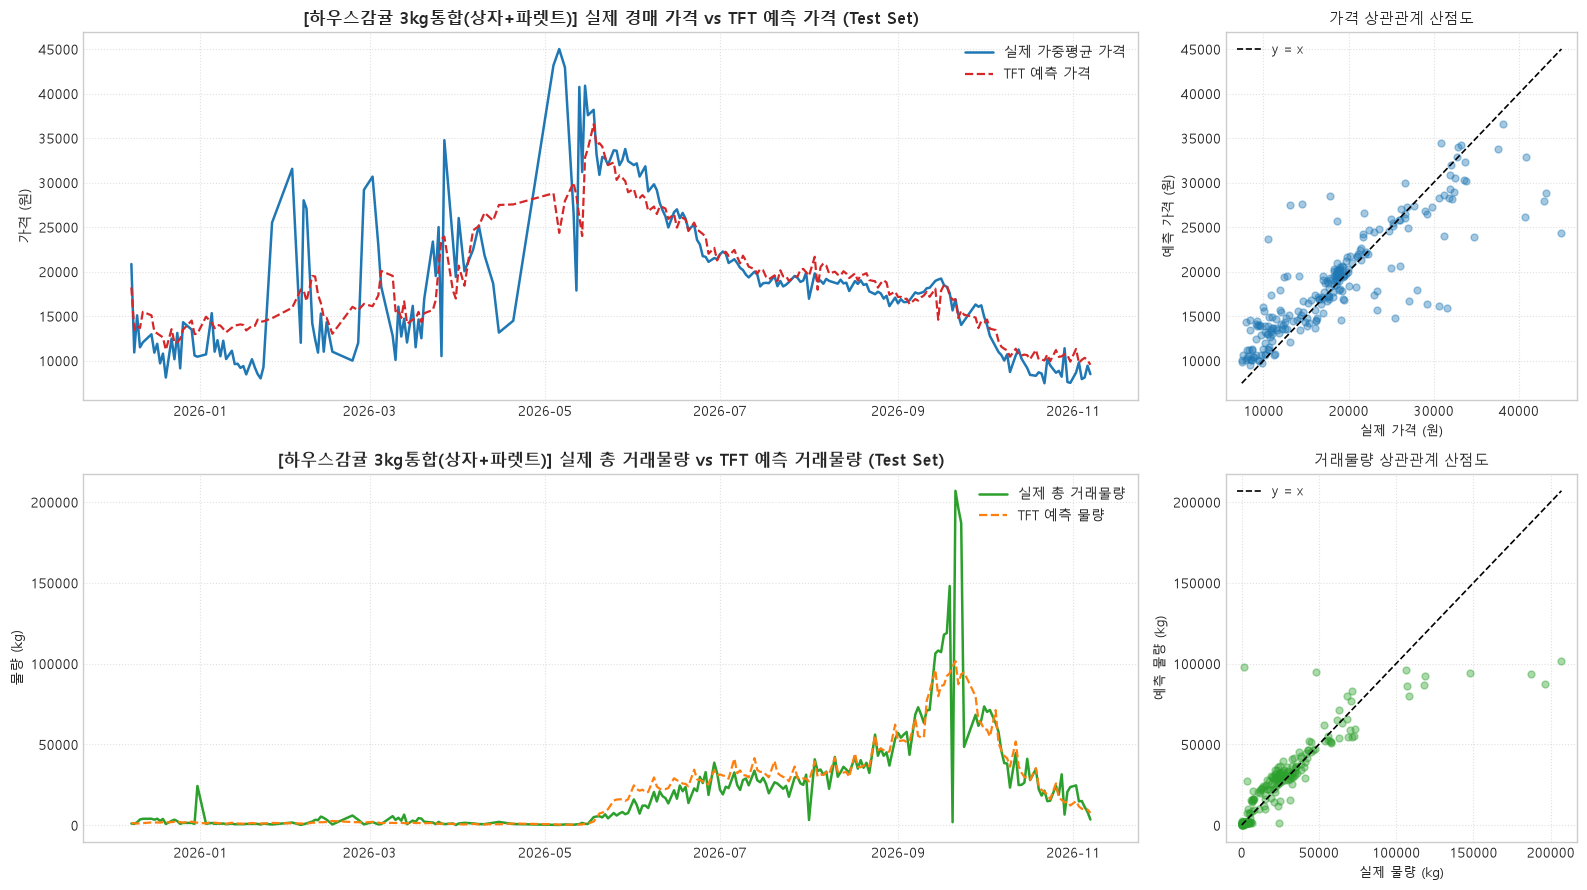

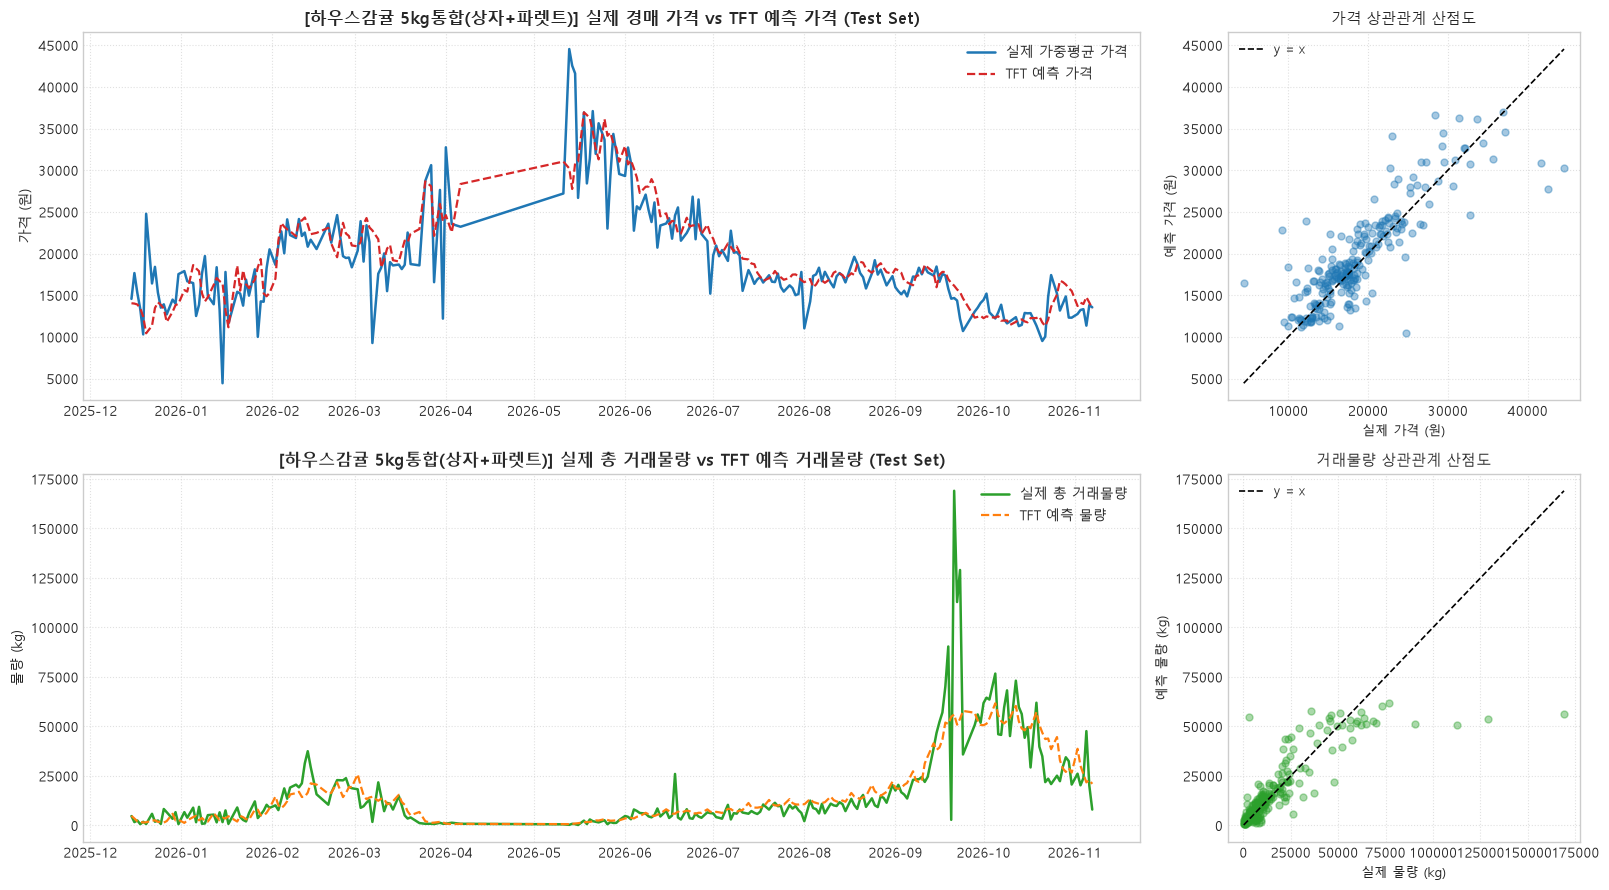


=== [최근 10개 거래일 기준 실제값 vs TFT 통합 예측치 샘플] ===


,통합단위,일자,실제 가격,TFT 예측 가격,가격 오차율,실제 물량,TFT 예측 물량,물량 오차율
0,3kg통합,2026-10-28,"8,191원","10,476원",27.9%,"31,458kg","15,594kg",50.4%
1,3kg통합,2026-10-29,"11,385원","10,719원",5.8%,"6,534kg","14,092kg",115.7%
2,3kg통합,2026-10-30,"7,593원","10,622원",39.9%,"20,715kg","14,514kg",29.9%
3,3kg통합,2026-10-31,"7,494원","9,881원",31.9%,"23,592kg","12,151kg",48.5%
4,3kg통합,2026-11-02,"8,656원","11,306원",30.6%,"24,612kg","14,821kg",39.8%
5,3kg통합,2026-11-03,"9,790원","9,731원",0.6%,"14,718kg","11,583kg",21.3%
6,3kg통합,2026-11-04,"7,918원","10,082원",27.3%,"14,955kg","10,127kg",32.3%
7,3kg통합,2026-11-05,"8,102원","10,309원",27.2%,"11,271kg","9,977kg",11.5%
8,3kg통합,2026-11-06,"9,429원","10,049원",6.6%,"8,148kg","9,681kg",18.8%
9,3kg통합,2026-11-07,"8,480원","9,524원",12.3%,"3,483kg","7,570kg",117.4%


In [11]:
# 1. 3kg 통합 및 5kg 통합 규격 데이터셋 구축 및 피처 엔지니어링
import matplotlib.pyplot as plt
import seaborn as sns

# 하우스감귤 시장 전체 동향 및 대체재 피처 테이블 준비
mkt_cols = ['date'] + [c for c in raw_df.columns if c.startswith('mkt_')]
mkt_df = raw_df[mkt_cols].drop_duplicates(subset=['date']).sort_values('date').reset_index(drop=True)
field_cols = ['date'] + [c for c in field_daily_df.columns if c.startswith('field_')]

# 통합 대상 규격 정의
COMBINED_SPECS = [
    {
        'variety': '하우스감귤',
        'name': '하우스감귤 3kg통합(상자+파렛트)',
        'short_name': '3kg통합',
        'units': ['3kg상자', '3kg파렛트'],
        'weight_kg': 3.0
    },
    {
        'variety': '하우스감귤',
        'name': '하우스감귤 5kg통합(상자+파렛트)',
        'short_name': '5kg통합',
        'units': ['5kg상자', '5kg파렛트'],
        'weight_kg': 5.0
    }
]

combined_datasets = {}
combined_results = {}
combined_eval_rows = []

print("=== [3kg 및 5kg 상자+파렛트 통합 규격 시계열 피처 테이블 구축] ===")

for spec in COMBINED_SPECS:
    v_name = spec['variety']
    c_name = spec['name']
    s_name = spec['short_name']
    units = spec['units']
    w_kg = spec['weight_kg']
    
    # 상자 + 파렛트 해당 경매 필터링 후 일별 합산 집계
    sub = all_comb_df[(all_comb_df['Variety'] == v_name) & (all_comb_df['Transaction Unit'].isin(units))].copy()
    daily_agg = sub.groupby('date', as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum'),
        market_count=('Wholesale Market', 'nunique')
    ).sort_values('date').reset_index(drop=True)
    
    daily_agg['kind'] = c_name
    daily_agg['type'] = v_name
    daily_agg['total_kg'] = daily_agg['volume']
    daily_agg['weight_kg'] = w_kg
    daily_agg['unit_price'] = (daily_agg['total_price'] / daily_agg['volume']).round(2)
    daily_agg['price'] = (daily_agg['unit_price'] * w_kg).round(2)
    daily_agg['total price'] = daily_agg['total_price']
    
    # 시장 점유율, 기상 피처 및 노지감귤 대체재 피처 병합
    daily_agg = daily_agg.merge(mkt_df, on='date', how='left')
    daily_agg['vol_share'] = daily_agg['total_kg'] / (daily_agg['mkt_total_kg'] + 1e-8)
    daily_agg['up_ratio'] = daily_agg['unit_price'] / (daily_agg['mkt_unit_price'] + 1e-8)
    daily_agg = daily_agg.merge(wx_daily_df, on='date', how='left')
    daily_agg = daily_agg.merge(field_daily_df[field_cols], on='date', how='left')
    
    # 캘린더, 래그, 이동평균 등 단일 품목 시계열 피처 생성
    c_feat = create_time_series_features_single_kind(daily_agg, kind_id=0)
    
    n_k = len(c_feat)
    tr_end = int(n_k * 0.70)
    va_end = int(n_k * 0.85)
    
    combined_datasets[c_name] = {
        'spec': spec,
        'feat': c_feat,
        'train': c_feat.iloc[:tr_end].copy(),
        'val': c_feat.iloc[tr_end:va_end].copy(),
        'test': c_feat.iloc[va_end:].copy(),
        'train_end': tr_end,
        'val_end': va_end
    }
    print(f"  - [{c_name}]: 전체 {n_k:,}행 (Train: {tr_end:,}행, Val: {va_end - tr_end:,}행, Test: {n_k - va_end:,}행)")

# 2. 통합 규격별 TFT 모델 학습 루프
print("\n=== [통합 규격 TFT 모델 학습 및 검증 시작] ===")
use_cuda = (device.type == 'cuda')

for spec in COMBINED_SPECS:
    c_name = spec['name']
    ds = combined_datasets[c_name]
    c_feat = ds['feat']
    tr_end, va_end = ds['train_end'], ds['val_end']
    
    print(f"\n>>> [{c_name}] TFT 학습 진행 중...")
    
    # 피처 및 타깃 정규화
    tft_df = c_feat[['date'] + list(dict.fromkeys(past_cols + future_cols))].copy()
    for c in ['price', 'volume', 'implied_price_mkt_lag1', 'implied_vol_mkt_lag1', 'field_up_rmean_7']:
        tft_df[c] = np.log1p(np.maximum(0.0, tft_df[c]))
        
    past_scaler = StandardScaler()
    future_scaler = StandardScaler()
    target_scaler = StandardScaler()
    
    past_scaled = np.vstack([
        past_scaler.fit_transform(tft_df.iloc[:tr_end][past_cols]),
        past_scaler.transform(tft_df.iloc[tr_end:][past_cols])
    ])
    future_scaled = np.vstack([ 
        future_scaler.fit_transform(tft_df.iloc[:tr_end][future_cols]),
        future_scaler.transform(tft_df.iloc[tr_end:][future_cols])
    ])
    target_scaled = np.vstack([
        target_scaler.fit_transform(tft_df.iloc[:tr_end][['price', 'volume']]),
        target_scaler.transform(tft_df.iloc[tr_end:][['price', 'volume']])
    ])
    
    seq_len = 14
    train_indices = list(range(seq_len, tr_end))
    val_indices = list(range(tr_end, va_end))
    test_indices = list(range(va_end, len(tft_df)))
    
    tr_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, train_indices, seq_len)
    va_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, val_indices, seq_len)
    te_ds = TFTSequenceDataset(past_scaled, future_scaled, target_scaled, test_indices, seq_len)
    
    train_loader = [(tr_ds.x_past[i:i+128], tr_ds.x_future[i:i+128], tr_ds.y[i:i+128]) for i in range(0, len(tr_ds), 128)]
    val_loader = [(va_ds.x_past[i:i+128], va_ds.x_future[i:i+128], va_ds.y[i:i+128]) for i in range(0, len(va_ds), 128)]
    test_loader = [(te_ds.x_past[i:i+128], te_ds.x_future[i:i+128], te_ds.y[i:i+128]) for i in range(0, len(te_ds), 128)]
    
    torch.manual_seed(42)
    if use_cuda:
        torch.cuda.manual_seed_all(42)
        
    tft_model = TemporalFusionTransformerModel(
        num_past_vars=len(past_cols),
        num_future_vars=len(future_cols),
        hidden_dim=64,
        num_heads=4,
        dropout=0.2,
        num_targets=2
    ).to(device)
    
    criterion = nn.L1Loss()
    optimizer = torch.optim.AdamW(tft_model.parameters(), lr=0.001, weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda', enabled=use_cuda)
    
    best_val_loss = float('inf')
    best_state = None
    epochs = 25
    
    for epoch in range(1, epochs + 1):
        tft_model.train()
        for x_p, x_f, y_b in train_loader:
            x_p, x_f, y_b = x_p.to(device), x_f.to(device), y_b.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, _, _ = tft_model(x_p, x_f)
                loss = criterion(preds, y_b)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(tft_model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            
        tft_model.eval()
        val_losses = []
        with torch.no_grad():
            for x_p, x_f, y_b in val_loader:
                x_p, x_f, y_b = x_p.to(device), x_f.to(device), y_b.to(device)
                with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                    preds, _, _ = tft_model(x_p, x_f)
                    val_losses.append(criterion(preds, y_b).item())
        v_loss = np.mean(val_losses) if val_losses else float('inf')
        if v_loss < best_val_loss:
            best_val_loss = v_loss
            best_state = {k: v.detach().cpu().clone() for k, v in tft_model.state_dict().items()}
            
    if best_state is not None:
        tft_model.load_state_dict(best_state)
        
    # 테스트셋 예측 (Lookback이 온전히 반영된 te_ds)
    tft_model.eval()
    test_preds_list = []
    with torch.no_grad():
        for x_p, x_f, _ in test_loader:
            x_p, x_f = x_p.to(device), x_f.to(device)
            with torch.amp.autocast(device_type=device.type, enabled=use_cuda):
                preds, _, _ = tft_model(x_p, x_f)
            test_preds_list.append(preds.float().cpu().numpy())
            
    test_preds_raw = np.vstack(test_preds_list)
    test_inv = np.expm1(target_scaler.inverse_transform(test_preds_raw))
    
    te_actual = c_feat.iloc[va_end:][['price', 'volume']].values
    eval_p = evaluate_predictions(te_actual[:, 0], test_inv[:, 0], model_name="TFT (통합)", target_name="price", kind_name=c_name)
    eval_v = evaluate_predictions(te_actual[:, 1], test_inv[:, 1], model_name="TFT (통합)", target_name="volume", kind_name=c_name)
    combined_eval_rows.extend([eval_p, eval_v])
    
    combined_results[c_name] = {
        'spec': spec,
        'model': tft_model,
        'test_df': c_feat.iloc[va_end:].copy(),
        'actual': te_actual,
        'preds': test_inv,
        'best_val_loss': best_val_loss
    }
    print(f"  -> [{c_name}] 학습 완료 (최적 Val Loss: {best_val_loss:.4f})")

# 3. 통합 규격 TFT 모델링 최종 평가 결과 테이블
print("\n=== [통합 규격(3kg통합 · 5kg통합) TFT 모델링 성능 평가지표 요약 (Test Set)] ===")
combined_eval_df = pd.DataFrame(combined_eval_rows)
cols_summary = ['kind', 'Target', '정확도(100-WAPE, %)', '대칭정확도(100-sMAPE, %)', '방향정확도(DA, %)', 'MAE', 'RMSE', 'R2']
display(combined_eval_df[cols_summary])

# 4. 통합 규격 실제값 vs TFT 예측값 시계열 추이 비교 시각화
for spec in COMBINED_SPECS:
    c_name = spec['name']
    res = combined_results[c_name]
    t_dates = pd.to_datetime(res['test_df']['date'])
    act = res['actual']
    prd = res['preds']
    w_kg = spec['weight_kg']
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 9), gridspec_kw={'width_ratios': [3, 1]})
    
    # 가격 시계열 비교
    axes[0, 0].plot(t_dates, act[:, 0], label='실제 가중평균 가격', color='#1f77b4', lw=1.8)
    axes[0, 0].plot(t_dates, prd[:, 0], label='TFT 예측 가격', color='#d62728', lw=1.6, linestyle='--')
    axes[0, 0].set_title(f'[{c_name}] 실제 경매 가격 vs TFT 예측 가격 (Test Set)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('가격 (원)', fontsize=10)
    axes[0, 0].legend(loc='upper right')
    axes[0, 0].grid(True, linestyle=':', alpha=0.6)
    
    # 가격 산점도
    axes[0, 1].scatter(act[:, 0], prd[:, 0], alpha=0.4, color='#1f77b4', s=25)
    p_min, p_max = min(act[:, 0].min(), prd[:, 0].min()), max(act[:, 0].max(), prd[:, 0].max())
    axes[0, 1].plot([p_min, p_max], [p_min, p_max], 'k--', lw=1.2, label='y = x')
    axes[0, 1].set_title('가격 상관관계 산점도', fontsize=11)
    axes[0, 1].set_xlabel('실제 가격 (원)', fontsize=9)
    axes[0, 1].set_ylabel('예측 가격 (원)', fontsize=9)
    axes[0, 1].legend(loc='upper left', fontsize=9)
    axes[0, 1].grid(True, linestyle=':', alpha=0.6)
    
    # 판매량 시계열 비교
    axes[1, 0].plot(t_dates, act[:, 1], label='실제 총 거래물량', color='#2ca02c', lw=1.8)
    axes[1, 0].plot(t_dates, prd[:, 1], label='TFT 예측 물량', color='#ff7f0e', lw=1.6, linestyle='--')
    axes[1, 0].set_title(f'[{c_name}] 실제 총 거래물량 vs TFT 예측 거래물량 (Test Set)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('물량 (kg)', fontsize=10)
    axes[1, 0].legend(loc='upper right')
    axes[1, 0].grid(True, linestyle=':', alpha=0.6)
    
    # 판매량 산점도
    axes[1, 1].scatter(act[:, 1], prd[:, 1], alpha=0.4, color='#2ca02c', s=25)
    v_min, v_max = min(act[:, 1].min(), prd[:, 1].min()), max(act[:, 1].max(), prd[:, 1].max())
    axes[1, 1].plot([v_min, v_max], [v_min, v_max], 'k--', lw=1.2, label='y = x')
    axes[1, 1].set_title('거래물량 상관관계 산점도', fontsize=11)
    axes[1, 1].set_xlabel('실제 물량 (kg)', fontsize=9)
    axes[1, 1].set_ylabel('예측 물량 (kg)', fontsize=9)
    axes[1, 1].legend(loc='upper left', fontsize=9)
    axes[1, 1].grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

# 5. 최근 10개 거래일 기준 실제값 vs TFT 통합 예측치 샘플
print("\n=== [최근 10개 거래일 기준 실제값 vs TFT 통합 예측치 샘플] ===")
sample_dfs = []
for spec in COMBINED_SPECS:
    c_name = spec['name']
    res = combined_results[c_name]
    t_df = res['test_df'].tail(10).copy()
    act = res['actual'][-10:]
    prd = res['preds'][-10:]
    
    sub_df = pd.DataFrame({
        '통합단위': spec['short_name'],
        '일자': t_df['date'].dt.strftime('%Y-%m-%d').values,
        '실제 가격': [f"{int(a):,}원" for a in act[:, 0]],
        'TFT 예측 가격': [f"{int(p):,}원" for p in prd[:, 0]],
        '가격 오차율': [f"{abs(a - p) / (a + 1e-8) * 100:.1f}%" for a, p in zip(act[:, 0], prd[:, 0])],
        '실제 물량': [f"{int(a):,}kg" for a in act[:, 1]],
        'TFT 예측 물량': [f"{int(p):,}kg" for p in prd[:, 1]],
        '물량 오차율': [f"{abs(a - p) / (a + 1e-8) * 100:.1f}%" for a, p in zip(act[:, 1], prd[:, 1])]
    })
    sample_dfs.append(sub_df)

display(pd.concat(sample_dfs, ignore_index=True))


## 11. 거래물량 극소(평균 거래물량의 10% 이하) 구간 시계열 탐지 및 가격·물량 변동성 분석

### [분석 배경 및 목적]
- 농산물 경매 시장에서는 특정 시기(출하 초기·말기, 비수기, 명절 직후 공백기 등)에 **일별 출하 물량이 평소 수준을 크게 밑도는 극소 거래일(Extreme Low Volume Days)**이 발생합니다.
- 본 섹션에서는 거래물량이 **전체 기간 일평균 거래물량의 10% 이하($\text{Volume} \le 0.10 \times \bar{V}$)**로 급감하는 시점을 시계열상에서 탐지하고,
  1. 거래물량 시계열 추이 상에서 10% 이하 발생 시점을 직관적으로 식별,
  2. 해당 극소 물량 거래일이 연중 몇 월(계절성)에 집중되는지 분석,
  3. 물량이 10% 이하로 급감했을 때 거래가격(Price)의 왜곡(희소성 프리미엄 및 변동성 폭증) 여부를 통계적으로 비교 검증합니다.

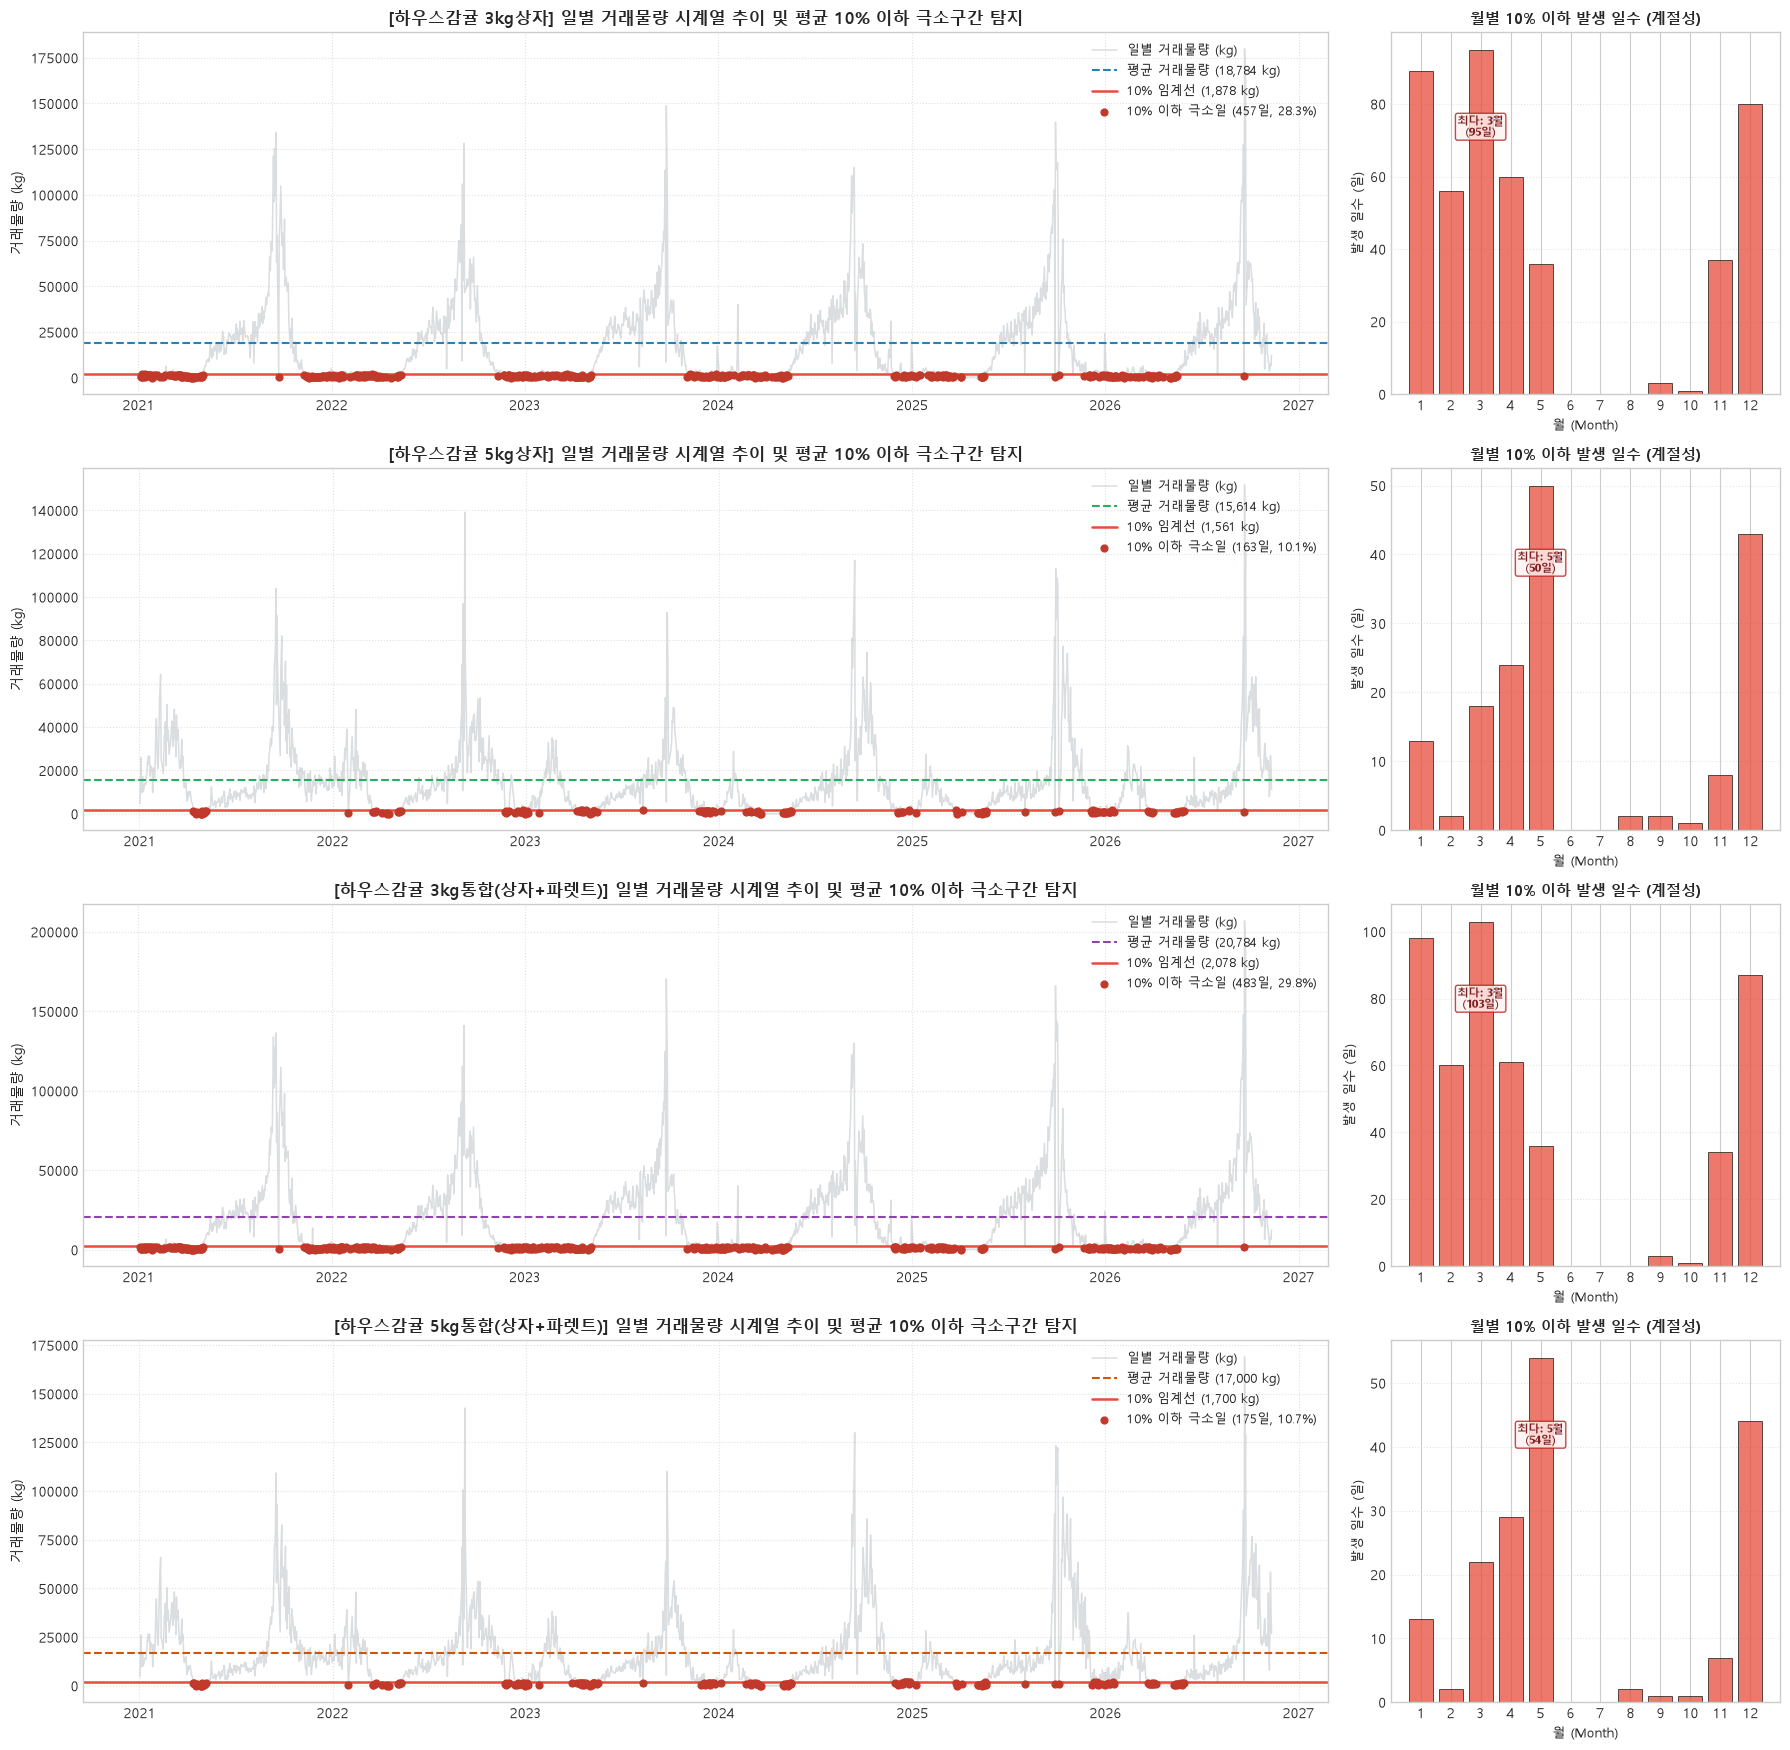


=== [정상 거래일 vs 평균 거래물량 10% 이하 극소 거래일 비교 요약] ===


,규격(kind),전체 거래일수,일평균 물량(kg),10% 기준치(kg),극소(<=10%) 일수,정상일 평균가격,극소일 평균가격,극소일 가격변동(표준편차),극소일 평균물량
0,하우스감귤 3kg상자,"1,615일",18784.2,1878.4,457일 (28.3%),"18,322원","21,214원","±9,720원",894kg
1,하우스감귤 5kg상자,"1,617일",15614.3,1561.4,163일 (10.1%),"17,940원","22,638원","±10,486원",826kg
2,하우스감귤 3kg통합(상자+파렛트),"1,621일",20783.9,2078.4,483일 (29.8%),"18,201원","20,779원","±9,112원",978kg
3,하우스감귤 5kg통합(상자+파렛트),"1,629일",17000.1,1700.0,175일 (10.7%),"17,791원","22,981원","±10,524원",912kg


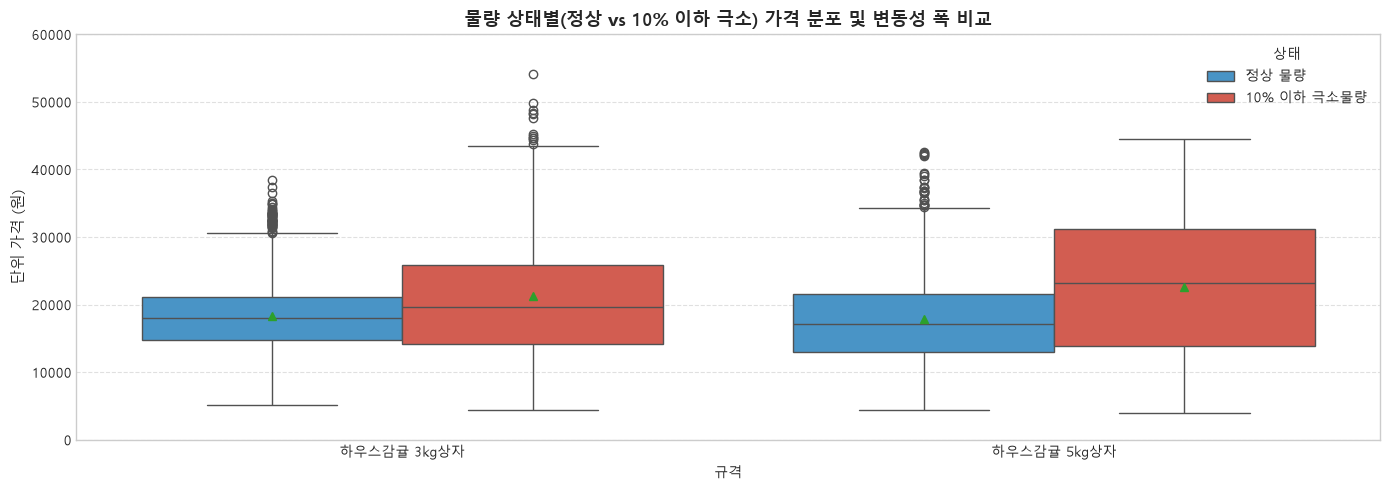

In [12]:
# 1. 평균 거래물량의 10% 이하 극소 거래일 시계열 탐지 및 시각화
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 분석 대상 규격 정의 (3kg상자, 5kg상자 및 3kg통합, 5kg통합)
ht_raw_all = all_comb_df[all_comb_df['Variety'] == '하우스감귤'].copy()

target_specs_for_low_vol = [
    {'title': '하우스감귤 3kg상자', 'sub': ht_raw_all[ht_raw_all['Transaction Unit'] == '3kg상자'], 'weight': 3.0, 'color': '#2980b9'},
    {'title': '하우스감귤 5kg상자', 'sub': ht_raw_all[ht_raw_all['Transaction Unit'] == '5kg상자'], 'weight': 5.0, 'color': '#27ae60'},
    {'title': '하우스감귤 3kg통합(상자+파렛트)', 'sub': ht_raw_all[ht_raw_all['Transaction Unit'].isin(['3kg상자', '3kg파렛트'])], 'weight': 3.0, 'color': '#8e44ad'},
    {'title': '하우스감귤 5kg통합(상자+파렛트)', 'sub': ht_raw_all[ht_raw_all['Transaction Unit'].isin(['5kg상자', '5kg파렛트'])], 'weight': 5.0, 'color': '#d35400'}
]

low_vol_summary_rows = []

# 4개 규격에 대한 시계열 추이 + 월별 계절성 2열 서브플롯 구성
fig, axes = plt.subplots(len(target_specs_for_low_vol), 2, figsize=(18, 4.4 * len(target_specs_for_low_vol)), gridspec_kw={'width_ratios': [3.2, 1]})

for idx, item in enumerate(target_specs_for_low_vol):
    t_name = item['title']
    sub_df = item['sub']
    w_kg = item['weight']
    main_color = item['color']
    
    # 일별 거래물량 및 가중평균 가격 집계
    daily = sub_df.groupby('date', as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum')
    ).sort_values('date').reset_index(drop=True)
    daily['price'] = (daily['total_price'] / daily['volume']) * w_kg
    
    mean_vol = daily['volume'].mean()
    th_10 = mean_vol * 0.10
    
    # 10% 이하 마스크
    low_mask = daily['volume'] <= th_10
    norm_mask = ~low_mask
    
    n_total = len(daily)
    n_low = low_mask.sum()
    pct_low = (n_low / n_total) * 100.0
    
    # 통계 요약 저장
    low_vol_summary_rows.append({
        '규격(kind)': t_name,
        '전체 거래일수': f"{n_total:,}일",
        '일평균 물량(kg)': round(mean_vol, 1),
        '10% 기준치(kg)': round(th_10, 1),
        '극소(<=10%) 일수': f"{n_low:,}일 ({pct_low:.1f}%)",
        '정상일 평균가격': f"{int(daily.loc[norm_mask, 'price'].mean()):,}원",
        '극소일 평균가격': f"{int(daily.loc[low_mask, 'price'].mean()):,}원",
        '극소일 가격변동(표준편차)': f"±{int(daily.loc[low_mask, 'price'].std()):,}원",
        '극소일 평균물량': f"{int(daily.loc[low_mask, 'volume'].mean()):,}kg"
    })
    
    # 좌측: 시계열 거래물량 곡선 및 10% 이하 하이라이트
    ax_ts = axes[idx, 0]
    ax_ts.plot(daily['date'], daily['volume'], color='#bdc3c7', alpha=0.55, lw=1.1, label='일별 거래물량 (kg)')
    ax_ts.axhline(mean_vol, color=main_color, linestyle='--', lw=1.5, label=f'평균 거래물량 ({mean_vol:,.0f} kg)')
    ax_ts.axhline(th_10, color='#e74c3c', linestyle='-', lw=1.8, label=f'10% 임계선 ({th_10:,.0f} kg)')
    
    # 10% 이하 극소 거래일 강조 마커 (적색 포인트)
    ax_ts.scatter(daily.loc[low_mask, 'date'], daily.loc[low_mask, 'volume'], color='#c0392b', s=24, zorder=5, label=f'10% 이하 극소일 ({n_low:,}일, {pct_low:.1f}%)')
    
    ax_ts.set_title(f'[{t_name}] 일별 거래물량 시계열 추이 및 평균 10% 이하 극소구간 탐지', fontsize=12, fontweight='bold')
    ax_ts.set_ylabel('거래물량 (kg)', fontsize=10)
    ax_ts.legend(loc='upper right', fontsize=9, framealpha=0.9)
    ax_ts.grid(True, linestyle=':', alpha=0.6)
    
    # 우측: 월별 극소 거래일 발생 빈도 (계절성 분석)
    ax_m = axes[idx, 1]
    low_months = daily.loc[low_mask, 'date'].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
    bars = ax_m.bar(range(1, 13), low_months, color='#e74c3c', alpha=0.75, edgecolor='black', lw=0.6)
    ax_m.set_title('월별 10% 이하 발생 일수 (계절성)', fontsize=11, fontweight='bold')
    ax_m.set_xlabel('월 (Month)', fontsize=9)
    ax_m.set_ylabel('발생 일수 (일)', fontsize=9)
    ax_m.set_xticks(range(1, 13))
    ax_m.grid(axis='y', linestyle=':', alpha=0.5)
    
    # 최다 발생 월 표시
    max_m = low_months.idxmax()
    max_val = low_months.max()
    if max_val > 0:
        ax_m.annotate(f'최다: {max_m}월\n({max_val}일)', xy=(max_m, max_val), xytext=(max_m, max_val * 0.75),
                      ha='center', fontsize=8, fontweight='bold', color='#7f1d1d',
                      bbox=dict(boxstyle='round,pad=0.2', facecolor='#fef2f2', edgecolor='#b91c1c', alpha=0.8))

plt.tight_layout()
plt.show()

# 2. 정상 거래일 vs 10% 이하 극소 거래일 통계 비교표
print("\n=== [정상 거래일 vs 평균 거래물량 10% 이하 극소 거래일 비교 요약] ===")
low_vol_summary_df = pd.DataFrame(low_vol_summary_rows)
display(low_vol_summary_df)

# 3. 거래물량 급감 시 가격 영향(희소성 프리미엄 & 가격 변동성 폭증) 시각화
plt.figure(figsize=(14, 5))
plot_data = []
for item in target_specs_for_low_vol[:2]:
    t_name = item['title']
    sub_df = item['sub']
    w_kg = item['weight']
    daily = sub_df.groupby('date', as_index=False).agg(
        volume=('Total Trading Volume', 'sum'),
        total_price=('Total Trading Value', 'sum')
    ).sort_values('date').reset_index(drop=True)
    daily['price'] = (daily['total_price'] / daily['volume']) * w_kg
    th_10 = daily['volume'].mean() * 0.10
    daily['상태'] = np.where(daily['volume'] <= th_10, '10% 이하 극소물량', '정상 물량')
    daily['규격'] = t_name
    plot_data.append(daily[['규격', '상태', 'price']])

comp_df = pd.concat(plot_data, ignore_index=True)
sns.boxplot(data=comp_df, x='규격', y='price', hue='상태', palette={'정상 물량': '#3498db', '10% 이하 극소물량': '#e74c3c'}, showmeans=True)
plt.title('물량 상태별(정상 vs 10% 이하 극소) 가격 분포 및 변동성 폭 비교', fontsize=13, fontweight='bold')
plt.ylabel('단위 가격 (원)', fontsize=11)
plt.ylim(0, 60000)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
